# Flood Mapping with Sentinel-1 (Sen1Floods11)
*Cells re-ordered so the notebook runs top-to-bottom. Sections 1–11: data prep and models. Section 12: Objective 1 (Ghana multi-temporal analysis). Appendix: scratch / unused cells.*

## 1. Setup

In [17]:
!pip install rasterio matplotlib numpy torch torchvision

In [18]:
import os
import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

## 2. Explore one sample tile (Bolivia_103757)

In [19]:

from pathlib import Path

PROJECT_ROOT = Path.cwd()
DATASET_DIR = PROJECT_ROOT / "Sen1Floods11" / "v1.1"
dataset_dir = DATASET_DIR
print("Working directory:", PROJECT_ROOT)
print("Dataset exists:", DATASET_DIR.exists())


Working directory: /Users/pramodithakathari/GeoMind-AI-v7
Dataset exists: True


In [20]:
from pathlib import Path

DATA_ROOT = Path.home() / "Desktop" / "Sen1Floods11"

print("Dataset folder exists:", DATA_ROOT.exists())
print("Contents:")

for item in DATA_ROOT.iterdir():
    print(item.name)

Dataset folder exists: True
Contents:
.DS_Store
v1.1


In [21]:
from pathlib import Path

DATA_ROOT = Path.home() / "Desktop" / "Sen1Floods11"
DATASET_DIR = DATA_ROOT / "v1.1"

print("Dataset version exists:", DATASET_DIR.exists())

for item in DATASET_DIR.iterdir():
    print(item.name)

Dataset version exists: True
LabelHand
S1Hand
Augmented_S1
JRCWaterHand
Augmented_Labels
splits


In [22]:
s1_folder = DATA_ROOT / "data" / "flood_events"/"HandLabeled"/"S1Hand"
label_folder = DATA_ROOT / "data" / "flood_events" / "HandLabeled" / "LabelHand"

image_name = "Bolivia_103757_S1Hand.tif"
label_name = "Bolivia_103757_LabelHand.tif"

image_path = os.path.join(s1_folder, image_name)
label_path = os.path.join(label_folder, label_name)

len(image_name)

25

In [23]:
from pathlib import Path
import os

DATA_ROOT = Path.home() / "Desktop" / "Sen1Floods11"
DATASET_DIR = DATA_ROOT / "v1.1"

s1_folder = DATASET_DIR / "S1Hand"
label_folder = DATASET_DIR / "LabelHand"

image_name = "Bolivia_103757_S1Hand.tif"
label_name = "Bolivia_103757_LabelHand.tif"

image_path = s1_folder / image_name
label_path = label_folder / label_name

print("Image folder exists:", s1_folder.exists())
print("Label folder exists:", label_folder.exists())
print("Image file exists:", image_path.exists())
print("Label file exists:", label_path.exists())

Image folder exists: True
Label folder exists: True
Image file exists: False
Label file exists: False


In [24]:
from pathlib import Path

DATASET_DIR = Path.home() / "Desktop" / "Sen1Floods11" / "v1.1"

for folder_name in ["S1Hand", "LabelHand"]:
    folder = DATASET_DIR / folder_name
    print(f"\n--- {folder_name} ---")

    files = list(folder.glob("*Bolivia_103757*"))
    print("Matching files:", len(files))

    for file in files[:10]:
        print(file.name)

    if not files:
        print("Sample filenames:")
        for file in list(folder.iterdir())[:5]:
            print(file.name)


--- S1Hand ---
Matching files: 0
Sample filenames:
S1Hand
Test_S1
Augmented_S1
Validation_S1

--- LabelHand ---
Matching files: 0
Sample filenames:
LabelHand
Test_Labels
Validation_Labels
Augmented_Labels


In [25]:
from pathlib import Path

DATASET_DIR = Path.home() / "Desktop" / "Sen1Floods11" / "v1.1"

for folder_name in ["S1Hand", "LabelHand"]:
    root = DATASET_DIR / folder_name
    print(f"\n===== {folder_name} =====")

    for file in root.rglob("*.tif"):
        print(file.relative_to(DATASET_DIR))
        if sum(1 for _ in root.rglob("*.tif")) > 30:
            break


===== S1Hand =====
S1Hand/S1Hand/Mekong_922373_S1Hand.tif

===== LabelHand =====
LabelHand/LabelHand/Mekong_382276_LabelHand.tif


In [26]:
from pathlib import Path

DATASET_DIR = Path.home() / "Desktop" / "Sen1Floods11" / "v1.1"

s1_folder = DATASET_DIR / "S1Hand" / "S1Hand"
label_folder = DATASET_DIR / "LabelHand" / "LabelHand"

print("Image folder:", s1_folder.exists())
print("Label folder:", label_folder.exists())

print("\nImage examples:")
for f in list(s1_folder.glob("*.tif"))[:5]:
    print(f.name)

print("\nLabel examples:")
for f in list(label_folder.glob("*.tif"))[:5]:
    print(f.name)

Image folder: True
Label folder: True

Image examples:
Mekong_922373_S1Hand.tif
Paraguay_12870_S1Hand.tif
Paraguay_934240_S1Hand.tif
Sri-Lanka_249079_S1Hand.tif
Somalia_685158_S1Hand.tif

Label examples:
Mekong_382276_LabelHand.tif
Paraguay_7894_LabelHand.tif
USA_19225_LabelHand.tif
Sri-Lanka_92824_LabelHand.tif
USA_366607_LabelHand.tif


In [27]:
from pathlib import Path

DATASET_DIR = Path.home() / "Desktop" / "Sen1Floods11" / "v1.1"

s1_folder = DATASET_DIR / "S1Hand" / "S1Hand"
label_folder = DATASET_DIR / "LabelHand" / "LabelHand"

image_ids = {
    f.name.replace("_S1Hand.tif", "")
    for f in s1_folder.glob("*_S1Hand.tif")
}
label_ids = {
    f.name.replace("_LabelHand.tif", "")
    for f in label_folder.glob("*_LabelHand.tif")
}

common_ids = sorted(image_ids & label_ids)

print("Images:", len(image_ids))
print("Labels:", len(label_ids))
print("Matching pairs:", len(common_ids))

for tile_id in common_ids[:10]:
    print(tile_id)

Images: 446
Labels: 446
Matching pairs: 446
Bolivia_103757
Bolivia_129334
Bolivia_195474
Bolivia_23014
Bolivia_233925
Bolivia_242570
Bolivia_290290
Bolivia_294583
Bolivia_312675
Bolivia_314919


In [28]:
import os

print(os.path.exists(
    "/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/S1Hand/S1Hand/Bolivia_103757_S1Hand.tif"
))


image_path = "/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/S1Hand/S1Hand/Bolivia_103757_S1Hand.tif"

True


In [29]:
### dataset info
with rasterio.open(image_path) as src:
    print("file:",image_name[0])
    print("width:",src.width)
    print("height:",src.height)
    print("no.of bands:",src.count)
    print("data type:",src.dtypes)
    
    
    image = src.read()
    print("Image shape:", image.shape)
    print("Minimum value:", image.min())
    print("Maximum value:", image.max())
    for i in range(src.count):
        print(f"Band {i+1}:")
        print("  Min:", image[i].min())
        print("  Max:", image[i].max())
        print("  Mean:", image[i].mean())

file: B
width: 512
height: 512
no.of bands: 2
data type: ('float32', 'float32')
Image shape: (2, 512, 512)
Minimum value: nan
Maximum value: nan
Band 1:
  Min: nan
  Max: nan
  Mean: nan
Band 2:
  Min: nan
  Max: nan
  Mean: nan


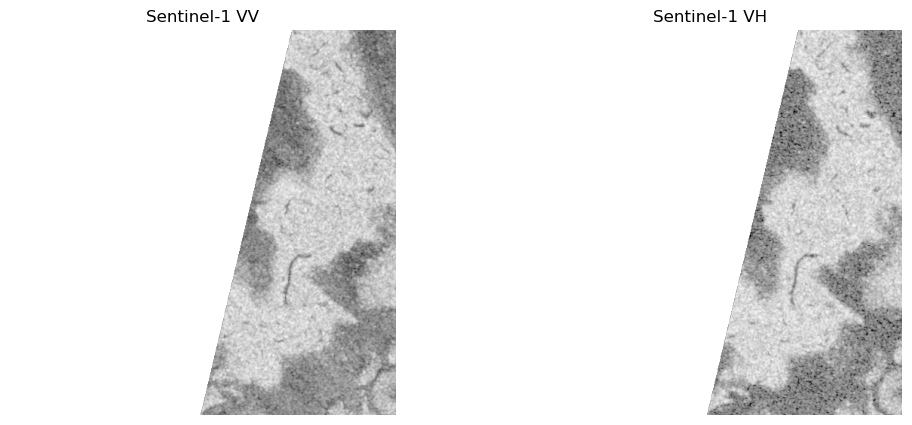

In [30]:
### vv and vh representation
import matplotlib.pyplot as plt

with rasterio.open(image_path) as src:
    vv = src.read(1)
    vh = src.read(2)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(vv, cmap="gray")
plt.title("Sentinel-1 VV")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(vh, cmap="gray")
plt.title("Sentinel-1 VH")
plt.axis("off")

plt.show()

In [31]:
print("VV mean:", np.nanmean(vv))
print("VH mean:", np.nanmean(vh))

print("VV range:", np.nanmin(vv), np.nanmax(vv))
print("VH range:", np.nanmin(vh), np.nanmax(vh))

VV mean: -13.010354
VH mean: -19.286884
VV range: -40.82144 -0.69059896
VH range: -48.24836 -6.9946613


In [32]:
print("VV - valid pixels:", np.sum(np.isfinite(vv)))
print("VV - total pixels:", vv.size)

print("VH - valid pixels:", np.sum(np.isfinite(vh)))
print("VH - total pixels:", vh.size)

print("\nVV - NaN pixels:", np.sum(np.isnan(vv)))
print("VH - NaN pixels:", np.sum(np.isnan(vh)))

VV - valid pixels: 101623
VV - total pixels: 262144
VH - valid pixels: 101623
VH - total pixels: 262144

VV - NaN pixels: 160521
VH - NaN pixels: 160521


In [33]:
label_path = "/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/LabelHand/LabelHand/Bolivia_103757_LabelHand.tif"

In [34]:
with rasterio.open(label_path) as src:
    label = src.read(1)

print("Label shape:", label.shape)
print("Label data type:", label.dtype)
print("Unique label values:", np.unique(label))

Label shape: (512, 512)
Label data type: int16
Unique label values: [-1  0  1]


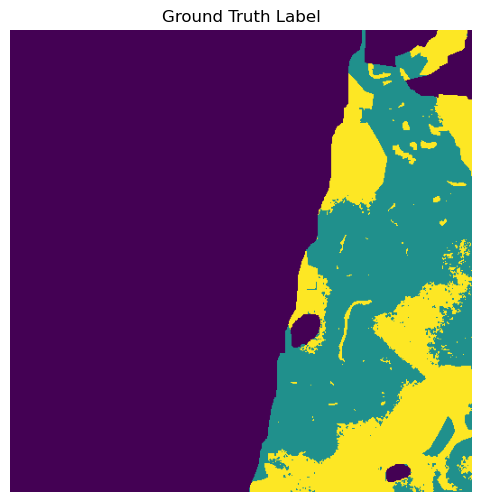

In [35]:
### Ground-Truth Label Inspection
plt.figure(figsize=(6, 6))

plt.imshow(label)
plt.title("Ground Truth Label")
plt.axis("off")

plt.show()

In [36]:
from pathlib import Path

root = Path("/Users/pramodithakathari/Desktop/Sen1Floods11")

matches = list(root.rglob("Bolivia_103757_JRCWaterHand.tif"))
print(matches)

[PosixPath('/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/JRCWaterHand/JRCWaterHand/Bolivia_103757_JRCWaterHand.tif')]


In [37]:
jrc_folder = matches[0].parent

In [38]:
import os
import rasterio
import numpy as np
jrc_folder = DATA_ROOT / "data" / "flood_events"/"HandLabeled"/"JRCWaterHand" # provides permanent-water info
jrc_folder_p = matches[0].parent

jrc_name = "Bolivia_103757_JRCWaterHand.tif"
jrc_path = os.path.join(jrc_folder_p, jrc_name)

with rasterio.open(jrc_path) as src:
    jrc = src.read(1)

print("JRC shape:", jrc.shape)
print("JRC pixels with permanent water:", np.sum(jrc == 1))
print("JRC water percentage:", np.sum(jrc == 1) / jrc.size * 100)

JRC shape: (512, 512)
JRC pixels with permanent water: 0
JRC water percentage: 0.0


In [40]:
import os
import rasterio
import numpy as np

jrc_folder_p = "/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/JRCWaterHand/JRCWaterHand"

jrc_files = [
    f for f in os.listdir(jrc_folder_p)
    if f.endswith("_JRCWaterHand.tif")
]

print("Total JRC files:", len(jrc_files))

for file in jrc_files[:10]:
    path = os.path.join(jrc_folder_p, file)
    with rasterio.open(path) as src:
        data = src.read(1)
        print(file, np.unique(data))

Total JRC files: 446
Spain_4282030_JRCWaterHand.tif [0 1]
Mekong_846007_JRCWaterHand.tif [0]
India_570384_JRCWaterHand.tif [0 1]
India_164336_JRCWaterHand.tif [0]
India_135434_JRCWaterHand.tif [0 1]
USA_664261_JRCWaterHand.tif [0 1]
Paraguay_892933_JRCWaterHand.tif [0]
Pakistan_35915_JRCWaterHand.tif [0 1]
Sri-Lanka_132922_JRCWaterHand.tif [0 1]
Bolivia_379434_JRCWaterHand.tif [0]


In [41]:
print("JRC unique values:", np.unique(jrc))
print("Number of pixels:", jrc.size)
print("Number of JRC water pixels:", np.sum(jrc == 1))

JRC unique values: [0]
Number of pixels: 262144
Number of JRC water pixels: 0


In [42]:
with rasterio.open(label_path) as src:
    label = src.read(1)

print("Label values:", np.unique(label))

print("Label water pixels:", np.sum(label == 1))
print("Permanent water pixels:", np.sum(jrc == 1))

overlap = np.sum((label == 1) & (jrc == 1))

print("Water + permanent water overlap:", overlap)

Label values: [-1  0  1]
Label water pixels: 35362
Permanent water pixels: 0
Water + permanent water overlap: 0


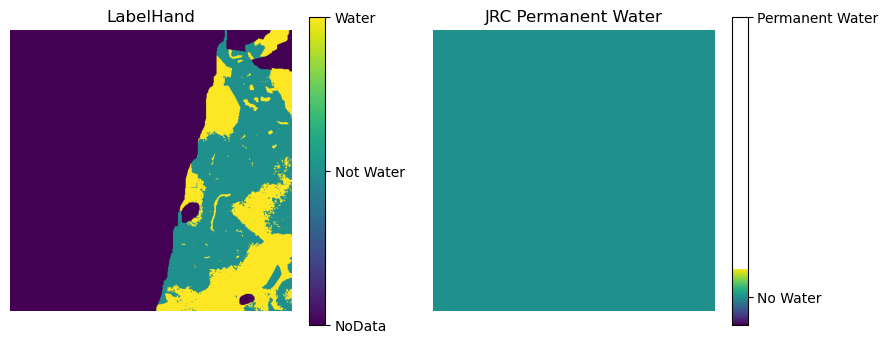

In [43]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(label)
plt.title("LabelHand")
plt.axis("off")
c = plt.colorbar()
c.set_ticks([-1, 0, 1])
c.set_ticklabels(["NoData", "Not Water", "Water"])

plt.subplot(1, 2, 2)
plt.imshow(jrc)
plt.title("JRC Permanent Water")
plt.axis("off")
c = plt.colorbar()
c.set_ticks([0, 1])
c.set_ticklabels(["No Water", "Permanent Water"])

plt.show()

### 3-class label (Land / Permanent water / Flood water)

In [44]:
three_class = np.zeros_like(label, dtype=np.uint8)

# 0 = Land / Not Water
# 1 = Permanent Water
# 2 = Event / Non-permanent Water
# 255 = NoData

three_class[label == 1] = 2
three_class[(label == 1) & (jrc == 1)] = 1
three_class[label == -1] = 255

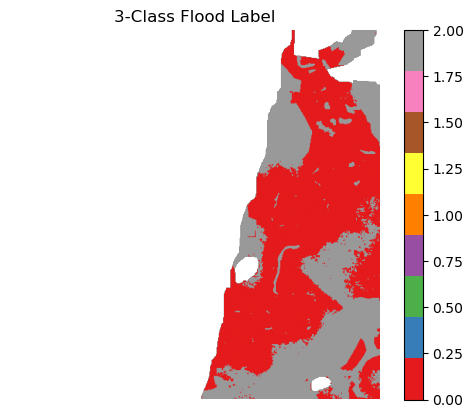

In [45]:
plt.imshow(np.ma.masked_equal(three_class, 255), cmap="Set1", vmin=0, vmax=2)
plt.title("3-Class Flood Label")
plt.colorbar()
plt.axis("off")
plt.show()

In [46]:
# for 1 img
for value in [0, 1, 2, 255]:
    print(value, ":", np.sum(three_class == value))

0 : 52715
1 : 0
2 : 35362
255 : 174067


In [47]:
total = np.sum(three_class != 255)

for value, name in [(0, "Land"), (1, "Permanent Water"), (2, "Flooded Land")]:
    count = np.sum(three_class == value)
    print(name, ":", count, "pixels,", round(count / total * 100, 2), "%")

Land : 52715 pixels, 59.85 %
Permanent Water : 0 pixels, 0.0 %
Flooded Land : 35362 pixels, 40.15 %


In [48]:
def make_three_class_label(label_path, jrc_path):

    with rasterio.open(label_path) as src:
        label = src.read(1)

    with rasterio.open(jrc_path) as src:
        jrc = src.read(1)

    three_class = np.zeros_like(label, dtype=np.uint8)

    # 0 = Land / Not Water
    # 1 = Permanent Water
    # 2 = Event / Non-permanent Water
    # 255 = NoData

    three_class[label == 1] = 2
    three_class[(label == 1) & (jrc == 1)] = 1
    three_class[label == -1] = 255

    return three_class

In [49]:
def make_three_class_label(label_path, jrc_path):
    with rasterio.open(label_path) as src:
        label = src.read(1)

    with rasterio.open(jrc_path) as src:
        jrc = src.read(1)

    three_class = np.zeros_like(label, dtype=np.uint8)

    # Water → initially Flooded Land
    three_class[label == 1] = 2

    # Water + JRC permanent water → Permanent Water
    three_class[(label == 1) & (jrc == 1)] = 1

    # Label NoData
    three_class[label == -1] = 255

    return three_class

In [50]:
jrc_folder = "/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/JRCWaterHand/JRCWaterHand"
jrc_folder_p = jrc_folder

import os
print("Folder exists:", os.path.isdir(jrc_folder))
print("Number of files:", len(os.listdir(jrc_folder)))
print(os.listdir(jrc_folder)[:5])

Folder exists: True
Number of files: 446
['Spain_4282030_JRCWaterHand.tif', 'Mekong_846007_JRCWaterHand.tif', 'India_570384_JRCWaterHand.tif', 'India_164336_JRCWaterHand.tif', 'India_135434_JRCWaterHand.tif']


In [51]:
class_counts = {
    0: 0,
    1: 0,
    2: 0,
    255: 0
}

processed = 0

for file in os.listdir(label_folder):

    if not file.endswith("_LabelHand.tif"):
        continue

    label_path = os.path.join(label_folder, file)

    # Find the matching JRC file
    jrc_filename = file.replace(
        "_LabelHand.tif",
        "_JRCWaterHand.tif"
    )

    jrc_path = os.path.join(jrc_folder, jrc_filename)

    if not os.path.exists(jrc_path):
        continue

    three_class = make_three_class_label(
        label_path,
        jrc_path
    )

    for value in class_counts:
        class_counts[value] += np.sum(three_class == value)

    processed += 1

print("Images processed:", processed)

total_pixels = sum(class_counts.values())
valid_pixels = total_pixels - class_counts[255]

print("Total pixels:", total_pixels)
print("Valid pixels:", valid_pixels)
print("NoData pixels:", class_counts[255])

for value, name in [
    (0, "No Water"),
    (1, "Permanent Water"),
    (2, "Flooded Water")
]:
    count = class_counts[value]
    percentage = count / valid_pixels * 100

    print(
        f"Class {value} - {name}: "
        f"{count:,} pixels ({percentage:.2f}%)"
    )

Images processed: 446
Total pixels: 116916224
Valid pixels: 100983314
NoData pixels: 15932910
Class 0 - No Water: 90,277,709 pixels (89.40%)
Class 1 - Permanent Water: 3,062,228 pixels (3.03%)
Class 2 - Flooded Water: 7,643,377 pixels (7.57%)


In [52]:
import os

print("Label folder:", label_folder)
print("Folder exists:", os.path.isdir(label_folder))

if os.path.isdir(label_folder):
    print("Files found:", len(os.listdir(label_folder)))
    print(os.listdir(label_folder)[:10])

print("JRC folder:", jrc_folder)
print("JRC folder exists:", os.path.isdir(jrc_folder))

Label folder: /Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/LabelHand/LabelHand
Folder exists: True
Files found: 446
['Mekong_382276_LabelHand.tif', 'Paraguay_7894_LabelHand.tif', 'USA_19225_LabelHand.tif', 'Sri-Lanka_92824_LabelHand.tif', 'USA_366607_LabelHand.tif', 'Somalia_7931_LabelHand.tif', 'India_842775_LabelHand.tif', 'Paraguay_581976_LabelHand.tif', 'Pakistan_1036366_LabelHand.tif', 'Spain_8154154_LabelHand.tif']
JRC folder: /Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/JRCWaterHand/JRCWaterHand
JRC folder exists: True


## 3. Train / validation / test splits

In [53]:
from pathlib import Path

DATA_ROOT = Path("/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1")
split_folder = DATA_ROOT / "splits"
print("Split folder exists:", split_folder.exists())
print(list(split_folder.rglob("flood_train_data.csv")))

Split folder exists: True
[PosixPath('/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/splits/flood_train_data.csv'), PosixPath('/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/splits/splits/flood_handlabeled/flood_train_data.csv')]


In [54]:
split_folder = DATA_ROOT / "splits" / "splits" / "flood_handlabeled"

In [55]:
train_df = pd.read_csv(
    os.path.join(split_folder, "flood_train_data.csv"),
    header=None,
    names=["s1", "label"]
)

valid_df = pd.read_csv(
    os.path.join(split_folder, "flood_valid_data.csv"),
    header=None,
    names=["s1", "label"]
)

test_df = pd.read_csv(
    os.path.join(split_folder, "flood_test_data.csv"),
    header=None,
    names=["s1", "label"]
)

In [56]:
print("Train:", len(train_df))
print("Validation:", len(valid_df))
print("Test:", len(test_df))

print(train_df.head())

Train: 252
Validation: 89
Test: 90
                        s1                       label
0  Ghana_103272_S1Hand.tif  Ghana_103272_LabelHand.tif
1   Ghana_24858_S1Hand.tif   Ghana_24858_LabelHand.tif
2  Ghana_147015_S1Hand.tif  Ghana_147015_LabelHand.tif
3  Ghana_953791_S1Hand.tif  Ghana_953791_LabelHand.tif
4  Ghana_154838_S1Hand.tif  Ghana_154838_LabelHand.tif


In [57]:
print("\nColumns:")
print(train_df.columns.tolist())


Columns:
['s1', 'label']


In [58]:
print("Train:", len(train_df))
print("Validation:", len(valid_df))
print("Test:", len(test_df))


Train: 252
Validation: 89
Test: 90


## 4. Normalisation & preprocessing

In [59]:
vv_min = np.inf
vv_max = -np.inf
vh_min = np.inf
vh_max = -np.inf

for filename in train_df.iloc[:, 0]:
    if filename.endswith("_S1Hand.tif"):
        path = os.path.join(s1_folder, filename)

        with rasterio.open(path) as src:
            vv = src.read(1)
            vh = src.read(2)

        vv_valid = vv[np.isfinite(vv)]
        vh_valid = vh[np.isfinite(vh)]

        if len(vv_valid) > 0:
            vv_min = min(vv_min, vv_valid.min())
            vv_max = max(vv_max, vv_valid.max())

        if len(vh_valid) > 0:
            vh_min = min(vh_min, vh_valid.min())
            vh_max = max(vh_max, vh_valid.max())

print("Global VV range:", vv_min, "to", vv_max)
print("Global VH range:", vh_min, "to", vh_max)


Global VV range: -65.45004 to 29.926394
Global VH range: -79.161446 to 17.376385


In [60]:
vv_min, vv_max = np.inf, -np.inf
vh_min, vh_max = np.inf, -np.inf

for filename in train_df["s1"]:
    path = os.path.join(s1_folder, filename)

    with rasterio.open(path) as src:
        vv = src.read(1)
        vh = src.read(2)

    vv_valid = vv[~np.isnan(vv)]
    vh_valid = vh[~np.isnan(vh)]

    vv_min = min(vv_min, vv_valid.min())
    vv_max = max(vv_max, vv_valid.max())

    vh_min = min(vh_min, vh_valid.min())
    vh_max = max(vh_max, vh_valid.max())

print("VV:", vv_min, "to", vv_max)
print("VH:", vh_min, "to", vh_max)

VV: -65.45004 to 29.926394
VH: -79.161446 to 17.376385


In [61]:
# ============================================
# TRAINING SET VV/VH PERCENTILES
# ============================================

vv_values = []
vh_values = []

for filename in train_df["s1"]:

    path = os.path.join(s1_folder, filename)

    with rasterio.open(path) as src:
        vv = src.read(1)
        vh = src.read(2)

    vv_values.extend(vv[np.isfinite(vv)])
    vh_values.extend(vh[np.isfinite(vh)])

vv_values = np.array(vv_values)
vh_values = np.array(vh_values)

print("VV 2nd percentile :", np.percentile(vv_values, 2))
print("VV 98th percentile:", np.percentile(vv_values, 98))

print("VH 2nd percentile :", np.percentile(vh_values, 2))
print("VH 98th percentile:", np.percentile(vh_values, 98))

VV 2nd percentile : -21.938955
VV 98th percentile: -3.7259939
VH 2nd percentile : -30.85579
VH 98th percentile: -10.476822


In [65]:
from scipy.ndimage import median_filter

def preprocess_s1(path):

    with rasterio.open(path) as src:
        vv = src.read(1).astype(np.float32)
        vh = src.read(2).astype(np.float32)

    nodata_mask = np.isnan(vv) | np.isnan(vh)

    # Original normalization
    vv_norm = (vv - vv_min) / (vv_max - vv_min)
    vh_norm = (vh - vh_min) / (vh_max - vh_min)

    vv_temp = np.nan_to_num(vv_norm, nan=0.0)
    vh_temp = np.nan_to_num(vh_norm, nan=0.0)

    vv_filtered = median_filter(vv_temp, size=3)
    vh_filtered = median_filter(vh_temp, size=3)

    vv_filtered[nodata_mask] = 0.0
    vh_filtered[nodata_mask] = 0.0

    return np.stack([vv_filtered, vh_filtered], axis=0)

In [66]:
sample_filename = train_df.iloc[0]["s1"]
sample_path = os.path.join(s1_folder, sample_filename)

sample_input = preprocess_s1(sample_path)

print("Shape:", sample_input.shape)
print("VV range:", sample_input[0].min(), "to", sample_input[0].max())
print("VH range:", sample_input[1].min(), "to", sample_input[1].max())
print("Finite:", np.isfinite(sample_input).all())

Shape: (2, 512, 512)
VV range: 0.3978222 to 0.7441679
VH range: 0.32924446 to 0.7858727
Finite: True


In [64]:
sample_filename = train_df.iloc[0, 0]
sample_path = os.path.join(s1_folder, sample_filename)

sample_input = preprocess_s1(sample_path)

print("File:", sample_filename)
print("Shape:", sample_input.shape)
print("VV range:", np.nanmin(sample_input[0]), "to", np.nanmax(sample_input[0]))
print("VH range:", np.nanmin(sample_input[1]), "to", np.nanmax(sample_input[1]))

File: Ghana_103272_S1Hand.tif
Shape: (2, 512, 512)
VV range: 0.3978222 to 0.7441679
VH range: 0.32924446 to 0.7858727


## 5. Class distribution

In [67]:
def class_distribution(df):

    counts = {
        0: 0,
        1: 0,
        2: 0,
        255: 0
    }

    for label_filename in df.iloc[:, 1]:

        if not label_filename.endswith("_LabelHand.tif"):
            continue

        label_path = os.path.join(
            label_folder,
            label_filename
        )

        jrc_filename = label_filename.replace(
            "_LabelHand.tif",
            "_JRCWaterHand.tif"
        )

        jrc_path = os.path.join(
            jrc_folder,
            jrc_filename
        )

        if not os.path.exists(jrc_path):
            continue

        three_class = make_three_class_label(
            label_path,
            jrc_path
        )

        for value in counts:
            counts[value] += np.sum(
                three_class == value
            )

    return counts

In [68]:
def class_distribution(df):
    counts = {0: 0, 1: 0, 2: 0, 255: 0}

    for label_filename in df["label"]:
        label_path = os.path.join(label_folder, label_filename)

        # Corresponding JRC filename
        jrc_filename = label_filename.replace(
            "_LabelHand.tif",
            "_JRCWaterHand.tif"
        )
        jrc_path = os.path.join(jrc_folder, jrc_filename)

        with rasterio.open(label_path) as src:
            label = src.read(1)

        with rasterio.open(jrc_path) as src:
            jrc = src.read(1)

        three_class = np.zeros_like(label, dtype=np.uint8)

        # Flooded land
        three_class[label == 1] = 2

        # Permanent water
        three_class[(label == 1) & (jrc == 1)] = 1

        # NoData
        three_class[label == -1] = 255

        for cls in counts:
            counts[cls] += np.sum(three_class == cls)

    return counts

In [69]:
train_counts = class_distribution(train_df)
valid_counts = class_distribution(valid_df)
test_counts = class_distribution(test_df)

print("Train:", train_counts)
print("Validation:", valid_counts)
print("Test:", test_counts)

Train: {0: np.int64(51856372), 1: np.int64(1521824), 2: np.int64(3925211), 255: np.int64(8756881)}
Validation: {0: np.int64(18057120), 1: np.int64(611055), 2: np.int64(1626550), 255: np.int64(3036091)}
Test: {0: np.int64(17951266), 1: np.int64(899398), 2: np.int64(1666703), 255: np.int64(3075593)}


In [70]:
train_counts = class_distribution(train_df)
valid_counts = class_distribution(valid_df)
test_counts = class_distribution(test_df)

print("Train:", train_counts)
print("Validation:", valid_counts)
print("Test:", test_counts)

Train: {0: np.int64(51856372), 1: np.int64(1521824), 2: np.int64(3925211), 255: np.int64(8756881)}
Validation: {0: np.int64(18057120), 1: np.int64(611055), 2: np.int64(1626550), 255: np.int64(3036091)}
Test: {0: np.int64(17951266), 1: np.int64(899398), 2: np.int64(1666703), 255: np.int64(3075593)}


In [71]:
def class_percentages(counts):

    valid_total = counts[0] + counts[1] + counts[2]

    return {
        "Land": counts[0] / valid_total * 100,
        "Permanent Water": counts[1] / valid_total * 100,
        "Flooded Land": counts[2] / valid_total * 100
    }

print("Train:", class_percentages(train_counts))
print("Validation:", class_percentages(valid_counts))
print("Test:", class_percentages(test_counts))

Train: {'Land': np.float64(90.49439590912979), 'Permanent Water': np.float64(2.655730400113906), 'Flooded Land': np.float64(6.849873690756294)}
Validation: {'Land': np.float64(88.97445025739447), 'Permanent Water': np.float64(3.0109055431891787), 'Flooded Land': np.float64(8.01464419941635)}
Test: {'Land': np.float64(87.49302968553421), 'Permanent Water': np.float64(4.383593664820637), 'Flooded Land': np.float64(8.123376649645152)}


In [72]:
import numpy as np
import os

tile_stats = []

for idx, row in train_df.iterrows():

    label_filename = row["label"]

    label_path = os.path.join(
        label_folder,
        label_filename
    )

    jrc_filename = label_filename.replace(
        "_LabelHand.tif",
        "_JRCWaterHand.tif"
    )

    jrc_path = os.path.join(
        jrc_folder,
        jrc_filename
    )

    # Create 3-class label
    three_class = make_three_class_label(
        label_path,
        jrc_path
    )

    # Ignore NoData
    valid_pixels = three_class != 255

    total = np.sum(valid_pixels)

    land = np.sum(three_class == 0)
    permanent_water = np.sum(three_class == 1)
    flooded_land = np.sum(three_class == 2)

    tile_stats.append({
        "filename": label_filename,
        "land_pct": land / total * 100,
        "permanent_water_pct": permanent_water / total * 100,
        "non_permanent_water_pct": flooded_land / total * 100
    })

print("Number of training tiles:", len(tile_stats))

print("\nFirst 10 tiles:")
for item in tile_stats[:10]:
    print(item)

/var/folders/n2/zsmb8b6x5l99f4xjqnvgzc6w0000gn/T/ipykernel_62791/2160992302.py:42: RuntimeWarning: invalid value encountered in scalar divide
  "land_pct": land / total * 100,
/var/folders/n2/zsmb8b6x5l99f4xjqnvgzc6w0000gn/T/ipykernel_62791/2160992302.py:43: RuntimeWarning: invalid value encountered in scalar divide
  "permanent_water_pct": permanent_water / total * 100,
/var/folders/n2/zsmb8b6x5l99f4xjqnvgzc6w0000gn/T/ipykernel_62791/2160992302.py:44: RuntimeWarning: invalid value encountered in scalar divide
  "non_permanent_water_pct": flooded_land / total * 100


Number of training tiles: 252

First 10 tiles:
{'filename': 'Ghana_103272_LabelHand.tif', 'land_pct': np.float64(99.3990797202905), 'permanent_water_pct': np.float64(0.1446374229082536), 'non_permanent_water_pct': np.float64(0.4562828568012373)}
{'filename': 'Ghana_24858_LabelHand.tif', 'land_pct': np.float64(99.81536865234375), 'permanent_water_pct': np.float64(0.0), 'non_permanent_water_pct': np.float64(0.18463134765625)}
{'filename': 'Ghana_147015_LabelHand.tif', 'land_pct': np.float64(98.65341186523438), 'permanent_water_pct': np.float64(0.0), 'non_permanent_water_pct': np.float64(1.346588134765625)}
{'filename': 'Ghana_953791_LabelHand.tif', 'land_pct': np.float64(98.94256591796875), 'permanent_water_pct': np.float64(0.0), 'non_permanent_water_pct': np.float64(1.05743408203125)}
{'filename': 'Ghana_154838_LabelHand.tif', 'land_pct': np.float64(100.0), 'permanent_water_pct': np.float64(0.0), 'non_permanent_water_pct': np.float64(0.0)}
{'filename': 'Ghana_134751_LabelHand.tif', 'lan

In [73]:
# ============================================
# STEP 2: SUMMARIZE TRAINING TILE TYPES
# ============================================

land_only = 0
non_permanent_water_tiles = 0
water_tiles = 0
both_minority = 0
empty_tiles = 0

for item in tile_stats:

    water = item["permanent_water_pct"]
    flood = item["non_permanent_water_pct"]

    # Completely invalid / empty tile
    if np.isnan(water) or np.isnan(flood):
        empty_tiles += 1

    # Contains both minority classes
    elif water > 0 and flood > 0:
        both_minority += 1

    # Contains permanent water
    elif water > 0:
        water_tiles += 1

    # Contains flooded land
    elif flood > 0:
        non_permanent_water_tiles += 1

    # Only land
    else:
        land_only += 1


print("================================")
print("TRAINING TILE SUMMARY")
print("================================")

print("Total tiles:", len(tile_stats))
print("Land-only tiles:", land_only)
print("Flood-containing tiles:", non_permanent_water_tiles)
print("Permanent-water tiles:", water_tiles)
print("Both minority classes:", both_minority)
print("Empty/invalid tiles:", empty_tiles)

TRAINING TILE SUMMARY
Total tiles: 252
Land-only tiles: 32
Flood-containing tiles: 98
Permanent-water tiles: 0
Both minority classes: 121
Empty/invalid tiles: 1


In [74]:
# ============================================
# STEP 3: MINORITY CLASS DISTRIBUTION
# ============================================

water_percentages = []
flood_percentages = []

for item in tile_stats:

    water = item["permanent_water_pct"]
    flood = item["non_permanent_water_pct"]

    if not np.isnan(water):
        water_percentages.append(water)

    if not np.isnan(flood):
        flood_percentages.append(flood)


print("================================")
print("MINORITY CLASS DISTRIBUTION")
print("================================")

print("\nPermanent Water:")
print("Average :", np.mean(water_percentages), "%")
print("Median  :", np.median(water_percentages), "%")
print("Maximum :", np.max(water_percentages), "%")

print("\nFlooded Land:")
print("Average :", np.mean(flood_percentages), "%")
print("Median  :", np.median(flood_percentages), "%")
print("Maximum :", np.max(flood_percentages), "%")

MINORITY CLASS DISTRIBUTION

Permanent Water:
Average : 2.631178206448873 %
Median  : 0.0 %
Maximum : 97.09002400750961 %

Flooded Land:
Average : 6.747253376489373 %
Median  : 1.848602294921875 %
Maximum : 84.20372009277344 %


In [75]:
# ============================================
# STEP 4: COUNT MINORITY-RICH TILES
# ============================================

water_1 = 0
water_5 = 0
flood_1 = 0
flood_5 = 0
both_5 = 0

for item in tile_stats:

    water = item["permanent_water_pct"]
    flood = item["non_permanent_water_pct"]

    if water >= 1:
        water_1 += 1

    if water >= 5:
        water_5 += 1

    if flood >= 1:
        flood_1 += 1

    if flood >= 5:
        flood_5 += 1

    if water >= 5 and flood >= 5:
        both_5 += 1


print("================================")
print("MINORITY-RICH TILE COUNTS")
print("================================")

print("Permanent Water >= 1% :", water_1)
print("Permanent Water >= 5% :", water_5)

print("Flooded Land >= 1%    :", flood_1)
print("Flooded Land >= 5%    :", flood_5)

print("Both >= 5%            :", both_5)

MINORITY-RICH TILE COUNTS
Permanent Water >= 1% : 45
Permanent Water >= 5% : 26
Flooded Land >= 1%    : 155
Flooded Land >= 5%    : 80
Both >= 5%            : 15


In [76]:
# ============================================
# STEP 5: ESTIMATE AUGMENTED DATASET SIZE
# ============================================

total_samples = 0

for item in tile_stats:

    water = item["permanent_water_pct"]
    flood = item["non_permanent_water_pct"]

    if water >= 5:
        multiplier = 5       # original + 4 augmentations

    elif flood >= 5:
        multiplier = 3       # original + 2 augmentations

    else:
        multiplier = 1       # original only

    total_samples += multiplier

print("================================")
print("AUGMENTATION SIZE ESTIMATE")
print("================================")
print("Original training tiles :", len(tile_stats))
print("Estimated final samples :", total_samples)
print("Additional samples      :", total_samples - len(tile_stats))

AUGMENTATION SIZE ESTIMATE
Original training tiles : 252
Estimated final samples : 486
Additional samples      : 234


## 6. Class-aware augmentation

In [77]:
from pathlib import Path
import os
import numpy as np


PROJECT_ROOT = Path.cwd()
BASE_DIR = PROJECT_ROOT / "Sen1Floods11" / "v1.1"

aug_image_dir = os.path.join(BASE_DIR, "Augmented_S1")
aug_label_folder = os.path.join(BASE_DIR, "Augmented_Labels")

os.makedirs(aug_image_dir, exist_ok=True)
os.makedirs(aug_label_folder, exist_ok=True)

print("Augmented image folder:", aug_image_dir)
print("Augmented label folder:", aug_label_folder)

Augmented image folder: /Users/pramodithakathari/GeoMind-AI-v7/Sen1Floods11/v1.1/Augmented_S1
Augmented label folder: /Users/pramodithakathari/GeoMind-AI-v7/Sen1Floods11/v1.1/Augmented_Labels


In [78]:
# ============================================
# STEP 6: ACTUAL CLASS-AWARE AUGMENTATION
# ============================================

def apply_augmentation(image, label, aug_name):

    if aug_name == "horizontal_flip":
        image_aug = np.flip(image, axis=2)
        label_aug = np.flip(label, axis=1)

    elif aug_name == "vertical_flip":
        image_aug = np.flip(image, axis=1)
        label_aug = np.flip(label, axis=0)

    elif aug_name == "rotate_90":
        image_aug = np.rot90(image, k=1, axes=(1, 2))
        label_aug = np.rot90(label, k=1)

    elif aug_name == "rotate_180":
        image_aug = np.rot90(image, k=2, axes=(1, 2))
        label_aug = np.rot90(label, k=2)

    else:
        raise ValueError("Unknown augmentation")

    return image_aug.copy(), label_aug.copy()


created = 0

for item in tile_stats:

    label_filename = item["filename"]

    image_filename = label_filename.replace(
        "_LabelHand.tif",
        "_S1Hand.tif"
    )

    image_path = os.path.join(
        s1_folder,
        image_filename
    )

    label_path = os.path.join(
        label_folder,
        label_filename
    )

    # JRC water file
    jrc_filename = label_filename.replace(
        "_LabelHand.tif",
        "_JRCWaterHand.tif"
    )

    jrc_path = os.path.join(
        jrc_folder,
        jrc_filename
    )

    # Preprocess image
    image = preprocess_s1(image_path)

    # Create 3-class label
    label = make_three_class_label(
        label_path,
        jrc_path
    )

    water = item["permanent_water_pct"]
    flood = item["non_permanent_water_pct"]

    # Class-aware augmentation
    if water >= 5:
        selected_augs = [
            "horizontal_flip",
            "vertical_flip",
            "rotate_90",
            "rotate_180"
        ]

    elif flood >= 5:
        selected_augs = [
            "horizontal_flip",
            "vertical_flip"
        ]

    else:
        selected_augs = []

    base_name = label_filename.replace(
        "_LabelHand.tif",
        ""
    )

    for aug_name in selected_augs:

        aug_image, aug_label = apply_augmentation(
            image,
            label,
            aug_name
        )

        image_out = os.path.join(
            aug_image_dir,
            f"{base_name}_{aug_name}.npy"
        )

        label_out = os.path.join(
            aug_label_folder,
            f"{base_name}_{aug_name}.npy"
        )

        np.save(image_out, aug_image)
        np.save(label_out, aug_label)

        created += 1


print("================================")
print("DATA AUGMENTATION COMPLETED")
print("================================")
print("Original training tiles :", len(tile_stats))
print("New augmented samples   :", created)
print("Final training samples  :", len(tile_stats) + created)

DATA AUGMENTATION COMPLETED
Original training tiles : 252
New augmented samples   : 234
Final training samples  : 486


In [79]:
aug_files = [
    f for f in os.listdir(aug_image_dir)
    if f.endswith(".npy")
]

test_aug = np.load(
    os.path.join(aug_image_dir, aug_files[0])
)

print("Shape:", test_aug.shape)
print("VV range:", test_aug[0].min(), "to", test_aug[0].max())
print("VH range:", test_aug[1].min(), "to", test_aug[1].max())
print("Finite:", np.isfinite(test_aug).all())

Shape: (2, 512, 512)
VV range: 0.43924388 to 0.88248557
VH range: 0.4641113 to 0.85594904
Finite: True


In [80]:
# ============================================
# CLASS DISTRIBUTION AFTER AUGMENTATION
# ============================================

after_counts = {
    0: 0,
    1: 0,
    2: 0
}

# 1. Count original training labels
for label_filename in train_df["label"]:

    label_path = os.path.join(
        label_folder,
        label_filename
    )

    jrc_filename = label_filename.replace(
        "_LabelHand.tif",
        "_JRCWaterHand.tif"
    )

    jrc_path = os.path.join(
        jrc_folder,
        jrc_filename
    )

    label = make_three_class_label(
        label_path,
        jrc_path
    )

    for cls in range(3):
        after_counts[cls] += np.sum(label == cls)


# 2. Count augmented labels
for filename in os.listdir(aug_label_folder):

    if filename.endswith(".npy"):

        label = np.load(
            os.path.join(aug_label_folder, filename)
        )

        for cls in range(3):
            after_counts[cls] += np.sum(label == cls)


# Calculate percentages
total_valid = sum(after_counts.values())

print("================================")
print("CLASS DISTRIBUTION AFTER AUGMENTATION")
print("================================")

for cls, name in [
    (0, "No Water"),
    (1, "Permanent Water"),
    (2, "Non-permanent Water")
]:

    percentage = after_counts[cls] / total_valid * 100

    print(
        f"Class {cls} - {name}: "
        f"{after_counts[cls]:,} pixels "
        f"({percentage:.2f}%)"
    )

CLASS DISTRIBUTION AFTER AUGMENTATION
Class 0 - No Water: 91,713,110 pixels (82.38%)
Class 1 - Permanent Water: 7,219,772 pixels (6.49%)
Class 2 - Non-permanent Water: 12,392,993 pixels (11.13%)


In [81]:
import os

print("Augmented images:", len(os.listdir(aug_image_dir)))
print("Augmented labels:", len(os.listdir(aug_label_folder)))

print("\nSample augmented images:")
print(os.listdir(aug_image_dir)[:5])

print("\nSample augmented labels:")
print(os.listdir(aug_label_folder)[:5])

Augmented images: 234
Augmented labels: 234

Sample augmented images:
['India_566697_horizontal_flip.npy', 'Mekong_774566_rotate_90.npy', 'Sri-Lanka_1038087_vertical_flip.npy', 'Mekong_1395593_vertical_flip.npy', 'Sri-Lanka_14484_vertical_flip.npy']

Sample augmented labels:
['India_566697_horizontal_flip.npy', 'Mekong_774566_rotate_90.npy', 'Sri-Lanka_1038087_vertical_flip.npy', 'Mekong_1395593_vertical_flip.npy', 'Sri-Lanka_14484_vertical_flip.npy']


In [82]:
print("Original S1 folder:", s1_folder)
print("Original label folder:", label_folder)
print("Augmented S1 folder:", aug_image_dir)
print("Augmented label folder:", aug_label_folder)

Original S1 folder: /Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/S1Hand/S1Hand
Original label folder: /Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/LabelHand/LabelHand
Augmented S1 folder: /Users/pramodithakathari/GeoMind-AI-v7/Sen1Floods11/v1.1/Augmented_S1
Augmented label folder: /Users/pramodithakathari/GeoMind-AI-v7/Sen1Floods11/v1.1/Augmented_Labels


## 7. Dataset & DataLoader

In [83]:
import torch
from torch.utils.data import Dataset
import numpy as np
import os

class AugmentedFloodDataset(Dataset):

    def __init__(
        self,
        train_df,
        s1_folder,
        label_folder,
        jrc_folder,
        augmented_image_dir=None,
        augmented_label_folder=None,
        include_augmented=True
    ):

        self.samples = []

        # ==========================================
        # 1. ORIGINAL TRAINING SAMPLES
        # ==========================================

        for i in range(len(train_df)):

            s1_filename = train_df.iloc[i]["s1"]
            label_filename = train_df.iloc[i]["label"]

            s1_path = os.path.join(
                s1_folder,
                s1_filename
            )

            label_path = os.path.join(
                label_folder,
                label_filename
            )

            jrc_filename = label_filename.replace(
                "_LabelHand.tif",
                "_JRCWaterHand.tif"
            )

            jrc_path = os.path.join(
                jrc_folder,
                jrc_filename
            )

            self.samples.append(
                (
                    "original",
                    s1_path,
                    label_path,
                    jrc_path
                )
            )

        # ==========================================
        # 2. AUGMENTED TRAINING SAMPLES
        # ==========================================

        if include_augmented and augmented_image_dir and augmented_label_folder:
            for filename in os.listdir(augmented_image_dir):
                if filename.endswith(".npy"):
                    image_path = os.path.join(augmented_image_dir, filename)
                    label_path = os.path.join(augmented_label_folder, filename)
        
                    if os.path.exists(label_path):
                        self.samples.append(
                            ("augmented", image_path, label_path, None)
                        )

    # ==========================================
    # NUMBER OF SAMPLES
    # ==========================================

    def __len__(self):

        return len(self.samples)

    # ==========================================
    # LOAD ONE SAMPLE
    # ==========================================

    def __getitem__(self, idx):

        sample_type, image_path, label_path, jrc_path = self.samples[idx]

        # ------------------------------------------
        # ORIGINAL TIFF
        # ------------------------------------------

        if sample_type == "original":

            image = preprocess_s1(image_path)

            label = make_three_class_label(
                label_path,
                jrc_path
            )

        # ------------------------------------------
        # AUGMENTED NPY
        # ------------------------------------------

        else:

            image = np.load(image_path)
            label = np.load(label_path)

        # Convert to PyTorch tensors

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        label = torch.tensor(
            label,
            dtype=torch.long
        )

        return image, label


# ==============================================
# CREATE DATASET
# ==============================================

def is_valid_label(label):
    return np.any(label != 255)

valid_indices = []

for i in range(len(train_df)):

    label_filename = train_df.iloc[i]["label"]

    label_path = os.path.join(
        label_folder,
        label_filename
    )

    with rasterio.open(label_path) as src:
        label = src.read(1)

    if np.any(label != 255):
        valid_indices.append(i)

valid_train_df = train_df.iloc[valid_indices].reset_index(drop=True)

print("Original training samples:", len(train_df))
print("Valid training samples:", len(valid_train_df))
print("Removed invalid samples:", len(train_df) - len(valid_train_df))

train_dataset = AugmentedFloodDataset(
    valid_train_df,
    s1_folder,
    label_folder,
    jrc_folder,
    aug_image_dir,
    aug_label_folder
)

print("Original training samples:", len(train_df))
print("Augmented training samples:", len(os.listdir(aug_image_dir)))
print("Total training samples:", len(train_dataset))

Original training samples: 252
Valid training samples: 252
Removed invalid samples: 0
Original training samples: 252
Augmented training samples: 234
Total training samples: 486


In [84]:
# Test original sample
image1, label1 = train_dataset[0]

print("ORIGINAL SAMPLE")
print("Image shape:", image1.shape)
print("Label shape:", label1.shape)
print("Image dtype:", image1.dtype)
print("Label dtype:", label1.dtype)
print("Image finite:", torch.isfinite(image1).all().item())
print("Label min:", label1.min().item())
print("Label max:", label1.max().item())

ORIGINAL SAMPLE
Image shape: torch.Size([2, 512, 512])
Label shape: torch.Size([512, 512])
Image dtype: torch.float32
Label dtype: torch.int64
Image finite: True
Label min: 0
Label max: 255


In [85]:
print("Number of samples:", len(train_dataset.samples))

print("\nFirst sample:")
print(train_dataset.samples[0])

print("\nFirst augmented sample:")
print(train_dataset.samples[-1])

Number of samples: 486

First sample:
('original', '/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/S1Hand/S1Hand/Ghana_103272_S1Hand.tif', '/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/LabelHand/LabelHand/Ghana_103272_LabelHand.tif', '/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/JRCWaterHand/JRCWaterHand/Ghana_103272_JRCWaterHand.tif')

First augmented sample:
('augmented', '/Users/pramodithakathari/GeoMind-AI-v7/Sen1Floods11/v1.1/Augmented_S1/India_1017769_vertical_flip.npy', '/Users/pramodithakathari/GeoMind-AI-v7/Sen1Floods11/v1.1/Augmented_Labels/India_1017769_vertical_flip.npy', None)


In [86]:
# Find an augmented sample

aug_indices = [
    i for i, sample in enumerate(train_dataset.samples)
    if sample[0] == "augmented"
]

print("Number of augmented samples:", len(aug_indices))

# Load the first augmented sample
idx = aug_indices[0]

image2, label2 = train_dataset[idx]

print("\nAUGMENTED SAMPLE")
print("Image shape:", image2.shape)
print("Label shape:", label2.shape)
print("Image dtype:", image2.dtype)
print("Label dtype:", label2.dtype)
print("Image finite:", torch.isfinite(image2).all().item())
print("Label min:", label2.min().item())
print("Label max:", label2.max().item())

Number of augmented samples: 234

AUGMENTED SAMPLE
Image shape: torch.Size([2, 512, 512])
Label shape: torch.Size([512, 512])
Image dtype: torch.float32
Label dtype: torch.int64
Image finite: True
Label min: 0
Label max: 255


In [87]:
import torch
from torch.utils.data import DataLoader, WeightedRandomSampler
import numpy as np

# ============================================
# CREATE SAMPLE WEIGHTS FOR CLASS IMBALANCE
# ============================================

sample_weights = []

for i in range(len(train_dataset)):

    # Load image and label through our dataset
    _, label = train_dataset[i]

    # Ignore NoData (255)
    valid = label != 255

    # Count minority-class pixels
    minority_pixels = ((label == 1) | (label == 2)) & valid

    if valid.sum() == 0:
        weight = 1.0
    else:
        minority_ratio = minority_pixels.sum().item() / valid.sum().item()

        # Higher weight for tiles containing more minority pixels
        weight = 1.0 + 4.0 * minority_ratio

    sample_weights.append(weight)

sample_weights = torch.tensor(sample_weights, dtype=torch.double)

# ============================================
# WEIGHTED SAMPLER
# ============================================

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

# ============================================
# DATALOADER
# ============================================

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    sampler=sampler,
    num_workers=0
)

print("================================")
print("TRAINING DATALOADER READY")
print("================================")
print("Total samples:", len(train_dataset))
print("Batch size:", 4)
print("Number of batches:", len(train_loader))
print("Minimum sample weight:", sample_weights.min().item())
print("Maximum sample weight:", sample_weights.max().item())

TRAINING DATALOADER READY
Total samples: 486
Batch size: 4
Number of batches: 122
Minimum sample weight: 1.0
Maximum sample weight: 4.896792629943761


In [88]:
# ============================================
# TEST ONE TRAINING BATCH
# ============================================

images, labels = next(iter(train_loader))

print("BATCH TEST")
print("====================")
print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Images dtype:", images.dtype)
print("Labels dtype:", labels.dtype)
print("Images finite:", torch.isfinite(images).all().item())
print("Labels min:", labels.min().item())
print("Labels max:", labels.max().item())

BATCH TEST
Images shape: torch.Size([4, 2, 512, 512])
Labels shape: torch.Size([4, 512, 512])
Images dtype: torch.float32
Labels dtype: torch.int64
Images finite: True
Labels min: 0
Labels max: 255


## 7.2: Minority-Focused Patch Cropping

In [89]:

from pathlib import Path
import numpy as np
import os

# Store new patches separately from existing augmented files
patch_root = Path.cwd() / "Minority_Patches"
patch_image_dir = patch_root / "images"
patch_label_dir = patch_root / "labels"

patch_image_dir.mkdir(parents=True, exist_ok=True)
patch_label_dir.mkdir(parents=True, exist_ok=True)

PATCH_SIZE = 128
MINORITY_THRESHOLD = 5.0

# Clear old generated patches so rerunning this cell
# does not count duplicate files.
for folder in [patch_image_dir, patch_label_dir]:
    for file in folder.glob("*.npy"):
        file.unlink()

created = 0
patch_counts = {0: 0, 1: 0, 2: 0}

for _, row in train_df.iterrows():
    label_filename = row["label"]
    image_filename = row["s1"]

    image_path = os.path.join(s1_folder, image_filename)
    label_path = os.path.join(label_folder, label_filename)

    jrc_filename = label_filename.replace(
        "_LabelHand.tif", "_JRCWaterHand.tif"
    )
    jrc_path = os.path.join(jrc_folder, jrc_filename)

    if not os.path.exists(jrc_path):
        continue

    image = preprocess_s1(image_path)
    label = make_three_class_label(label_path, jrc_path)

    height, width = label.shape

    for y in range(0, height - PATCH_SIZE + 1, PATCH_SIZE):
        for x in range(0, width - PATCH_SIZE + 1, PATCH_SIZE):
            image_patch = image[:, y:y+PATCH_SIZE, x:x+PATCH_SIZE]
            label_patch = label[y:y+PATCH_SIZE, x:x+PATCH_SIZE]

            valid = label_patch != 255
            valid_count = valid.sum()

            if valid_count == 0:
                continue

            permanent_pct = (
                np.sum(label_patch == 1) / valid_count * 100
            )
            flood_pct = (
                np.sum(label_patch == 2) / valid_count * 100
            )

            # Keep minority-rich patches only
            if max(permanent_pct, flood_pct) < MINORITY_THRESHOLD:
                continue

            patch_name = (
                f"{Path(label_filename).stem}_y{y}_x{x}.npy"
            )

            np.save(patch_image_dir / patch_name, image_patch)
            np.save(patch_label_dir / patch_name, label_patch)

            for cls in [0, 1, 2]:
                patch_counts[cls] += np.sum(label_patch == cls)

            created += 1

print("Minority-focused patches created:", created)
print("Patch image files:", len(list(patch_image_dir.glob("*.npy"))))
print("Patch label files:", len(list(patch_label_dir.glob("*.npy"))))
print("Patch-only pixel counts:", patch_counts)


Minority-focused patches created: 1055
Patch image files: 1055
Patch label files: 1055
Patch-only pixel counts: {0: np.int64(10745241), 1: np.int64(1500897), 2: np.int64(3668695)}


In [90]:

# Existing augmented-data pixel counts
existing_counts = {
    0: 91713110,
    1: 7219772,
    2: 12392993
}

# New patch pixel counts
new_patch_counts = {
    0: 10745241,
    1: 1500897,
    2: 3668695
}

combined_counts = {
    cls: existing_counts[cls] + new_patch_counts[cls]
    for cls in [0, 1, 2]
}

total = sum(combined_counts.values())

print("COMBINED DISTRIBUTION")
for cls, name in enumerate(["Land", "Permanent Water", "Flood Water"]):
    print(f"{name}: {combined_counts[cls] / total * 100:.2f}%")


COMBINED DISTRIBUTION
Land: 80.52%
Permanent Water: 6.85%
Flood Water: 12.62%


In [91]:
# Original training pixel counts from your notebook
original_counts = {
    0: 51856372,  # Land
    1: 1521824,   # Permanent water
    2: 3925211    # Flood water
}

# New patch pixel counts
patch_counts = {
    0: 10745241,
    1: 1500897,
    2: 3668695
}

combined = {
    cls: original_counts[cls] + patch_counts[cls]
    for cls in [0, 1, 2]
}

total = sum(combined.values())

print("ORIGINAL TRAINING DATA + PATCHES")
for cls, name in enumerate(
    ["Land", "Permanent Water", "Flood Water"]
):
    print(f"{name}: {combined[cls] / total * 100:.2f}%")

ORIGINAL TRAINING DATA + PATCHES
Land: 85.50%
Permanent Water: 4.13%
Flood Water: 10.37%


In [92]:

from pathlib import Path
import numpy as np

patch_label_dir = Path.cwd() / "Minority_Patches" / "labels"

patch_class_counts = {0: 0, 1: 0, 2: 0}
patch_category_counts = {
    "Permanent water only": 0,
    "Flood water only": 0,
    "Both water classes": 0
}

label_files = sorted(patch_label_dir.glob("*.npy"))

for file in label_files:
    mask = np.load(file)
    has_permanent = np.any(mask == 1)
    has_flood = np.any(mask == 2)

    for cls in [0, 1, 2]:
        patch_class_counts[cls] += int(np.sum(mask == cls))

    if has_permanent and has_flood:
        patch_category_counts["Both water classes"] += 1
    elif has_permanent:
        patch_category_counts["Permanent water only"] += 1
    elif has_flood:
        patch_category_counts["Flood water only"] += 1

print("Total patches:", len(label_files))
print("\nPatch categories:")
for name, count in patch_category_counts.items():
    print(f"{name}: {count}")

print("\nPixel counts (excluding NoData):")
total = sum(patch_class_counts.values())
for cls, name in enumerate(["Land", "Permanent water", "Flood water"]):
    print(f"{name}: {patch_class_counts[cls] / total * 100:.2f}%")


Total patches: 1055

Patch categories:
Permanent water only: 21
Flood water only: 650
Both water classes: 384

Pixel counts (excluding NoData):
Land: 67.52%
Permanent water: 9.43%
Flood water: 23.05%


In [93]:

from pathlib import Path
import numpy as np

patch_label_dir = Path.cwd() / "Minority_Patches" / "labels"
label_files = sorted(patch_label_dir.glob("*.npy"))

patch_weights = []

for file in label_files:
    mask = np.load(file)
    valid = mask != 255
    total = valid.sum()

    if total == 0:
        patch_weights.append(1.0)
        continue

    permanent_pct = np.sum(mask == 1) / total
    flood_pct = np.sum(mask == 2) / total

    # Give permanent water extra importance
    weight = 1.0 + 8.0 * permanent_pct + 2.0 * flood_pct
    patch_weights.append(weight)

patch_weights = np.asarray(patch_weights, dtype=np.float64)
patch_weights /= patch_weights.sum()

print("Patches:", len(patch_weights))
print("Weight sum:", patch_weights.sum())
print("Minimum weight:", patch_weights.min())
print("Maximum weight:", patch_weights.max())


Patches: 1055
Weight sum: 1.0
Minimum weight: 0.0004693067611078341
Maximum weight: 0.0038390157420346606


In [94]:

# Estimate expected class distribution under weighted sampling
expected_pixels = np.zeros(3, dtype=np.float64)

for file, weight in zip(label_files, patch_weights):
    mask = np.load(file)
    valid = mask != 255
    valid_count = valid.sum()

    if valid_count == 0:
        continue

    # Expected contribution from this patch
    for cls in [0, 1, 2]:
        expected_pixels[cls] += (
            weight * np.sum(mask == cls) / valid_count
        )

expected_total = expected_pixels.sum()

print("EXPECTED PIXEL DISTRIBUTION AFTER WEIGHTED SAMPLING")
for cls, name in enumerate(
    ["Land", "Permanent water", "Flood water"]
):
    print(f"{name}: {expected_pixels[cls] / expected_total * 100:.2f}%")


EXPECTED PIXEL DISTRIBUTION AFTER WEIGHTED SAMPLING
Land: 49.42%
Permanent water: 27.33%
Flood water: 23.25%


In [95]:
import numpy as np

expected_pixels = np.zeros(3, dtype=np.float64)
expected_valid_pixels = 0.0

for file, weight in zip(label_files, patch_weights):
    mask = np.load(file)
    valid = mask != 255
    valid_count = valid.sum()

    if valid_count == 0:
        continue

    for cls in [0, 1, 2]:
        expected_pixels[cls] += weight * np.sum(mask == cls)

    expected_valid_pixels += weight * valid_count

print("EXPECTED PIXEL DISTRIBUTION")
for cls, name in enumerate(
    ["Land", "Permanent water", "Flood water"]
):
    percentage = expected_pixels[cls] / expected_valid_pixels * 100
    print(f"{name}: {percentage:.2f}%")

EXPECTED PIXEL DISTRIBUTION
Land: 49.55%
Permanent water: 27.10%
Flood water: 23.35%


In [96]:
print("Patch labels:", len(label_files))
print("Patch weights:", len(patch_weights))
print("Patch folders exist:", 
      Path.cwd().joinpath("Minority_Patches").exists())

Patch labels: 1055
Patch weights: 1055
Patch folders exist: True


In [97]:
from pathlib import Path
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

patch_root = Path.cwd() / "Minority_Patches"
patch_image_dir = patch_root / "images"
patch_label_dir = patch_root / "labels"

patch_image_files = sorted(patch_image_dir.glob("*.npy"))
patch_label_files = sorted(patch_label_dir.glob("*.npy"))

assert len(patch_image_files) == len(patch_label_files) == 1055, \
    "Patch image/label counts do not match!"

# Match each image with its corresponding label by filename
label_by_name = {p.name: p for p in patch_label_files}
assert all(p.name in label_by_name for p in patch_image_files), \
    "Some image patches have no matching label!"

class FloodPatchDataset(Dataset):
    def __init__(self, image_files, label_by_name):
        self.image_files = image_files
        self.label_by_name = label_by_name

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        image_path = self.image_files[idx]
        image = np.load(image_path).astype(np.float32)
        mask = np.load(self.label_by_name[image_path.name]).astype(np.int64)

        return torch.from_numpy(image), torch.from_numpy(mask)

patch_dataset = FloodPatchDataset(
    patch_image_files, label_by_name
)

assert len(patch_weights) == len(patch_dataset), \
    "Patch weights and dataset lengths do not match!"

patch_sampler = WeightedRandomSampler(
    weights=torch.as_tensor(patch_weights, dtype=torch.double),
    num_samples=len(patch_dataset),
    replacement=True
)

patch_train_loader = DataLoader(
    patch_dataset,
    batch_size=8,
    sampler=patch_sampler,
    num_workers=0
)

print("Patch dataset:", len(patch_dataset))
print("Patch batches per epoch:", len(patch_train_loader))

Patch dataset: 1055
Patch batches per epoch: 132


In [98]:
images, masks = next(iter(patch_train_loader))

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)
print("Image dtype:", images.dtype)
print("Mask dtype:", masks.dtype)
print("Unique mask labels:", torch.unique(masks).tolist())
print("Image value range:",
      images.min().item(), images.max().item())

Image batch shape: torch.Size([8, 2, 128, 128])
Mask batch shape: torch.Size([8, 128, 128])
Image dtype: torch.float32
Mask dtype: torch.int64
Unique mask labels: [0, 1, 2, 255]
Image value range: 0.326669842004776 0.7397710084915161


## 8. Class weights & loss functions

In [99]:
# ============================================
# ORIGINAL CLASS WEIGHTS
# ============================================

class_counts = np.zeros(3, dtype=np.int64)

for sample in train_dataset.samples:

    sample_type = sample[0]
    label_path = sample[2]

    if sample_type == "original":
        label = make_three_class_label(
            label_path,
            sample[3]
        )
    else:
        label = np.load(label_path)

    for cls in range(3):
        class_counts[cls] += np.sum(label == cls)

print("CLASS PIXEL COUNTS")
print("===================")
print("Land (0):", class_counts[0])
print("Permanent Water (1):", class_counts[1])
print("Event Water (2):", class_counts[2])

# Original inverse-frequency weights
class_weights = 1 / class_counts

# Normalize average weight to 1
class_weights = class_weights / class_weights.mean()

print("\nCLASS WEIGHTS")
print("=============")
print("Land:", class_weights[0])
print("Permanent Water:", class_weights[1])
print("Event Water:", class_weights[2])

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
)

print("\nPyTorch weights:", class_weights)

CLASS PIXEL COUNTS
Land (0): 91713110
Permanent Water (1): 7219772
Event Water (2): 12392993

CLASS WEIGHTS
Land: 0.14215686234881575
Permanent Water: 1.8058254407274632
Event Water: 1.052017696923721

PyTorch weights: tensor([0.1422, 1.8058, 1.0520])


In [100]:
class_weights = torch.tensor(
    [0.40461636, 5.13986106, 2.99432308],
    dtype=torch.float32
)

print("Class weights:", class_weights)

Class weights: tensor([0.4046, 5.1399, 2.9943])


In [101]:
import torch
import torch.nn as nn

# ============================================
# WEIGHTED CROSS ENTROPY LOSS
# ============================================

criterion_ce = nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=255
)

print("Weighted Cross Entropy Loss ready")
print("Class weights:", class_weights)
print("Ignore index: 255")

Weighted Cross Entropy Loss ready
Class weights: tensor([0.4046, 5.1399, 2.9943])
Ignore index: 255


In [102]:
def dice_loss(pred, target, num_classes=3, ignore_index=255):
    pred = torch.softmax(pred, dim=1)

    valid = target != ignore_index

    total_loss = 0.0
    valid_classes = 0

    for cls in range(num_classes):

        pred_cls = pred[:, cls, :, :][valid]
        target_cls = (target == cls)[valid].float()

        intersection = (pred_cls * target_cls).sum()
        denominator = pred_cls.sum() + target_cls.sum()

        dice = (2.0 * intersection + 1e-6) / (denominator + 1e-6)

        total_loss += (1.0 - dice)
        valid_classes += 1

    return total_loss / valid_classes

In [103]:
# ============================================
# COMBINED LOSS
# ============================================

def combined_loss(pred, target):

    ce_loss = criterion_ce(pred, target)

    d_loss = dice_loss(pred, target)

    total_loss = ce_loss + d_loss

    return total_loss


print("Combined Loss function ready")

Combined Loss function ready


## 9. U-Net baseline

In [104]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class UNet(nn.Module):

    def __init__(self, in_channels=2, num_classes=3):
        super().__init__()

        # Encoder
        self.enc1 = self.double_conv(in_channels, 32)
        self.enc2 = self.double_conv(32, 64)
        self.enc3 = self.double_conv(64, 128)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = self.double_conv(128, 256)

        # Decoder
        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = self.double_conv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = self.double_conv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = self.double_conv(64, 32)

        # Output
        self.final = nn.Conv2d(32, num_classes, 1)

    def double_conv(self, in_channels, out_channels):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        # Bottleneck
        b = self.bottleneck(self.pool(e3))

        # Decoder + skip connections
        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.final(d1)

In [105]:
# ============================================
# TEST MODEL
# ============================================
model = UNet(in_channels=2, num_classes=3)
images, labels = next(iter(train_loader))

outputs = model(images)

print("MODEL TEST")
print("====================")
print("Input shape :", images.shape)
print("Output shape:", outputs.shape)
print("Labels shape:", labels.shape)

MODEL TEST
Input shape : torch.Size([4, 2, 512, 512])
Output shape: torch.Size([4, 3, 512, 512])
Labels shape: torch.Size([4, 512, 512])


In [106]:
# ============================================
# OPTIMIZER + TRAINING SETUP
# ============================================

import torch.optim as optim

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)
class_weights = class_weights.to(device)

print("DEVICE:", device)
print("OPTIMIZER: Adam")
print("LEARNING RATE: 0.001")
print("TRAINING SETUP READY")

DEVICE: cpu
OPTIMIZER: Adam
LEARNING RATE: 0.001
TRAINING SETUP READY


In [107]:

from pathlib import Path
import torch

checkpoint_path = Path.cwd() / "unet_patch_weighted_experiment.pth"

patch_model = UNet(in_channels=2, num_classes=3).to(device)

patch_model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)

patch_model.eval()
print("Patch-trained U-Net loaded successfully!")


Patch-trained U-Net loaded successfully!


In [108]:
###model training

import torch
from pathlib import Path

# Separate optimizer for the experimental model
patch_optimizer = torch.optim.Adam(
    patch_model.parameters(),
    lr=1e-4
)

patch_criterion = torch.nn.CrossEntropyLoss(ignore_index=255)

patch_epochs = 5
patch_history = []

for epoch in range(patch_epochs):
    patch_model.train()
    running_loss = 0.0

    for images, masks in patch_train_loader:
        images = images.to(device)
        masks = masks.to(device)

        patch_optimizer.zero_grad()

        outputs = patch_model(images)
        loss = patch_criterion(outputs, masks)

        loss.backward()
        patch_optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(patch_train_loader)
    patch_history.append(epoch_loss)

    print(
        f"Epoch [{epoch + 1}/{patch_epochs}] "
        f"Loss: {epoch_loss:.4f}"
    )

# Save the experimental checkpoint separately
save_path = Path.cwd() / "unet_patch_weighted_experiment.pth"
torch.save(patch_model.state_dict(), save_path)

print("\nExperimental model saved to:", save_path)

Epoch [1/5] Loss: 0.4501
Epoch [2/5] Loss: 0.4565
Epoch [3/5] Loss: 0.4325
Epoch [4/5] Loss: 0.4730
Epoch [5/5] Loss: 0.4416

Experimental model saved to: /Users/pramodithakathari/GeoMind-AI-v7/unet_patch_weighted_experiment.pth


In [109]:

from pathlib import Path

checkpoint_path = Path.cwd() / "unet_patch_weighted_experiment.pth"

print("Checkpoint path:", checkpoint_path)
print("File exists:", checkpoint_path.exists())

print("Checkpoint folder contents:")
if checkpoint_path.parent.exists():
    for file in checkpoint_path.parent.iterdir():
        print(file.name)
else:
    print("Checkpoints folder does not exist.")


Checkpoint path: /Users/pramodithakathari/GeoMind-AI-v7/unet_patch_weighted_experiment.pth
File exists: True
Checkpoint folder contents:
unet_patch_validation_test_results.csv
Sen1Floods11
unet_10epoch.pth
segformer_weighted_best.pth
.DS_Store
segformer_patch_weighted_experiment.pth
cache
major_project_reordered_order_only.ipynb
unet_patch_weighted_experiment.pth
ghana_multitemporal_water_change.csv
segformer_best_backup.pth
Minority_Patches
.gitignore
segformer_validation_comparison.csv
GIS_Data
segformer_smoketest.pth
.ipynb_checkpoints
major_project-Copy1.ipynb
.git
 (2).gitignore
unet_10epoch_new.pth
major_project.ipynb
unet_segformer_validation_comparison.csv
segformer_best.pth


In [110]:
# ==============================
# VALIDATION DATALOADER
# ==============================

from torch.utils.data import Dataset, DataLoader

class ValidationFloodDataset(Dataset):

    def __init__(self, dataframe):
        self.samples = dataframe

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        s1_filename = self.samples.iloc[idx]["s1"]
        label_filename = self.samples.iloc[idx]["label"]

        s1_path = os.path.join(s1_folder, s1_filename)
        label_path = os.path.join(label_folder, label_filename)

        jrc_filename = label_filename.replace(
            "_LabelHand.tif",
            "_JRCWaterHand.tif"
        )

        jrc_path = os.path.join(jrc_folder, jrc_filename)

        # Preprocess ONE validation image
        image = preprocess_s1(s1_path)

        # Create 3-class label
        label = make_three_class_label(
            label_path,
            jrc_path
        )

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        label = torch.tensor(
            label,
            dtype=torch.long
        )

        return image, label


valid_dataset = ValidationFloodDataset(valid_df)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

print("VALIDATION DATALOADER READY")
print("Validation samples:", len(valid_dataset))
print("Validation batches:", len(valid_loader))

VALIDATION DATALOADER READY
Validation samples: 89
Validation batches: 23


In [111]:
# ==============================
# TEST DATALOADER
# ==============================

test_dataset = ValidationFloodDataset(test_df)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

print("TEST DATALOADER READY")
print("Test samples:", len(test_dataset))
print("Test batches:", len(test_loader))

TEST DATALOADER READY
Test samples: 90
Test batches: 23


In [112]:

test_dataset = test_loader.dataset

print("Dataset size:", len(test_dataset))
print("Dataset attributes:", vars(test_dataset).keys())

sample_image, sample_mask = test_dataset[0]

print("Image shape:", sample_image.shape)
print("Mask shape:", sample_mask.shape)
print("Mask labels:", np.unique(
    sample_mask.cpu().numpy()
    if hasattr(sample_mask, "cpu")
    else sample_mask
))


Dataset size: 90
Dataset attributes: dict_keys(['samples'])
Image shape: torch.Size([2, 512, 512])
Mask shape: torch.Size([512, 512])
Mask labels: [  0   2 255]


In [113]:
import torch
import numpy as np

patch_model.eval()

num_classes = 3
confusion = torch.zeros(
    num_classes, num_classes, dtype=torch.int64
)

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device)

        outputs = patch_model(images)
        predictions = outputs.argmax(dim=1)

        valid = masks != 255
        actual = masks[valid].cpu().long()
        predicted = predictions[valid].cpu().long()

        indices = actual * num_classes + predicted
        confusion += torch.bincount(
            indices,
            minlength=num_classes * num_classes
        ).reshape(num_classes, num_classes)

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion.numpy())

class_names = ["Land", "Permanent water", "Flood water"]

for cls, name in enumerate(class_names):
    tp = confusion[cls, cls].item()
    fp = confusion[:, cls].sum().item() - tp
    fn = confusion[cls, :].sum().item() - tp

    dice = (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0
    iou = tp / (tp + fp + fn) if (tp + fp + fn) else 0

    print(f"{name}: Dice={dice:.4f}, IoU={iou:.4f}")

Confusion matrix (rows = actual, columns = predicted):
[[17123514   122033   705719]
 [    2508   759786   137104]
 [  534562   399383   732758]]
Land: Dice=0.9617, IoU=0.9262
Permanent water: Dice=0.6969, IoU=0.5348
Flood water: Dice=0.4520, IoU=0.2920


In [114]:

loader_samples = test_loader.dataset.samples

loader_ids = set(
    loader_samples["s1"].str.replace("_S1Hand.tif", "", regex=False)
)
test_ids = set(
    test_df["s1"].str.replace("_S1Hand.tif", "", regex=False)
)

print("Loader records:", len(loader_samples))
print("Unique loader images:", len(loader_ids))
print("Official test images:", len(test_ids))
print("Missing test images:", test_ids - loader_ids)
print("Unexpected images:", loader_ids - test_ids)


Loader records: 90
Unique loader images: 90
Official test images: 90
Missing test images: set()
Unexpected images: set()


In [115]:

model.eval()

num_classes = 3
baseline_confusion = torch.zeros(
    num_classes, num_classes, dtype=torch.int64
)

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        valid = masks != 255
        actual = masks[valid].long()
        predicted = predictions[valid].long()

        indices = actual * num_classes + predicted

        baseline_confusion += torch.bincount(
            indices.cpu(),
            minlength=num_classes * num_classes
        ).reshape(num_classes, num_classes)

print("Baseline confusion matrix:")
print(baseline_confusion.numpy())

for cls, name in enumerate(
    ["Land", "Permanent water", "Flood water"]
):
    tp = baseline_confusion[cls, cls].item()
    fp = baseline_confusion[:, cls].sum().item() - tp
    fn = baseline_confusion[cls, :].sum().item() - tp

    dice = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0
    iou = tp / (tp + fp + fn) if (tp + fp + fn) else 0

    print(f"{name}: Dice={dice:.4f}, IoU={iou:.4f}")


Baseline confusion matrix:
[[17951266        0        0]
 [  899398        0        0]
 [ 1666703        0        0]]
Land: Dice=0.9333, IoU=0.8749
Permanent water: Dice=0.0000, IoU=0.0000
Flood water: Dice=0.0000, IoU=0.0000


In [116]:

import pandas as pd

comparison = pd.DataFrame({
    "Class": ["Land", "Permanent Water", "Flood Water"],
    "Baseline Dice": [0.9404, 0.0000, 0.1057],
    "Patch U-Net Dice": [0.9608, 0.6866, 0.4451],
    "Baseline IoU": [0.8876, 0.0000, 0.0558],
    "Patch U-Net IoU": [0.9245, 0.5228, 0.2863],
})

comparison["Dice Change"] = (
    comparison["Patch U-Net Dice"] - comparison["Baseline Dice"]
)
comparison["IoU Change"] = (
    comparison["Patch U-Net IoU"] - comparison["Baseline IoU"]
)

display(comparison.round(4))


,Class,Baseline Dice,Patch U-Net Dice,Baseline IoU,Patch U-Net IoU,Dice Change,IoU Change
0,Land,0.9404,0.9608,0.8876,0.9245,0.0204,0.0369
1,Permanent Water,0.0000,0.6866,0.0000,0.5228,0.6866,0.5228
2,Flood Water,0.1057,0.4451,0.0558,0.2863,0.3394,0.2305


In [117]:

patch_model.eval()

num_classes = 3
val_confusion = torch.zeros(
    num_classes, num_classes, dtype=torch.int64
)

with torch.no_grad():
    for images, masks in valid_loader:
        images = images.to(device)
        masks = masks.to(device)

        outputs = patch_model(images)
        predictions = outputs.argmax(dim=1)

        valid = masks != 255
        actual = masks[valid].long()
        predicted = predictions[valid].long()

        indices = actual * num_classes + predicted

        val_confusion += torch.bincount(
            indices.cpu(),
            minlength=num_classes * num_classes
        ).reshape(num_classes, num_classes)

print("Validation confusion matrix:")
print(val_confusion.numpy())

for cls, name in enumerate(
    ["Land", "Permanent water", "Flood water"]
):
    tp = val_confusion[cls, cls].item()
    fp = val_confusion[:, cls].sum().item() - tp
    fn = val_confusion[cls, :].sum().item() - tp

    dice = 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0
    iou = tp / (tp + fp + fn) if (tp + fp + fn) else 0

    print(f"{name}: Dice={dice:.4f}, IoU={iou:.4f}")


Validation confusion matrix:
[[17225662    74400   757058]
 [    2888   504145   104022]
 [  545503   333090   747957]]
Land: Dice=0.9615, IoU=0.9258
Permanent water: Dice=0.6622, IoU=0.4950
Flood water: Dice=0.4623, IoU=0.3007


In [118]:

validation_results = pd.DataFrame({
    "Class": ["Land", "Permanent Water", "Flood Water"],
    "Validation Dice": [0.9602, 0.6515, 0.4619],
    "Validation IoU": [0.9235, 0.4831, 0.3003],
    "Test Dice": [0.9608, 0.6866, 0.4451],
    "Test IoU": [0.9245, 0.5228, 0.2863],
})

display(validation_results)

validation_results.to_csv(
    "unet_patch_validation_test_results.csv",
    index=False
)

print("Results saved successfully.")


,Class,Validation Dice,Validation IoU,Test Dice,Test IoU
0,Land,0.9602,0.9235,0.9608,0.9245
1,Permanent Water,0.6515,0.4831,0.6866,0.5228
2,Flood Water,0.4619,0.3003,0.4451,0.2863


Results saved successfully.


## 10. SegFormer

In [ ]:
import torch

print("PyTorch:", torch.__version__)

try:
    import transformers
    print("Transformers:", transformers.__version__)
except ImportError:
    print("Transformers is not installed")

In [ ]:
import torch
from transformers import SegformerConfig, SegformerForSemanticSegmentation

config = SegformerConfig(
    num_channels=2,
    num_labels=3,
    num_encoder_blocks=4,
    depths=[2, 2, 2, 2],
    hidden_sizes=[32, 64, 160, 256],
    num_attention_heads=[1, 2, 5, 8],
    patch_sizes=[7, 3, 3, 3],
    strides=[4, 2, 2, 2],
    sr_ratios=[8, 4, 2, 1],
    decoder_hidden_size=128
)

segformer = SegformerForSemanticSegmentation(config)
device = torch.device("cpu")
segformer = segformer.to(device)

print("SegFormer created successfully")
print("Input channels:", config.num_channels)
print("Output classes:", config.num_labels)
print("Parameters:", sum(p.numel() for p in segformer.parameters()))

In [ ]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Label values:", torch.unique(labels))

In [ ]:
import torch
import torch.nn.functional as F
from torch.optim import AdamW

device = torch.device("cpu")
segformer = segformer.to(device)

optimizer = AdamW(segformer.parameters(), lr=1e-4)
segformer.train()

running_loss = 0.0

for step, (images, labels) in enumerate(train_loader):
    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()

    outputs = segformer(pixel_values=images).logits
    outputs = F.interpolate(
        outputs,
        size=labels.shape[-2:],
        mode="bilinear",
        align_corners=False
    )

    loss = F.cross_entropy(outputs, labels, ignore_index=255)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()

    if (step + 1) % 10 == 0:
        print(f"Batch {step + 1}: loss = {loss.item():.4f}")

    # Smoke test: stop after 10 batches
    if step + 1 >= 10:
        break

print("10-batch smoke test complete.")
print("Average loss:", running_loss / (step + 1))

In [ ]:
from pathlib import Path
import torch

save_path = Path.cwd() / "segformer_smoketest.pth"

torch.save(segformer.state_dict(), save_path)

print("Saved:", save_path)
print("Size (MB):", round(save_path.stat().st_size / (1024 * 1024), 2))

In [ ]:

valid_dataset = AugmentedFloodDataset(
    valid_df, s1_folder, label_folder, jrc_folder,
    include_augmented=False
)

test_dataset = AugmentedFloodDataset(
    test_df, s1_folder, label_folder, jrc_folder,
    include_augmented=False
)

valid_loader = DataLoader(
    valid_dataset, batch_size=1, shuffle=False
)
test_loader = DataLoader(
    test_dataset, batch_size=1, shuffle=False
)

print("Validation samples:", len(valid_dataset))
print("Test samples:", len(test_dataset))


In [ ]:
images, labels = next(iter(valid_loader))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Label values:", torch.unique(labels))

In [ ]:
import numpy as np

for i in range(min(10, len(valid_dataset))):
    _, label = valid_dataset[i]
    values, counts = np.unique(
        label.numpy(), return_counts=True
    )

    valid_pixels = int((label != 255).sum())

    print(
        f"Sample {i}: valid pixels = {valid_pixels}, "
        f"labels = {dict(zip(values.tolist(), counts.tolist()))}"
    )

In [ ]:
def count_usable_samples(dataset):
    empty = []
    usable = []

    for i in range(len(dataset)):
        _, label = dataset[i]
        valid_pixels = int((label != 255).sum())

        if valid_pixels == 0:
            empty.append(i)
        else:
            usable.append(i)

    return usable, empty


valid_usable, valid_empty = count_usable_samples(valid_dataset)
test_usable, test_empty = count_usable_samples(test_dataset)

print("Validation usable:", len(valid_usable))
print("Validation all-ignored:", len(valid_empty), valid_empty)

print("Test usable:", len(test_usable))
print("Test all-ignored:", len(test_empty), test_empty)

In [ ]:
train_usable, train_empty = count_usable_samples(train_dataset)

print("Training samples:", len(train_dataset))
print("Training usable:", len(train_usable))
print("Training all-ignored:", len(train_empty))
print("All-ignored training indices:", train_empty)

In [ ]:
import torch
import torch.nn.functional as F
from torch.optim import AdamW

device = torch.device("cpu")
segformer = segformer.to(device)

optimizer = AdamW(
    segformer.parameters(),
    lr=1e-4
)

print("SegFormer ready for training")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(valid_dataset))
print("Test samples reserved for final evaluation:", len(test_dataset))

In [ ]:

import torch
import torch.nn.functional as F
from torch.optim import AdamW
from pathlib import Path

device = torch.device("cpu")
segformer = segformer.to(device)

optimizer = AdamW(segformer.parameters(), lr=1e-4)
save_path = Path.cwd() / "segformer_best.pth"

def run_epoch(loader, training):
    segformer.train(training)
    total_loss = 0.0
    batches_used = 0
    skipped = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        if not (labels != 255).any():
            skipped += 1
            continue

        with torch.set_grad_enabled(training):
            logits = segformer(pixel_values=images).logits
            logits = F.interpolate(
                logits,
                size=labels.shape[-2:],
                mode="bilinear",
                align_corners=False
            )
            loss = F.cross_entropy(
                logits, labels, ignore_index=255
            )

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        total_loss += loss.item()
        batches_used += 1

    average_loss = (
        total_loss / batches_used if batches_used else float("nan")
    )
    return average_loss, batches_used, skipped

train_loss, train_batches, train_skipped = run_epoch(
    train_loader, training=True
)

val_loss, val_batches, val_skipped = run_epoch(
    valid_loader, training=False
)

print(f"Train loss: {train_loss:.4f}")
print(f"Validation loss: {val_loss:.4f}")
print(f"Training batches used: {train_batches}")
print(f"Validation batches used: {val_batches}")
print(f"Skipped all-ignored batches: {train_skipped + val_skipped}")

torch.save(segformer.state_dict(), save_path)
print("Saved checkpoint:", save_path)


In [ ]:

from pathlib import Path
import torch

best_val_loss = float("inf")
best_path = Path.cwd() / "segformer_best.pth"

for epoch in range(1, 6):
    train_loss, train_batches, train_skipped = run_epoch(
        train_loader, training=True
    )

    val_loss, val_batches, val_skipped = run_epoch(
        valid_loader, training=False
    )

    print(
        f"Epoch {epoch}/5 | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(segformer.state_dict(), best_path)
        print("  Saved new best checkpoint")

print("Best validation loss:", round(best_val_loss, 4))
print("Best checkpoint:", best_path)


In [ ]:
from pathlib import Path
import shutil

source = Path.cwd() / "segformer_best.pth"
backup = Path.cwd() / "segformer_best_backup.pth"

shutil.copy2(source, backup)

print("Backup saved:", backup)
print("Backup exists:", backup.exists())

In [ ]:

import torch
import torch.nn.functional as F
import numpy as np

# Load the best checkpoint
segformer.load_state_dict(
    torch.load(
        "segformer_best.pth",
        map_location="cpu",
        weights_only=True
    )
)
segformer.eval()

num_classes = 3
intersection = np.zeros(num_classes, dtype=np.int64)
union = np.zeros(num_classes, dtype=np.int64)
pred_count = np.zeros(num_classes, dtype=np.int64)
true_count = np.zeros(num_classes, dtype=np.int64)

with torch.no_grad():
    for images, labels in valid_loader:
        logits = segformer(pixel_values=images).logits
        logits = F.interpolate(
            logits,
            size=labels.shape[-2:],
            mode="bilinear",
            align_corners=False
        )
        predictions = logits.argmax(dim=1)

        valid = labels != 255
        y_true = labels[valid]
        y_pred = predictions[valid]

        for c in range(num_classes):
            true_c = y_true == c
            pred_c = y_pred == c

            intersection[c] += (true_c & pred_c).sum().item()
            pred_count[c] += pred_c.sum().item()
            true_count[c] += true_c.sum().item()
            union[c] += (true_c | pred_c).sum().item()

names = ["Land", "Permanent Water", "Flood"]

for c, name in enumerate(names):
    dice_denom = pred_count[c] + true_count[c]
    dice = 2 * intersection[c] / dice_denom if dice_denom else float("nan")
    iou = intersection[c] / union[c] if union[c] else float("nan")

    print(f"{name}: Dice={dice:.4f}, IoU={iou:.4f}")

print("Validation evaluation complete.")


In [ ]:

import torch
import torch.nn.functional as F

segformer.eval()

true_counts = torch.zeros(4, dtype=torch.long)
pred_counts = torch.zeros(3, dtype=torch.long)

with torch.no_grad():
    for images, labels in valid_loader:
        logits = segformer(pixel_values=images).logits
        logits = F.interpolate(
            logits,
            size=labels.shape[-2:],
            mode="bilinear",
            align_corners=False
        )
        predictions = logits.argmax(dim=1)

        valid = labels != 255
        true_counts[0] += ((labels == 0) & valid).sum()
        true_counts[1] += ((labels == 1) & valid).sum()
        true_counts[2] += ((labels == 2) & valid).sum()
        true_counts[3] += (~valid).sum()

        for c in range(3):
            pred_counts[c] += (predictions[valid] == c).sum()

print("Ground truth pixels [Land, Permanent Water, Flood, Ignored]:")
print(true_counts.tolist())

print("Predicted pixels [Land, Permanent Water, Flood]:")
print(pred_counts.tolist())


In [ ]:
import torch
import numpy as np

pixel_counts = np.zeros(3, dtype=np.int64)

for _, labels in train_loader:
    labels = labels.numpy().ravel()
    labels = labels[labels != 255]
    pixel_counts += np.bincount(labels, minlength=3)[:3]

print("Training pixel counts:", pixel_counts.tolist())

weights = pixel_counts.sum() / (3 * np.maximum(pixel_counts, 1))
weights = weights / weights.mean()

class_weights = torch.tensor(weights, dtype=torch.float32)

print("Class weights [Land, Permanent Water, Flood]:")
print(class_weights)

In [ ]:

import torch
import torch.nn.functional as F
from torch.optim import AdamW
from pathlib import Path

# Keep the original best checkpoint untouched
segformer_weighted = SegformerForSemanticSegmentation(config)
segformer_weighted.load_state_dict(
    torch.load(
        "segformer_best.pth",
        map_location="cpu",
        weights_only=True
    )
)
segformer_weighted = segformer_weighted.to(device)

class_weights = class_weights.to(device)

optimizer_weighted = AdamW(
    segformer_weighted.parameters(),
    lr=2e-5
)

weighted_path = Path.cwd() / "segformer_weighted_best.pth"

print("Weighted SegFormer ready")
print("Original checkpoint preserved: segformer_best.pth")
print("New checkpoint path:", weighted_path)


In [ ]:

import torch
import torch.nn.functional as F

best_weighted_val_loss = float("inf")

def run_weighted_epoch(loader, training):
    segformer_weighted.train(training)
    total_loss = 0.0
    batches_used = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        if not (labels != 255).any():
            continue

        with torch.set_grad_enabled(training):
            logits = segformer_weighted(pixel_values=images).logits
            logits = F.interpolate(
                logits,
                size=labels.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

            loss = F.cross_entropy(
                logits,
                labels,
                weight=class_weights,
                ignore_index=255
            )

            if training:
                optimizer_weighted.zero_grad()
                loss.backward()
                optimizer_weighted.step()

        total_loss += loss.item()
        batches_used += 1

    return total_loss / batches_used if batches_used else float("nan")

for epoch in range(1, 4):
    train_loss = run_weighted_epoch(train_loader, True)
    val_loss = run_weighted_epoch(valid_loader, False)

    print(
        f"Epoch {epoch}/3 | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f}"
    )

    if val_loss < best_weighted_val_loss:
        best_weighted_val_loss = val_loss
        torch.save(
            segformer_weighted.state_dict(),
            weighted_path
        )
        print("Saved new best weighted checkpoint")

print("Best weighted validation loss:", best_weighted_val_loss)


In [ ]:

import torch
import torch.nn.functional as F
import numpy as np

def evaluate_segformer(checkpoint_path):
    model = SegformerForSemanticSegmentation(config).to(device)
    model.load_state_dict(
        torch.load(checkpoint_path, map_location=device, weights_only=True)
    )
    model.eval()

    intersection = np.zeros(3, dtype=np.int64)
    pred_count = np.zeros(3, dtype=np.int64)
    true_count = np.zeros(3, dtype=np.int64)
    union = np.zeros(3, dtype=np.int64)

    with torch.no_grad():
        for images, labels in valid_loader:
            logits = model(pixel_values=images.to(device)).logits
            logits = F.interpolate(
                logits,
                size=labels.shape[-2:],
                mode="bilinear",
                align_corners=False
            )
            predictions = logits.argmax(dim=1)
            valid = labels != 255

            y_true = labels[valid]
            y_pred = predictions[valid]

            for c in range(3):
                t = y_true == c
                p = y_pred == c
                intersection[c] += (t & p).sum().item()
                pred_count[c] += p.sum().item()
                true_count[c] += t.sum().item()
                union[c] += (t | p).sum().item()

    results = {}
    for c, name in enumerate(["Land", "Permanent Water", "Flood"]):
        denom = pred_count[c] + true_count[c]
        dice = 2 * intersection[c] / denom if denom else float("nan")
        iou = intersection[c] / union[c] if union[c] else float("nan")
        results[name] = (dice, iou)

    del model
    return results

for checkpoint in ["segformer_best.pth", "segformer_weighted_best.pth"]:
    results = evaluate_segformer(checkpoint)
    print(f"\n{checkpoint}")
    for name, (dice, iou) in results.items():
        print(f"{name}: Dice={dice:.4f}, IoU={iou:.4f}")


In [ ]:

import pandas as pd

results = pd.DataFrame([
    {
        "Model": "SegFormer Original",
        "Land Dice": 0.9677,
        "Land IoU": 0.9374,
        "Permanent Water Dice": 0.5695,
        "Permanent Water IoU": 0.3981,
        "Flood Dice": 0.2704,
        "Flood IoU": 0.1563
    },
    {
        "Model": "SegFormer Weighted",
        "Land Dice": 0.9676,
        "Land IoU": 0.9373,
        "Permanent Water Dice": 0.5195,
        "Permanent Water IoU": 0.3509,
        "Flood Dice": 0.3486,
        "Flood IoU": 0.2111
    }
])

results.to_csv("segformer_validation_comparison.csv", index=False)
print(results.to_string(index=False))
print("\nSaved: segformer_validation_comparison.csv")


## 11. U-Net vs SegFormer comparison

In [ ]:

from pathlib import Path
import torch

unet_path = Path.cwd() / "unet_10epoch.pth"

print("Checkpoint exists:", unet_path.exists())

unet = UNet(in_channels=2, num_classes=3)

state = torch.load(
    unet_path,
    map_location="cpu",
    weights_only=True
)

unet.load_state_dict(state)
unet.eval()

print("U-Net checkpoint loaded successfully")


In [ ]:

import torch
import numpy as np
import torch.nn.functional as F

unet.eval()

intersection = np.zeros(3, dtype=np.int64)
pred_count = np.zeros(3, dtype=np.int64)
true_count = np.zeros(3, dtype=np.int64)
union = np.zeros(3, dtype=np.int64)

with torch.no_grad():
    for images, labels in valid_loader:
        logits = unet(images)

        if logits.shape[-2:] != labels.shape[-2:]:
            logits = F.interpolate(
                logits,
                size=labels.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        predictions = logits.argmax(dim=1)
        valid = labels != 255

        y_true = labels[valid]
        y_pred = predictions[valid]

        for c in range(3):
            t = y_true == c
            p = y_pred == c

            intersection[c] += (t & p).sum().item()
            pred_count[c] += p.sum().item()
            true_count[c] += t.sum().item()
            union[c] += (t | p).sum().item()

for c, name in enumerate(["Land", "Permanent Water", "Flood"]):
    denom = pred_count[c] + true_count[c]
    dice_score = (
        2 * intersection[c] / denom if denom else float("nan")
    )
    iou_score = (
        intersection[c] / union[c] if union[c] else float("nan")
    )

    print(f"{name}: Dice={dice_score:.4f}, IoU={iou_score:.4f}")


In [ ]:

import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "U-Net",
        "Land Dice": 0.9486,
        "Land IoU": 0.9023,
        "Permanent Water Dice": 0.0038,
        "Permanent Water IoU": 0.0019,
        "Flood Dice": 0.1503,
        "Flood IoU": 0.0813
    },
    {
        "Model": "SegFormer Original",
        "Land Dice": 0.9677,
        "Land IoU": 0.9374,
        "Permanent Water Dice": 0.5695,
        "Permanent Water IoU": 0.3981,
        "Flood Dice": 0.2704,
        "Flood IoU": 0.1563
    },
    {
        "Model": "SegFormer Weighted",
        "Land Dice": 0.9676,
        "Land IoU": 0.9373,
        "Permanent Water Dice": 0.5195,
        "Permanent Water IoU": 0.3509,
        "Flood Dice": 0.3486,
        "Flood IoU": 0.2111
    }
])

comparison.to_csv("unet_segformer_validation_comparison.csv", index=False)

print(comparison.to_string(index=False))
print("\nSaved: unet_segformer_validation_comparison.csv")


In [ ]:

import torch

unet.eval()
pred_counts = torch.zeros(3, dtype=torch.long)
true_counts = torch.zeros(3, dtype=torch.long)

with torch.no_grad():
    for images, labels in valid_loader:
        predictions = unet(images).argmax(dim=1)
        valid = labels != 255

        for c in range(3):
            pred_counts[c] += ((predictions == c) & valid).sum()
            true_counts[c] += ((labels == c) & valid).sum()

print("U-Net predicted pixels [Land, Permanent Water, Flood]:")
print(pred_counts.tolist())

print("Ground-truth pixels [Land, Permanent Water, Flood]:")
print(true_counts.tolist())


In [ ]:
# OBJECTIVE 1: MULTI-TEMPORAL FLOOD-INDUCED CHANGE ANALYSIS

## 12. Objective 1: Multi-temporal flood-induced change analysis (Ghana)

### 12.1 Folders, metadata and Sentinel-2 download

In [ ]:
# OBJECTIVE 1: Multi-Temporal Flood-Induced Change Analysis

import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt

# Main folder for Objective 1
objective1_folder = DATASET_DIR / "Objective1_Multitemporal"

# Create folders for before and after flood data
before_s1_folder = os.path.join(objective1_folder, "Before", "Sentinel-1")
after_s1_folder = os.path.join(objective1_folder, "After", "Sentinel-1")

before_s2_folder = os.path.join(objective1_folder, "Before", "Sentinel-2")
after_s2_folder = os.path.join(objective1_folder, "After", "Sentinel-2")

os.makedirs(before_s1_folder, exist_ok=True)
os.makedirs(after_s1_folder, exist_ok=True)
os.makedirs(before_s2_folder, exist_ok=True)
os.makedirs(after_s2_folder, exist_ok=True)

print("Objective 1 folders created successfully.")

In [ ]:
# Inspect one flood event from the Sen1Floods11 dataset

sample_file = train_df.iloc[0]["s1"]
sample_path = os.path.join(s1_folder, sample_file)

with rasterio.open(sample_path) as src:
    print("File:", sample_file)
    print("CRS:", src.crs)
    print("Bounds:", src.bounds)
    print("Width:", src.width)
    print("Height:", src.height)
    print("Number of bands:", src.count)
    print("\nMetadata:")
    print(src.tags())

In [ ]:
# Find the Sen1Floods11 event metadata file

metadata_path = DATASET_DIR / "Sen1Floods11_Metadata.geojson"

print("Metadata file exists:", os.path.exists(metadata_path))

In [ ]:
import json

# Load Sen1Floods11 event metadata
with open(metadata_path, "r") as f:
    metadata = json.load(f)

print("Metadata loaded successfully.")
print("Number of features:", len(metadata["features"]))

In [ ]:
# Display the complete Ghana event metadata

ghana_event = None

for feature in metadata["features"]:
    properties = feature["properties"]
    
    if properties.get("location") == "Ghana":
        ghana_event = properties
        break

print("Ghana event metadata:")
for key, value in ghana_event.items():
    print(f"{key}: {value}")

In [ ]:
after_folder = (
    objective1_folder / "After" / "Sentinel-2"
)

In [ ]:
import os

after_safe = os.path.join(
    after_folder,
    "S2A_MSIL2A_20180919T102021_N0500_R065_T30PXR_20230824T111443.SAFE"
)
before_folder = Path(
    r"Sen1Floods11\v1.1\Objective1_Multitemporal\Before\Sentinel-2\S2B_MSIL2A_20180914T102019_N0500_R065_T30PXR_20230802T150253.SAFE"
)

jp2_files = []

for root, dirs, files in os.walk(after_safe):
    for file in files:
        if file.lower().endswith(".jp2"):
            jp2_files.append(os.path.join(root, file))

print("After product exists:", os.path.exists(after_safe))
print("Number of JP2 files:", len(jp2_files))

In [ ]:
import requests

url = "https://catalogue.dataspace.copernicus.eu/odata/v1/Products"

aoi = (
    "POLYGON((-1.15 9.43,-1.10 9.43,"
    "-1.10 9.48,-1.15 9.48,-1.15 9.43))"
)

params = {
    "$filter": (
        "Collection/Name eq 'SENTINEL-2' and "
        "ContentDate/Start ge 2018-08-01T00:00:00.000Z and "
        "ContentDate/Start lt 2018-09-18T00:00:00.000Z and "
        f"OData.CSC.Intersects(area=geography'SRID=4326;{aoi}')"
    ),
    "$top": 50,
    "$orderby": "ContentDate/Start desc",
    "$select": "Id,Name,ContentDate"
}

response = requests.get(url, params=params, timeout=60)
print("HTTP status:", response.status_code)
print(response.text[:1000])

response.raise_for_status()
products = response.json().get("value", [])

print("\nMatching products:", len(products))
for p in products:
    print(p["Name"], "|", p["Id"])

In [ ]:
before_candidates = [
    p for p in products
    if "MSIL2A" in p["Name"]
]

before_candidates.sort(
    key=lambda p: p["ContentDate"]["Start"],
    reverse=True
)

print("Level-2A candidates:", len(before_candidates))

for p in before_candidates[:5]:
    print(p["ContentDate"]["Start"], "|", p["Name"])

In [ ]:
catalogue_url = "https://catalogue.dataspace.copernicus.eu/odata/v1/Products"

In [ ]:
params["$select"] = "Id,Name,ContentDate,GeoFootprint"

response = requests.get(
    catalogue_url,
    params=params,
    timeout=60
)
response.raise_for_status()

products = response.json().get("value", [])

print("Products found:", len(products))
print("Footprint available:", bool(products and products[0].get("GeoFootprint")))

In [ ]:
from shapely.geometry import shape, box

aoi = box(-1.14984356, 9.42871722, -1.10384982, 9.47471096)

before_candidates = [
    p for p in products
    if "MSIL2A" in p["Name"]
    and p.get("GeoFootprint")
    and shape(p["GeoFootprint"]).covers(aoi)
]

before_candidates.sort(
    key=lambda p: p["ContentDate"]["Start"],
    reverse=True
)

print("Products covering the full study area:", len(before_candidates))

for p in before_candidates[:5]:
    print(p["ContentDate"]["Start"], p["Name"])

In [ ]:
import requests
from getpass import getpass
import os

username = input("Copernicus username/email: ")
password = getpass("Copernicus password: ")

token_url = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"

token_data = {
    "grant_type": "password",
    "client_id": "cdse-public",
    "username": username,
    "password": password
}

token_response = requests.post(token_url, data=token_data)
token_response.raise_for_status()

access_token = token_response.json()["access_token"]

print("Login successful.")

In [ ]:
import requests
from pathlib import Path

product_id = "f3b558df-81c6-4017-aed3-6672b51cc562"

output_dir = (
    objective1_folder / "Before" / "Sentinel-2"
)
output_dir.mkdir(parents=True, exist_ok=True)

download_url = (
    "https://download.dataspace.copernicus.eu/odata/v1/Products("
    + product_id
    + ")/$value"
)

print("Download URL prepared.")
print("Save location:", output_dir)
print("Product ID:", product_id)

In [ ]:
import zipfile
from pathlib import Path

zip_path = output_dir / "Sentinel2_Before_20180914.zip"

output_dir = zip_path.parent

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(output_dir)

print("Extraction complete!")
print("SAFE folders:", list(output_dir.glob("*.SAFE")))

In [ ]:
import rasterio
from pathlib import Path
from rasterio.warp import transform_bounds

safe_dir = output_dir / (
    "S2B_MSIL2A_20180914T102019_N0500_R065_T30PXR_20230802T150253.SAFE"
)

print("SAFE folder exists:", safe_dir.exists())

bands = list(safe_dir.rglob("*_B03_10m.jp2"))
print("B03 files found:", len(bands))

if bands:
    band = bands[0]

    with rasterio.open(band) as src:
        print("CRS:", src.crs)
        print("Image bounds:", src.bounds)
        print("Image size:", src.width, "x", src.height)
        print(
            "Bounds in longitude/latitude:",
            transform_bounds(src.crs, "EPSG:4326", *src.bounds)
        )
else:
    print("No B03 10m band found. Check the extracted folder contents.")

In [ ]:
from pathlib import Path
import rasterio

after_safe = Path(
    r"Sen1Floods11\v1.1\Objective1_Multitemporal\After\Sentinel-2\S2A_MSIL2A_20180919T102021_N0500_R065_T30PXR_20230824T111443.SAFE"
)

jp2_files = list(after_safe.rglob("*.jp2"))

print("JP2 files found:", len(jp2_files))

for f in jp2_files[:10]:
    print(f.name)

In [ ]:
band_files = [
    f for f in jp2_files
    if f.name.startswith("T") and "_B03_10m.jp2" in f.name
]

print("Matching B03 bands:", len(band_files))

for f in band_files:
    print(f.name)

In [ ]:
import rasterio
from rasterio.warp import transform_bounds

after_band = band_files[0]

with rasterio.open(after_band) as src:
    print("CRS:", src.crs)
    print("Image bounds:", src.bounds)
    print("Image size:", src.width, "x", src.height)
    print(
        "Longitude/latitude bounds:",
        transform_bounds(src.crs, "EPSG:4326", *src.bounds)
    )

In [ ]:
from pathlib import Path

before_safe = (
    output_dir /
    "S2B_MSIL2A_20180914T102019_N0500_R065_T30PXR_20230802T150253.SAFE"
)
after_safe = (
    after_folder /
    "S2A_MSIL2A_20180919T102021_N0500_R065_T30PXR_20230824T111443.SAFE"
)

for label, folder in [("Before", before_safe), ("After", after_safe)]:
    print(f"\n{label}:")
    for band in ["B04_10m.jp2", "B08_10m.jp2"]:
        matches = list(folder.rglob(f"*_{band}"))
        print(band, "->", len(matches), "file(s)")

### 12.2 Vegetation change (NDVI)

In [ ]:
import numpy as np
import rasterio

def calculate_ndvi(folder):
    red_file = next(folder.rglob("*_B04_10m.jp2"))
    nir_file = next(folder.rglob("*_B08_10m.jp2"))

    with rasterio.open(red_file) as src:
        red = src.read(1).astype(np.float32)

    with rasterio.open(nir_file) as src:
        nir = src.read(1).astype(np.float32)

    denominator = nir + red
    ndvi = np.full(red.shape, np.nan, dtype=np.float32)

    valid = denominator != 0
    ndvi[valid] = (nir[valid] - red[valid]) / denominator[valid]

    return ndvi

ndvi_before = calculate_ndvi(before_safe)
ndvi_after = calculate_ndvi(after_safe)

ndvi_change = ndvi_after - ndvi_before

print("Before NDVI mean:", np.nanmean(ndvi_before))
print("After NDVI mean:", np.nanmean(ndvi_after))
print("Mean NDVI change:", np.nanmean(ndvi_change))

In [ ]:
from rasterio.windows import from_bounds
import rasterio
import numpy as np

# Ghana study-area bounds in EPSG:4326
aoi_bounds = (-1.14984356, 9.42871722, -1.10384982, 9.47471096)

def crop_to_aoi(folder):
    red_file = next(folder.rglob("*_B04_10m.jp2"))

    with rasterio.open(red_file) as src:
        bounds = rasterio.warp.transform_bounds(
            "EPSG:4326", src.crs, *aoi_bounds
        )
        window = from_bounds(*bounds, transform=src.transform)
        window = window.round_offsets().round_lengths()

        red = src.read(1, window=window).astype(np.float32)

    nir_file = next(folder.rglob("*_B08_10m.jp2"))

    with rasterio.open(nir_file) as src:
        nir = src.read(1, window=window).astype(np.float32)

    denominator = nir + red
    ndvi = np.full(red.shape, np.nan, dtype=np.float32)
    valid = denominator != 0
    ndvi[valid] = (nir[valid] - red[valid]) / denominator[valid]

    return ndvi

ndvi_before_aoi = crop_to_aoi(before_safe)
ndvi_after_aoi = crop_to_aoi(after_safe)

print("Before AOI NDVI:", np.nanmean(ndvi_before_aoi))
print("After AOI NDVI:", np.nanmean(ndvi_after_aoi))
print(
    "AOI mean NDVI change:",
    np.nanmean(ndvi_after_aoi - ndvi_before_aoi)
)

In [ ]:
import matplotlib.pyplot as plt

ndvi_change_aoi = ndvi_after_aoi - ndvi_before_aoi

plt.figure(figsize=(8, 6))
plt.imshow(
    ndvi_change_aoi,
    cmap="RdYlGn",
    vmin=-0.5,
    vmax=0.5
)
plt.colorbar(label="NDVI Change (After − Before)")
plt.title("Ghana Study Area: Vegetation Change")
plt.axis("off")
plt.show()

In [ ]:
change = ndvi_after_aoi - ndvi_before_aoi

valid = np.isfinite(change)

decreased = (change < -0.05) & valid
stable = (change >= -0.05) & (change <= 0.05) & valid
increased = (change > 0.05) & valid

total = valid.sum()

print(f"Valid pixels: {total}")
print(f"NDVI decreased: {100 * decreased.sum() / total:.2f}%")
print(f"NDVI stable:    {100 * stable.sum() / total:.2f}%")
print(f"NDVI increased: {100 * increased.sum() / total:.2f}%")

### 12.3 Reference flood labels and alignment

In [ ]:
from pathlib import Path

label_files = list(
    (dataset_dir / "data" / "flood_events" / "HandLabeled" / "LabelHand")
    .rglob("*Ghana*103272*")
)

print("Matching label files:", len(label_files))

for f in label_files:
    print(f)

In [ ]:
import rasterio
import numpy as np

label_path = label_files[0]

with rasterio.open(label_path) as src:
    flood_label = src.read(1)
    print("Label dimensions:", flood_label.shape)
    print("CRS:", src.crs)
    print("Pixel values:", np.unique(flood_label, return_counts=True))

In [ ]:
import pandas as pd
from pathlib import Path

split_dir = dataset_dir / "splits" / "flood_handlabeled"

for csv_file in split_dir.glob("*.csv"):
    df = pd.read_csv(csv_file)

    matches = df[
        df.astype(str).apply(
            lambda col: col.str.contains("Ghana_103272", case=False, na=False)
        ).any(axis=1)
    ]

    if not matches.empty:
        print(f"\nFile: {csv_file.name}")
        display(matches)

In [ ]:
from pathlib import Path
import rasterio
import numpy as np

jrc_dir = (
    dataset_dir / "data" / "flood_events" /
    "HandLabeled" / "JRCWaterHand"
)

jrc_files = list(jrc_dir.rglob("*Ghana*103272*"))

print("Matching JRC files:", len(jrc_files))

for f in jrc_files:
    print(f)
    with rasterio.open(f) as src:
        arr = src.read(1)
        print("Shape:", arr.shape)
        print("Values and counts:", np.unique(arr, return_counts=True))

In [ ]:
import numpy as np
import rasterio

with rasterio.open(label_path) as src:
    label = src.read(1)

with rasterio.open(jrc_files[0]) as src:
    jrc = src.read(1)

three_class = np.zeros_like(label, dtype=np.uint8)

# Event/non-permanent water
three_class[label == 1] = 2

# Permanent water
three_class[(label == 1) & (jrc == 1)] = 1

# NoData
three_class[label == -1] = 255

values, counts = np.unique(three_class, return_counts=True)

for value, count in zip(values, counts):
    names = {0: "Land/not water", 1: "Permanent water", 2: "Event/non-permanent water", 255: "NoData"}
    print(f"{value} ({names.get(value, 'Unknown')}): {count} pixels")

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import numpy as np

display_map = three_class.astype(float)
display_map[three_class == 255] = np.nan

cmap = ListedColormap(["#8c8c8c", "#f0d000", "#2878b5"])
cmap.set_bad("black")

plt.figure(figsize=(7, 6))
plt.imshow(display_map, cmap=cmap, vmin=0, vmax=2)
plt.title("Ghana 103272: Three-Class Reference Map")
plt.axis("off")
plt.legend(
    handles=[
        Patch(color="#8c8c8c", label="0 - Land / not water"),
        Patch(color="#f0d000", label="1 - Permanent water"),
        Patch(color="#2878b5", label="2 - Event / non-permanent water"),
        Patch(color="black", label="255 - NoData"),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.04),
    ncol=2
)
plt.tight_layout()
plt.show()

In [ ]:
from rasterio.warp import reproject, Resampling
import rasterio
import numpy as np

with rasterio.open(next(before_safe.rglob("*_B04_10m.jp2"))) as src:
    target_transform = src.transform
    target_crs = src.crs
    target_shape = (src.height, src.width)

aligned_label = np.full(
    target_shape, -1, dtype=np.int16
)

with rasterio.open(label_path) as src:
    reproject(
        source=rasterio.band(src, 1),
        destination=aligned_label,
        src_transform=src.transform,
        src_crs=src.crs,
        dst_transform=target_transform,
        dst_crs=target_crs,
        resampling=Resampling.nearest,
        src_nodata=-1,
        dst_nodata=-1
    )

print("Aligned label shape:", aligned_label.shape)
print("Aligned label values and counts:",
      np.unique(aligned_label, return_counts=True))

In [ ]:
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds
import rasterio
import numpy as np

with rasterio.open(next(before_safe.rglob("*_B04_10m.jp2"))) as src:
    aoi_bounds = transform_bounds(
        "EPSG:4326", src.crs,
        -1.14984356, 9.42871722,
        -1.10384982, 9.47471096
    )

    window = from_bounds(*aoi_bounds, transform=src.transform)
    window = window.round_offsets().round_lengths()

label_crop = aligned_label[
    int(window.row_off):int(window.row_off + window.height),
    int(window.col_off):int(window.col_off + window.width)
]

change_crop = ndvi_after_aoi - ndvi_before_aoi

print("Label crop shape:", label_crop.shape)
print("NDVI change shape:", change_crop.shape)

In [ ]:
from rasterio.warp import reproject, Resampling, transform_bounds
from rasterio.windows import from_bounds
import rasterio
import numpy as np
import matplotlib.pyplot as plt

# Get the exact grid used by the cropped NDVI image
red_file = next(before_safe.rglob("*_B04_10m.jp2"))

with rasterio.open(red_file) as src:
    projected_bounds = transform_bounds(
        "EPSG:4326",
        src.crs,
        -1.14984356, 9.42871722,
        -1.10384982, 9.47471096
    )

    window = from_bounds(
        *projected_bounds,
        transform=src.transform
    ).round_offsets().round_lengths()

    target_transform = src.window_transform(window)
    target_crs = src.crs

height, width = ndvi_before_aoi.shape
aligned_label_aoi = np.full((height, width), -1, dtype=np.int16)

with rasterio.open(label_path) as src:
    reproject(
        source=rasterio.band(src, 1),
        destination=aligned_label_aoi,
        src_transform=src.transform,
        src_crs=src.crs,
        dst_transform=target_transform,
        dst_crs=target_crs,
        src_nodata=-1,
        dst_nodata=-1,
        resampling=Resampling.nearest
    )

# Plot NDVI change and water labels together
change = ndvi_after_aoi - ndvi_before_aoi
water_mask = np.ma.masked_where(
    aligned_label_aoi != 1,
    np.ones_like(aligned_label_aoi, dtype=float)
)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(change, cmap="RdYlGn", vmin=-0.5, vmax=0.5)
ax.imshow(water_mask, cmap="Blues", vmin=0, vmax=1, alpha=0.8)
ax.set_title("Ghana: NDVI Change with Water Labels")
ax.axis("off")
fig.colorbar(im, ax=ax, label="NDVI Change (After − Before)")
plt.show()

print("NDVI shape:", change.shape)
print("Label shape:", aligned_label_aoi.shape)
print("Water-labelled pixels:", np.sum(aligned_label_aoi == 1))

In [ ]:
valid = (
    (aligned_label_aoi != -1)
    & np.isfinite(ndvi_before_aoi)
    & np.isfinite(ndvi_after_aoi)
)

water = aligned_label_aoi == 1
ndvi_decreased = (ndvi_after_aoi - ndvi_before_aoi) < -0.05

water_pixels = water & valid
overlap = water_pixels & ndvi_decreased

print("Valid pixels:", valid.sum())
print("Water-labelled pixels:", water_pixels.sum())
print("Water pixels with NDVI decline:", overlap.sum())

if water_pixels.sum() > 0:
    print(
        "Water pixels with NDVI decline:",
        f"{100 * overlap.sum() / water_pixels.sum():.2f}%"
    )

### 12.4 Water index (MNDWI) and cloud masking

In [ ]:
import rasterio
import numpy as np
from rasterio.warp import reproject, Resampling, transform_bounds
from rasterio.windows import from_bounds

def calculate_mndwi(folder):
    green_file = next(folder.rglob("*_B03_10m.jp2"))
    swir_file = next(folder.rglob("*_B11_20m.jp2"))

    with rasterio.open(green_file) as green_src:
        bounds = transform_bounds(
            "EPSG:4326",
            green_src.crs,
            -1.14984356, 9.42871722,
            -1.10384982, 9.47471096
        )

        window = from_bounds(*bounds, transform=green_src.transform)
        window = window.round_offsets().round_lengths()

        green = green_src.read(1, window=window).astype(np.float32)
        target_transform = green_src.window_transform(window)
        target_crs = green_src.crs

    with rasterio.open(swir_file) as swir_src:
        swir = np.full(green.shape, np.nan, dtype=np.float32)

        reproject(
            source=rasterio.band(swir_src, 1),
            destination=swir,
            src_transform=swir_src.transform,
            src_crs=swir_src.crs,
            dst_transform=target_transform,
            dst_crs=target_crs,
            dst_nodata=np.nan,
            resampling=Resampling.bilinear
        )

    denominator = green + swir
    mndwi = np.full(green.shape, np.nan, dtype=np.float32)

    valid = np.isfinite(green) & np.isfinite(swir) & (denominator != 0)
    mndwi[valid] = (green[valid] - swir[valid]) / denominator[valid]

    return mndwi

mndwi_before = calculate_mndwi(before_safe)
mndwi_after = calculate_mndwi(after_safe)

print("Before MNDWI mean:", np.nanmean(mndwi_before))
print("After MNDWI mean:", np.nanmean(mndwi_after))
print("MNDWI change:", np.nanmean(mndwi_after - mndwi_before))
print("Shapes:", mndwi_before.shape, mndwi_after.shape)

In [ ]:
valid = np.isfinite(mndwi_before) & np.isfinite(mndwi_after)

water_before = (mndwi_before > 0) & valid
water_after = (mndwi_after > 0) & valid

count_before = water_before.sum()
count_after = water_after.sum()

total = valid.sum()

print("Valid pixels:", total)
print("Water-index pixels before:", count_before)
print("Water-index pixels after:", count_after)
print("Pixel-count change:", int(count_after - count_before))

if count_before > 0:
    print(
        "Relative change (%):",
        round(100 * (count_after - count_before) / count_before, 2)
    )

print("Before water-index area (km²):", round(count_before * 0.0001, 4))
print("After water-index area (km²):", round(count_after * 0.0001, 4))

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

im0 = axes[0].imshow(mndwi_before, cmap="BrBG", vmin=-1, vmax=1)
axes[0].set_title("MNDWI Before (14 Sep)")
axes[0].axis("off")

im1 = axes[1].imshow(mndwi_after, cmap="BrBG", vmin=-1, vmax=1)
axes[1].set_title("MNDWI After (19 Sep)")
axes[1].axis("off")

axes[2].imshow(water_before, cmap="Blues", vmin=0, vmax=1)
axes[2].set_title("Water-index Before")
axes[2].axis("off")

fig.colorbar(im1, ax=axes[:2], label="MNDWI")
plt.tight_layout()
plt.show()

In [ ]:
water_ref = aligned_label_aoi == 1

print("Reference water pixels:", water_ref.sum())

print(
    "Before MNDWI at reference water:",
    np.nanmean(mndwi_before[water_ref])
)

print(
    "After MNDWI at reference water:",
    np.nanmean(mndwi_after[water_ref])
)

print(
    "Before above zero:",
    np.sum((mndwi_before > 0) & water_ref)
)

print(
    "After above zero:",
    np.sum((mndwi_after > 0) & water_ref)
)

In [ ]:
water_ref = (aligned_label_aoi == 1)

valid_ref = (
    water_ref
    & np.isfinite(mndwi_before)
    & np.isfinite(mndwi_after)
)

before_positive = mndwi_before > 0
after_positive = mndwi_after > 0

both_positive = valid_ref & before_positive & after_positive
lost_positive = valid_ref & before_positive & ~after_positive
gained_positive = valid_ref & ~before_positive & after_positive
both_negative = valid_ref & ~before_positive & ~after_positive

total = valid_ref.sum()

print("Valid reference-water pixels:", total)
print("Positive on both dates:", both_positive.sum())
print("Positive before, negative after:", lost_positive.sum())
print("Negative before, positive after:", gained_positive.sum())
print("Negative on both dates:", both_negative.sum())
print("Total check:", both_positive.sum() + lost_positive.sum()
      + gained_positive.sum() + both_negative.sum())

In [ ]:
scl_files = list(after_safe.rglob("*_SCL_20m.jp2"))

print("SCL files found:", len(scl_files))

for f in scl_files:
    print(f.name)

In [ ]:
import rasterio
import numpy as np
from rasterio.warp import reproject, Resampling

scl_file = scl_files[0]

with rasterio.open(scl_file) as src:
    scl = np.zeros(mndwi_after.shape, dtype=np.uint8)

    reproject(
        source=rasterio.band(src, 1),
        destination=scl,
        src_transform=src.transform,
        src_crs=src.crs,
        dst_transform=target_transform,
        dst_crs=target_crs,
        resampling=Resampling.nearest
    )

values, counts = np.unique(scl, return_counts=True)

scl_names = {
    0: "No data",
    1: "Saturated/defective",
    2: "Dark area pixels",
    3: "Cloud shadows",
    4: "Vegetation",
    5: "Bare soil",
    6: "Water",
    7: "Unclassified",
    8: "Cloud, medium probability",
    9: "Cloud, high probability",
    10: "Cirrus",
    11: "Snow/ice"
}

for value, count in zip(values, counts):
    print(f"{value} ({scl_names.get(value, 'Unknown')}): {count}")

In [ ]:
# Exclude no-data, cloud shadows, medium/high-probability clouds,
# cirrus, and saturated/defective pixels.
clear_after = ~np.isin(scl, [0, 1, 3, 8, 9, 10, 11])

valid_clear = (
    clear_after
    & np.isfinite(mndwi_before)
    & np.isfinite(mndwi_after)
)

print("Total study pixels:", scl.size)
print("Clear pixels retained:", valid_clear.sum())
print("Excluded pixels:", (~clear_after).sum())

before_clear_mean = np.mean(mndwi_before[valid_clear])
after_clear_mean = np.mean(mndwi_after[valid_clear])

water_before_clear = np.sum(
    (mndwi_before > 0) & valid_clear
)
water_after_clear = np.sum(
    (mndwi_after > 0) & valid_clear
)

print("Before clear-pixel MNDWI mean:", before_clear_mean)
print("After clear-pixel MNDWI mean:", after_clear_mean)
print("Before water-index pixels:", water_before_clear)
print("After water-index pixels:", water_after_clear)

In [ ]:
before_scl_files = list(before_safe.rglob("*_SCL_20m.jp2"))

print("Before SCL files found:", len(before_scl_files))

for f in before_scl_files:
    print(f.name)

In [ ]:
import rasterio
import numpy as np
from rasterio.warp import reproject, Resampling

def read_scl_on_aoi(scl_path):
    with rasterio.open(scl_path) as src:
        scl_aoi = np.zeros(mndwi_before.shape, dtype=np.uint8)

        reproject(
            source=rasterio.band(src, 1),
            destination=scl_aoi,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=target_transform,
            dst_crs=target_crs,
            resampling=Resampling.nearest
        )

    return scl_aoi

scl_before = read_scl_on_aoi(before_scl_files[0])
scl_after = read_scl_on_aoi(scl_files[0])

# Exclude no-data, defective pixels, cloud shadows, clouds, cirrus, snow/ice
bad_classes = [0, 1, 3, 8, 9, 10, 11]

clear_before = ~np.isin(scl_before, bad_classes)
clear_after = ~np.isin(scl_after, bad_classes)

shared_clear = (
    clear_before
    & clear_after
    & np.isfinite(mndwi_before)
    & np.isfinite(mndwi_after)
)

print("Total pixels:", shared_clear.size)
print("Clear on both dates:", shared_clear.sum())
print("Excluded on either date:", (~shared_clear).sum())

In [ ]:
# Check whether before/after images and masks have matching shapes

arrays = {
    "NDVI before": ndvi_before_aoi,
    "NDVI after": ndvi_after_aoi,
    "MNDWI before": mndwi_before,
    "MNDWI after": mndwi_after,
    "Shared clear mask": shared_clear
}

for name, arr in arrays.items():
    print(f"{name}: {arr.shape}")

shapes_match = len(set(arr.shape for arr in arrays.values())) == 1
print("\nAll shapes match:", shapes_match)

In [ ]:
water_before_shared = (mndwi_before > 0) & shared_clear
water_after_shared = (mndwi_after > 0) & shared_clear

before_count = water_before_shared.sum()
after_count = water_after_shared.sum()

print("Shared clear pixels:", shared_clear.sum())
print("Water-index pixels before:", before_count)
print("Water-index pixels after:", after_count)
print("Pixel-count change:", int(after_count - before_count))

if before_count > 0:
    print(
        "Relative change (%):",
        round(100 * (after_count - before_count) / before_count, 2)
    )

print(
    "Before MNDWI mean:",
    np.mean(mndwi_before[shared_clear])
)
print(
    "After MNDWI mean:",
    np.mean(mndwi_after[shared_clear])
)

In [ ]:
scl_water_before = (scl_before == 6) & shared_clear
scl_water_after = (scl_after == 6) & shared_clear

print("SCL water pixels before:", scl_water_before.sum())
print("SCL water pixels after:", scl_water_after.sum())

print(
    "MNDWI and SCL agree before:",
    np.sum(water_before_shared & scl_water_before)
)
print(
    "MNDWI and SCL agree after:",
    np.sum(water_after_shared & scl_water_after)
)

In [ ]:
import numpy as np

# Classify water pixels using MNDWI
water_before = (mndwi_before > 0) & shared_clear
water_after = (mndwi_after > 0) & shared_clear

# Count classified pixels
print("Before water pixels:", np.sum(water_before))
print("After water pixels:", np.sum(water_after))

# Estimate water area (each pixel is 10 m × 10 m = 100 m²)
pixel_area_m2 = 100

before_area_ha = np.sum(water_before) * pixel_area_m2 / 10000
after_area_ha = np.sum(water_after) * pixel_area_m2 / 10000

print(f"Before water area: {before_area_ha:.2f} hectares")
print(f"After water area: {after_area_ha:.2f} hectares")

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(
    np.where(shared_clear, water_before_shared, np.nan),
    cmap=ListedColormap(["white", "blue"]),
    vmin=0, vmax=1
)
axes[0].set_title("MNDWI Water Before")
axes[0].axis("off")

axes[1].imshow(
    np.where(shared_clear, water_after_shared, np.nan),
    cmap=ListedColormap(["white", "blue"]),
    vmin=0, vmax=1
)
axes[1].set_title("MNDWI Water After")
axes[1].axis("off")

plt.tight_layout()
plt.show()

### 12.5 Accuracy of MNDWI water vs reference labels

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Compare only clear pixels with valid reference labels
evaluation_mask = (
    shared_clear
    & (aligned_label_aoi != -1)
)

y_true = (aligned_label_aoi[evaluation_mask] == 1).astype(int)
y_pred = (mndwi_after[evaluation_mask] > 0).astype(int)

print("Confusion matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Not labelled water", "Labelled water"],
    zero_division=0
))

In [ ]:
from sklearn.metrics import jaccard_score, f1_score

print(
    "Water IoU:",
    round(jaccard_score(y_true, y_pred, pos_label=1), 4)
)

print(
    "Water Dice/F1:",
    round(f1_score(y_true, y_pred, pos_label=1), 4)
)

### 12.6 Built-up change (NDBI)

In [ ]:
from pathlib import Path
import rasterio

# Use the folder paths directly
before_safe = Path(before_folder)
after_safe = Path(after_folder)

before_files = list(before_safe.rglob("*_B03_10m.jp2"))
after_files = list(after_safe.rglob("*_B03_10m.jp2"))

print("Before B03 files found:", len(before_files))
print("After B03 files found:", len(after_files))

if not before_files or not after_files:
    print("B03 files not found. Check the folder paths.")
else:
    for name, path in [
        ("Before", before_files[0]),
        ("After", after_files[0])
    ]:
        with rasterio.open(path) as src:
            print(f"\n{name} image")
            print("File:", path)
            print("CRS:", src.crs)
            print("Resolution:", src.res)
            print("Dimensions:", (src.height, src.width))
            print("Bounds:", src.bounds)
            print("Transform:", src.transform)

In [ ]:
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds

# Your AOI in longitude/latitude (EPSG:4326)
aoi_bounds = (-1.14984356, 9.42871722, -1.10384982, 9.47471096)

for name, folder in [
    ("Before", before_folder),
    ("After", after_folder)
]:
    band_path = next(Path(folder).rglob("*_B03_10m.jp2"))

    with rasterio.open(band_path) as src:
        bounds_utm = transform_bounds(
            "EPSG:4326", src.crs, *aoi_bounds
        )

        window = from_bounds(*bounds_utm, transform=src.transform)
        crop_transform = src.window_transform(window)

        print(f"\n{name} AOI crop")
        print("Crop dimensions:", (round(window.height), round(window.width)))
        print("Crop transform:", crop_transform)

In [ ]:
from pathlib import Path

for name, folder in [
    ("Before", before_folder),
    ("After", after_folder)
]:
    b08 = list(Path(folder).rglob("*_B08_10m.jp2"))
    b11 = list(Path(folder).rglob("*_B11_20m.jp2"))

    print(f"\n{name} image")
    print("B08 (NIR) files found:", len(b08))
    print("B11 (SWIR) files found:", len(b11))

In [ ]:
import numpy as np
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.mask import mask
from shapely.geometry import box, mapping
from rasterio.warp import transform_bounds

def calculate_ndbi(folder):
    folder = Path(folder)

    b08_path = next(folder.rglob("*_B08_10m.jp2"))
    b11_path = next(folder.rglob("*_B11_20m.jp2"))

    with rasterio.open(b08_path) as nir_src, rasterio.open(b11_path) as swir_src:
        nir = nir_src.read(1).astype(np.float32)
        swir = np.zeros(nir.shape, dtype=np.float32)

        reproject(
            source=rasterio.band(swir_src, 1),
            destination=swir,
            src_transform=swir_src.transform,
            src_crs=swir_src.crs,
            dst_transform=nir_src.transform,
            dst_crs=nir_src.crs,
            resampling=Resampling.bilinear
        )

        # Crop both bands to the AOI
        aoi_utm = transform_bounds(
            "EPSG:4326", nir_src.crs, *aoi_bounds
        )
        geom = [mapping(box(*aoi_utm))]

        nir_crop, crop_transform = mask(
            nir_src, geom, crop=True, filled=False
        )

        swir_crop, _ = mask(
            rasterio.io.MemoryFile().open(), geom, crop=True
        ) if False else (None, None)

        # Crop resampled SWIR using the same pixel window
        from rasterio.windows import from_bounds
        window = from_bounds(*aoi_utm, transform=nir_src.transform)
        window = window.round_offsets().round_lengths()

        nir_crop = nir_src.read(1, window=window).astype(np.float32)
        swir_crop = swir[
            int(window.row_off):int(window.row_off + window.height),
            int(window.col_off):int(window.col_off + window.width)
        ]

        nir_crop[nir_crop == 0] = np.nan
        swir_crop[swir_crop == 0] = np.nan

        denominator = swir_crop + nir_crop
        ndbi = np.divide(
            swir_crop - nir_crop,
            denominator,
            out=np.full_like(denominator, np.nan),
            where=denominator != 0
        )

        return ndbi

ndbi_before = calculate_ndbi(before_folder)
ndbi_after = calculate_ndbi(after_folder)

print("NDBI before shape:", ndbi_before.shape)
print("NDBI after shape:", ndbi_after.shape)
print("Mean NDBI before:", np.nanmean(ndbi_before))
print("Mean NDBI after:", np.nanmean(ndbi_after))

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

ndbi_change = ndbi_after - ndbi_before

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

images = [
    (ndbi_before, "NDBI Before"),
    (ndbi_after, "NDBI After"),
    (ndbi_change, "NDBI Change (After - Before)")
]

for ax, (data, title) in zip(axes, images):
    im = ax.imshow(data, cmap="RdYlGn_r", vmin=-0.5, vmax=0.5)
    ax.set_title(title)
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.mask import mask
from shapely.geometry import box, mapping
from rasterio.warp import transform_bounds

def calculate_ndbi(folder):
    folder = Path(folder)

    b08_path = next(folder.rglob("*_B08_10m.jp2"))
    b11_path = next(folder.rglob("*_B11_20m.jp2"))

    with rasterio.open(b08_path) as nir_src, rasterio.open(b11_path) as swir_src:
        nir = nir_src.read(1).astype(np.float32)
        swir = np.zeros(nir.shape, dtype=np.float32)

        reproject(
            source=rasterio.band(swir_src, 1),
            destination=swir,
            src_transform=swir_src.transform,
            src_crs=swir_src.crs,
            dst_transform=nir_src.transform,
            dst_crs=nir_src.crs,
            resampling=Resampling.bilinear
        )

        # Crop both bands to the AOI
        aoi_utm = transform_bounds(
            "EPSG:4326", nir_src.crs, *aoi_bounds
        )
        geom = [mapping(box(*aoi_utm))]

        nir_crop, crop_transform = mask(
            nir_src, geom, crop=True, filled=False
        )

        swir_crop, _ = mask(
            rasterio.io.MemoryFile().open(), geom, crop=True
        ) if False else (None, None)

        # Crop resampled SWIR using the same pixel window
        from rasterio.windows import from_bounds
        window = from_bounds(*aoi_utm, transform=nir_src.transform)
        window = window.round_offsets().round_lengths()

        nir_crop = nir_src.read(1, window=window).astype(np.float32)
        swir_crop = swir[
            int(window.row_off):int(window.row_off + window.height),
            int(window.col_off):int(window.col_off + window.width)
        ]

        nir_crop[nir_crop == 0] = np.nan
        swir_crop[swir_crop == 0] = np.nan

        denominator = swir_crop + nir_crop
        ndbi = np.divide(
            swir_crop - nir_crop,
            denominator,
            out=np.full_like(denominator, np.nan),
            where=denominator != 0
        )

        return ndbi

ndbi_before = calculate_ndbi(before_folder)
ndbi_after = calculate_ndbi(after_folder)

print("NDBI before shape:", ndbi_before.shape)
print("NDBI after shape:", ndbi_after.shape)
print("Mean NDBI before:", np.nanmean(ndbi_before))
print("Mean NDBI after:", np.nanmean(ndbi_after))

### 12.7 Summary tables

In [ ]:

import numpy as np

# Shared clear pixels from both dates
clear = shared_clear.astype(bool)

before_ndvi = ndvi_before_aoi[clear]
after_ndvi = ndvi_after_aoi[clear]

before_mndwi = mndwi_before[clear]
after_mndwi = mndwi_after[clear]

ndvi_delta = after_ndvi - before_ndvi
mndwi_delta = after_mndwi - before_mndwi

print("Shared clear pixels:", int(clear.sum()))

print("\nNDVI change:")
print("Mean before:", round(float(np.nanmean(before_ndvi)), 4))
print("Mean after:", round(float(np.nanmean(after_ndvi)), 4))
print("Mean change:", round(float(np.nanmean(ndvi_delta)), 4))

print("\nMNDWI change:")
print("Mean before:", round(float(np.nanmean(before_mndwi)), 4))
print("Mean after:", round(float(np.nanmean(after_mndwi)), 4))
print("Mean change:", round(float(np.nanmean(mndwi_delta)), 4))


In [ ]:

import numpy as np
import pandas as pd

# Pixels clear on both dates
clear = shared_clear.astype(bool)

before = mndwi_before[clear]
after = mndwi_after[clear]

# Use the same threshold for both dates
water_before = before > 0
water_after = after > 0

# Count transitions between index-based water and non-water
transitions = {
    "Non-water → Non-water": np.sum(~water_before & ~water_after),
    "Non-water → Water": np.sum(~water_before & water_after),
    "Water → Non-water": np.sum(water_before & ~water_after),
    "Water → Water": np.sum(water_before & water_after)
}

total = len(before)

change_table = pd.DataFrame([
    {
        "Transition": name,
        "Pixels": int(count),
        "Percentage": round(count / total * 100, 2)
    }
    for name, count in transitions.items()
])

print("Shared clear pixels:", total)
print(change_table.to_string(index=False))
print("\nWater pixels before:", int(water_before.sum()))
print("Water pixels after:", int(water_after.sum()))
print("Net water-pixel change:", int(water_after.sum() - water_before.sum()))


In [ ]:

change_table.to_csv(
    "ghana_multitemporal_water_change.csv",
    index=False
)

print("Saved: ghana_multitemporal_water_change.csv")


## Appendix: scratch / unused / superseded cells (safe to delete)
*Nothing above depends on these.*

In [ ]:
import os
import glob
import rasterio
import numpy as np

def find_band(safe_folder, band):
    files = glob.glob(
        os.path.join(
            safe_folder,
            "GRANULE", "*", "IMG_DATA", "R10m",
            f"*_{band}_10m.jp2"
        )
    )
    
    if not files:
        raise FileNotFoundError(f"{band} not found")
    
    return files[0]


def load_sentinel2_bands(safe_folder):
    bands = {}

    for band in ["B03", "B04", "B08"]:
        path = find_band(safe_folder, band)

        with rasterio.open(path) as src:
            bands[band] = src.read(1).astype(np.float32)

    # B11 is 20 m, so load it separately
    b11_path = glob.glob(
        os.path.join(
            safe_folder,
            "GRANULE", "*", "IMG_DATA", "R20m",
            "*_B11_20m.jp2"
        )
    )[0]

    with rasterio.open(b11_path) as src:
        bands["B11"] = src.read(1).astype(np.float32)

    return bands

In [ ]:
def calculate_indices(bands):
    b03 = bands["B03"]
    b04 = bands["B04"]
    b08 = bands["B08"]
    b11 = bands["B11"]

    ndwi = (b03 - b08) / (b03 + b08 + 1e-10)
    ndvi = (b08 - b04) / (b08 + b04 + 1e-10)
    ndbi = (b11 - b08) / (b11 + b08 + 1e-10)

    return ndwi, ndvi, ndbi

In [ ]:
import rasterio
import numpy as np
from rasterio.warp import reproject, Resampling, transform_bounds
from rasterio.transform import from_bounds

# Use the before-image band as the target grid
with rasterio.open(next(before_safe.rglob("*_B04_10m.jp2"))) as src:
    target_crs = src.crs
    target_transform = src.transform

# Exact Ghana chip bounds from the original label
with rasterio.open(label_path) as src:
    label_bounds = transform_bounds(
        src.crs, target_crs, *src.bounds
    )

# Create a target grid matching the NDVI AOI crop
height, width = ndvi_before_aoi.shape
left, bottom, right, top = label_bounds

crop_transform = from_bounds(
    left, bottom, right, top, width, height
)

aligned_label_aoi = np.full((height, width), -1, dtype=np.int16)

with rasterio.open(label_path) as src:
    reproject(
        source=rasterio.band(src, 1),
        destination=aligned_label_aoi,
        src_transform=src.transform,
        src_crs=src.crs,
        dst_transform=crop_transform,
        dst_crs=target_crs,
        src_nodata=-1,
        dst_nodata=-1,
        resampling=Resampling.nearest
    )

print("NDVI crop shape:", ndvi_before_aoi.shape)
print("Aligned label shape:", aligned_label_aoi.shape)
print("Label values:", np.unique(aligned_label_aoi, return_counts=True))

In [ ]:
# Check which crop transforms exist in the notebook
for name in [
    "transform_before",
    "transform_after",
    "before_transform",
    "after_transform",
    "ndvi_before_transform",
    "ndvi_after_transform"
]:
    print(name, "exists:", name in globals())

In [ ]:
from pathlib import Path

project_dir = DATASET_DIR

print("Project folder exists:", project_dir.exists())

print("\nTop-level folders and files:")
for item in project_dir.iterdir():
    print(item.name)

In [ ]:
from pathlib import Path

checkpoint_dir = dataset_dir / "checkpoints"

print("Checkpoints folder exists:", checkpoint_dir.exists())

for f in checkpoint_dir.rglob("*"):
    if f.is_file():
        print(f.name, "|", round(f.stat().st_size / (1024 * 1024), 2), "MB")

In [ ]:
import torch
from pathlib import Path

checkpoint_path = Path(
    r"Sen1Floods11\v1.1\checkpoints\5e4_flood_0_89_0.5418742895126343.cp"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

    for key, value in checkpoint.items():
        if isinstance(value, dict):
            print(key, "-> dictionary with", len(value), "entries")
        elif torch.is_tensor(value):
            print(key, "-> tensor", tuple(value.shape))
        else:
            print(key, "->", type(value).__name__)

In [ ]:
from pathlib import Path
import torch

checkpoint_dir = Path(
    r"Sen1Floods11\v1.1\checkpoints"
)

for path in checkpoint_dir.glob("*.cp"):
    state = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    print(f"\n{path.name}")
    print("Input weights:", tuple(state["backbone.conv1.weight"].shape))
    print("Output weights:", tuple(state["classifier.4.weight"].shape))

In [ ]:
from pathlib import Path

project_dir = Path(
    r"Sen1Floods11\v1.1"
)

keywords = [
    "5e4_flood",
    "DeepLab",
    "deeplab",
    "classifier.4",
    "handlabeled",
    "s1weak"
]

for path in project_dir.rglob("*.py"):
    try:
        content = path.read_text(encoding="utf-8", errors="ignore")
        found = [word for word in keywords if word in content]

        if found:
            print(f"\nFile: {path}")
            print("Matches:", ", ".join(found))
    except OSError:
        pass

In [ ]:
from pathlib import Path

project_dir = Path(
    r"Sen1Floods11\v1.1"
)

for pattern in ["*.ipynb", "*.yaml", "*.yml", "*.json", "*.txt"]:
    files = list(project_dir.rglob(pattern))
    print(f"\n{pattern}: {len(files)} files")

    for path in files[:10]:
        print(path)

In [ ]:
from pathlib import Path

checkpoint_dir = Path(
    r"Sen1Floods11\v1.1\checkpoints"
)

for path in checkpoint_dir.iterdir():
    print(path.name)

In [ ]:
from pathlib import Path

dataset_dir = Path(
    r"Sen1Floods11\v1.1"
)

for path in dataset_dir.rglob("*.pth"):
    print(path)

In [ ]:
from pathlib import Path

project_dir = Path(
    r"GeoMind-AI"
)

for path in project_dir.rglob("*.ipynb"):
    print(path)

In [ ]:
from pathlib import Path

project_dir = Path.cwd()

for name in ["unet_10epoch.pth", "unet_10epoch_new.pth"]:
    path = project_dir / name
    print(name, "exists:", path.exists())
    if path.exists():
        print("Size (MB):", round(path.stat().st_size / (1024 * 1024), 2))

In [ ]:
print("dataset_dir:", "dataset_dir" in globals())
print("train_loader:", "train_loader" in globals())
print("val_loader:", "val_loader" in globals())
print("test_loader:", "test_loader" in globals())
print("train_dataset:", "train_dataset" in globals())

In [ ]:
for name in sorted(globals()):
    if any(word in name.lower() for word in [
        "train", "valid", "val", "test", "loader", "dataset"
    ]):
        obj = globals()[name]
        if "loader" in name.lower() or "dataset" in name.lower():
            print(name, ":", type(obj).__name__)

In [ ]:
for name in sorted(globals()):
    if any(word in name.lower() for word in [
        "unet", "dice", "iou", "confusion", "metric"
    ]):
        obj = globals()[name]
        if not callable(obj):
            print(name, ":", type(obj).__name__)

In [ ]:
keywords = [
    "ndvi_before_aoi",
    "ndvi_after_aoi",
    "ndvi_change",
    "mndwi_before",
    "mndwi_after",
    "shared_clear",
    "water_before_shared",
    "water_after_shared"
]

for name in keywords:
    print(f"{name}: {name in globals()}")

In [ ]:
pip install torch torchvision torchaudio

In [ ]:
import pandas as pd
from pathlib import Path

split_dir = dataset_dir / "splits" / "flood_handlabeled"

train_df = pd.read_csv(split_dir / "flood_train_data.csv", header=None)
valid_df = pd.read_csv(split_dir / "flood_valid_data.csv", header=None)
test_df  = pd.read_csv(split_dir / "flood_test_data.csv", header=None)

for name, df in [
    ("Train", train_df),
    ("Validation", valid_df),
    ("Test", test_df)
]:
    print(f"{name}: {len(df)} rows")
    print(df.head(2).to_string(index=False))
    print()

In [ ]:
train_df.columns = ["s1", "label"]
valid_df.columns = ["s1", "label"]
test_df.columns = ["s1", "label"]

print("Train columns:", train_df.columns.tolist())
print("Validation columns:", valid_df.columns.tolist())
print("Test columns:", test_df.columns.tolist())

print("\nValidation example:")
print(valid_df.iloc[0].to_dict())

In [120]:
!pip install earthengine-api osmnx geopandas

import ee
ee.Authenticate()
ee.Initialize(project="sefs-project")
print("Earth Engine ready")

Enter verification code:  4/1AXlqoi7Q6mTsxUgHcHI4p9dHLgvRANYyOPVPSN1T9VQkm2Cw4_IQ-kpUgIY



Successfully saved authorization token.
Earth Engine ready


In [121]:
import requests, os

west, south, east, north = -1.14984356, 9.42871722, -1.10384982, 9.47471096
region = ee.Geometry.Rectangle([west, south, east, north])
os.makedirs("GIS_Data", exist_ok=True)

def export(img, name, scale):
    url = img.getDownloadURL({"region": region, "scale": scale,
                              "crs": "EPSG:4326", "format": "GEO_TIFF"})
    open(f"GIS_Data/{name}.tif", "wb").write(requests.get(url).content)
    print("saved", name)

pop = (ee.ImageCollection("WorldPop/GP/100m/pop")
         .filter(ee.Filter.eq("country", "GHA"))
         .filter(ee.Filter.eq("year", 2018)).first())
export(pop.clip(region), "ghana_pop_2018", 100)

dem = ee.Image("USGS/SRTMGL1_003")
export(dem.clip(region), "ghana_elevation", 30)
export(ee.Terrain.slope(dem).clip(region), "ghana_slope", 30)

saved ghana_pop_2018
saved ghana_elevation
saved ghana_slope


In [122]:
import rasterio, glob
for f in sorted(glob.glob("GIS_Data/*.tif")):
    with rasterio.open(f) as s:
        a = s.read(1)
        print(f, s.shape, "min", a.min(), "max", a.max())

GIS_Data/ghana_elevation.tif (172, 172) min 125 max 187
GIS_Data/ghana_hand.tif (58, 58) min 0.0 max 27.5
GIS_Data/ghana_landcover.tif (513, 513) min 10 max 90
GIS_Data/ghana_mndwi_change.tif (513, 513) min -0.53919595 max 0.2212307
GIS_Data/ghana_ndbi_change.tif (513, 513) min -0.27362576 max 0.44075376
GIS_Data/ghana_ndvi_change.tif (513, 513) min -0.37541533 max 0.40784815
GIS_Data/ghana_pop_2018.tif (53, 52) min -99999.0 max 2.533286
GIS_Data/ghana_slope.tif (172, 172) min 0.0 max 19.357891


In [123]:
import osmnx as ox
west, south, east, north = -1.14984356, 9.42871722, -1.10384982, 9.47471096
try:
    roads = ox.features_from_bbox(bbox=(west, south, east, north), tags={"highway": True})
    roads = roads[roads.geometry.type.isin(["LineString", "MultiLineString"])]
    roads[["highway", "geometry"]].to_file("GIS_Data/ghana_roads.gpkg", driver="GPKG")
    print(len(roads), "road segments")
except Exception as e:
    roads = None
    print("No roads found or error:", e)

62 road segments


In [124]:
!mdfind -name Ghana_103272_S1Hand.tif

2026-10-16 17:36:38.224 mdfind[62885:1409251] [UserQueryParser] Loading keywords and predicates for locale "en_US"
2026-10-16 17:36:38.225 mdfind[62885:1409251] [UserQueryParser] Loading keywords and predicates for locale "en"
/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/S1Hand/S1Hand/Ghana_103272_S1Hand.tif


In [125]:
import numpy as np, rasterio
from rasterio.warp import reproject, Resampling
from rasterio.features import rasterize
import geopandas as gpd

chip_path = "/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/S1Hand/S1Hand/Ghana_103272_S1Hand.tif"
with rasterio.open(chip_path) as ref:
    H, W, dst_tf, dst_crs = ref.height, ref.width, ref.transform, ref.crs

def to_chip_grid(path, method):
    out = np.zeros((H, W), dtype=np.float32)
    with rasterio.open(path) as src:
        reproject(rasterio.band(src, 1), out,
                  src_transform=src.transform, src_crs=src.crs,
                  dst_transform=dst_tf, dst_crs=dst_crs, resampling=method)
    return out

pop_layer   = to_chip_grid("GIS_Data/ghana_pop_2018.tif",  Resampling.nearest)
pop_layer   = np.where(pop_layer < 0, 0, pop_layer)      # removes the -99999 no-data values
elev_layer  = to_chip_grid("GIS_Data/ghana_elevation.tif", Resampling.bilinear)
slope_layer = to_chip_grid("GIS_Data/ghana_slope.tif",     Resampling.bilinear)

roads_gdf = gpd.read_file("GIS_Data/ghana_roads.gpkg").to_crs(dst_crs)
road_layer = rasterize(((g, 1) for g in roads_gdf.geometry), out_shape=(H, W),
                       transform=dst_tf, fill=0, all_touched=True).astype("float32")

for n, a in [("population", pop_layer), ("elevation", elev_layer),
             ("slope", slope_layer), ("roads", road_layer)]:
    print(n, a.shape, "min", a.min(), "max", a.max())

population (512, 512) min 0.0 max 2.533286
elevation (512, 512) min 125.0 max 185.66667
slope (512, 512) min 0.0 max 19.357891
roads (512, 512) min 0.0 max 1.0


In [126]:
s2 = (ee.ImageCollection("COPERNICUS/S2_HARMONIZED")
        .filterBounds(region).filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 90)))

before_col = s2.filterDate("2018-09-04", "2018-09-16")
after_col  = s2.filterDate("2018-09-17", "2018-09-21")
print("before images:", before_col.size().getInfo(), "| after images:", after_col.size().getInfo())

before = before_col.median().clip(region)
after  = after_col.median().clip(region)

def idx(img):
    return {
        "ndvi":  img.normalizedDifference(["B8", "B4"]),
        "mndwi": img.normalizedDifference(["B3", "B11"]),
        "ndbi":  img.normalizedDifference(["B11", "B8"]),
    }
b, a = idx(before), idx(after)
for k in ["ndvi", "mndwi", "ndbi"]:
    export(a[k].subtract(b[k]), f"ghana_{k}_change", 10)

before images: 3 | after images: 2
saved ghana_ndvi_change
saved ghana_mndwi_change
saved ghana_ndbi_change


In [127]:
try:
    export(ee.Image("MERIT/Hydro/v1_0_1").select("hnd").clip(region), "ghana_hand", 90)
except Exception as e:
    print("HAND failed:", e)

try:
    export(ee.ImageCollection("ESA/WorldCover/v100").first().select("Map").clip(region), "ghana_landcover", 10)
except Exception as e:
    print("Land cover failed:", e)

saved ghana_hand
saved ghana_landcover


flooded pixels: 1183 | permanent water pixels: 432
population       min     0.000  max     2.533
roads            min     0.000  max     1.000
elevation        min   125.000  max   185.667
slope            min     0.000  max    19.358
HAND             min     0.000  max    27.500
vegetation_loss  min    -0.375  max     0.408
new_water_MNDWI  min    -0.539  max     0.221
builtup_NDBI     min    -0.274  max     0.441
cropland         min     0.000  max     1.000
dist_perm_water  min     0.000  max   456.169

regions scored: 2
Region    3 |    797 px | SEFS  49.1 | top: builtup_NDBI 0.099, HAND 0.088, population 0.073
Region    1 |    383 px | SEFS  45.3 | top: dist_perm_water 0.100, HAND 0.093, builtup_NDBI 0.090


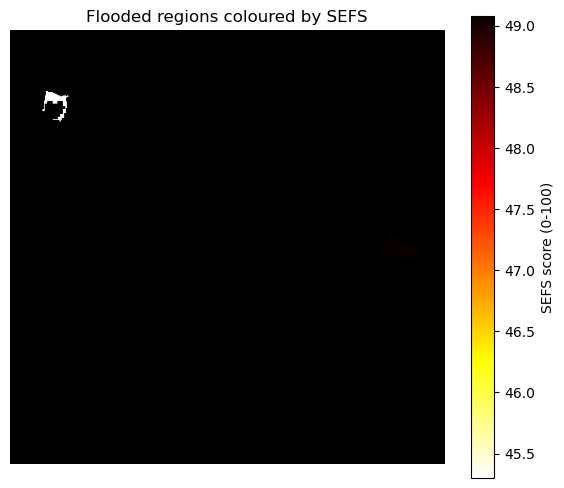

In [128]:
import subprocess, numpy as np, rasterio
from scipy.ndimage import label, distance_transform_edt
from scipy.stats import rankdata
import matplotlib.pyplot as plt

# ---- 1. align the new layers to the chip grid ----
ndvi_layer  = np.nan_to_num(to_chip_grid("GIS_Data/ghana_ndvi_change.tif",  Resampling.bilinear))
mndwi_layer = np.nan_to_num(to_chip_grid("GIS_Data/ghana_mndwi_change.tif", Resampling.bilinear))
ndbi_layer  = np.nan_to_num(to_chip_grid("GIS_Data/ghana_ndbi_change.tif",  Resampling.bilinear))
hand_layer  = np.nan_to_num(to_chip_grid("GIS_Data/ghana_hand.tif",         Resampling.bilinear))
lc          = to_chip_grid("GIS_Data/ghana_landcover.tif", Resampling.nearest)
cropland_layer = (lc == 40).astype("float32")
builtup_layer  = (lc == 50).astype("float32")

# ---- 2. flood mask from the ground-truth label (U-Net comes later) ----
def find(name):
    out = subprocess.run(["mdfind", "-name", name], capture_output=True, text=True).stdout.split("\n")
    return [p for p in out if p.endswith(name)][0]

with rasterio.open(find("Ghana_103272_LabelHand.tif"))    as s: lab = s.read(1)
with rasterio.open(find("Ghana_103272_JRCWaterHand.tif")) as s: jrc = s.read(1)

three = np.zeros_like(lab, dtype=np.uint8)
three[lab == 1] = 2
three[(lab == 1) & (jrc == 1)] = 1
three[lab == -1] = 255
flood_mask = (three == 2)
print("flooded pixels:", int(flood_mask.sum()), "| permanent water pixels:", int((jrc == 1).sum()))

# ---- 3. assemble the evidence layers ----
layers = {
    "population":      (pop_layer, True),
    "roads":           (road_layer, True),
    "elevation":       (elev_layer, False),
    "slope":           (slope_layer, False),
    "HAND":            (hand_layer, False),
    "vegetation_loss": (ndvi_layer, False),    # more negative = more loss
    "new_water_MNDWI": (mndwi_layer, True),
    "builtup_NDBI":    (ndbi_layer, True),
    "cropland":        (cropland_layer, True),
}
if (jrc == 1).sum() > 0:
    layers["dist_perm_water"] = (distance_transform_edt(jrc != 1).astype("float32"), False)

for k, (a, _) in layers.items():
    print(f"{k:16s} min {a.min():9.3f}  max {a.max():9.3f}")

weights = {k: 1 / len(layers) for k in layers}   # equal weights as a neutral start

# ---- 4. SEFS ----
def relevance_map(arr, higher_is_relevant=True):
    r = rankdata(arr.ravel()).reshape(arr.shape) / arr.size
    return r if higher_is_relevant else 1 - r

def sefs(flood_mask, layers, weights, min_pixels=50):
    rel = {k: relevance_map(a, hi) for k, (a, hi) in layers.items()}
    regions, n = label(flood_mask)
    out = []
    for rid in range(1, n + 1):
        m = regions == rid
        if m.sum() < min_pixels:
            continue
        contrib = {k: weights[k] * rel[k][m].mean() for k in rel}
        out.append({"region": rid, "pixels": int(m.sum()), "sefs": 100 * sum(contrib.values()),
                    "evidence_rank": sorted(contrib.items(), key=lambda t: -t[1])})
    return sorted(out, key=lambda d: -d["sefs"]), regions

results, regions = sefs(flood_mask, layers, weights)
print("\nregions scored:", len(results))
for r in results[:8]:
    top3 = ", ".join(f"{n} {c:.3f}" for n, c in r["evidence_rank"][:3])
    print(f"Region {r['region']:4d} | {r['pixels']:6d} px | SEFS {r['sefs']:5.1f} | top: {top3}")

# ---- 5. map: flooded regions coloured by SEFS ----
score_map = np.full(flood_mask.shape, np.nan)
for r in results:
    score_map[regions == r["region"]] = r["sefs"]
plt.figure(figsize=(7, 6))
plt.imshow(np.zeros(flood_mask.shape), cmap="gray", vmin=0, vmax=1)
im = plt.imshow(score_map, cmap="hot_r")
plt.colorbar(im, label="SEFS score (0-100)")
plt.title("Flooded regions coloured by SEFS")
plt.axis("off")
plt.show()

In [129]:
import glob, rasterio, numpy as np
files = glob.glob("/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/S1Hand/S1Hand/Ghana_*_S1Hand.tif")
print(len(files), "Ghana chips")
b = np.array([list(rasterio.open(f).bounds) for f in files])
print("west", b[:,0].min(), "south", b[:,1].min(), "east", b[:,2].max(), "north", b[:,3].max())

53 Ghana chips
west -1.83974970187678 south 8.27887365844551 east -0.27596245528151697 north 10.808529498526083


In [130]:
import glob, os, rasterio, numpy as np
from rasterio.warp import transform_bounds

N_CHIPS = 53
chip_files = sorted(glob.glob("/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/S1Hand/S1Hand/Ghana_*_S1Hand.tif"))[:N_CHIPS]

pop_ic = (ee.ImageCollection("WorldPop/GP/100m/pop")
            .filter(ee.Filter.eq("country", "GHA")).filter(ee.Filter.eq("year", 2018)).first())
dem = ee.Image("USGS/SRTMGL1_003")
hand = ee.Image("MERIT/Hydro/v1_0_1").select("hnd")
wc = ee.ImageCollection("ESA/WorldCover/v100").first().select("Map")
s2_all = ee.ImageCollection("COPERNICUS/S2_HARMONIZED")

def download(img, folder, name, scale, region):
    path = f"{folder}/{name}.tif"
    if os.path.exists(path):
        return
    url = img.clip(region).getDownloadURL({"region": region, "scale": scale,
                                           "crs": "EPSG:4326", "format": "GEO_TIFF"})
    open(path, "wb").write(requests.get(url).content)

for f in chip_files:
    chip_id = os.path.basename(f).replace("_S1Hand.tif", "")
    folder = f"GIS_Data/chips/{chip_id}"
    os.makedirs(folder, exist_ok=True)
    with rasterio.open(f) as src:
        w, s, e, n = transform_bounds(src.crs, "EPSG:4326", *src.bounds)
    region = ee.Geometry.Rectangle([w, s, e, n])
    try:
        download(pop_ic, folder, "pop", 100, region)
        download(dem, folder, "elevation", 30, region)
        download(ee.Terrain.slope(dem), folder, "slope", 30, region)
        download(hand, folder, "hand", 90, region)
        download(wc, folder, "landcover", 10, region)

        col = s2_all.filterBounds(region).filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 90))
        bc, ac = col.filterDate("2018-09-04", "2018-09-16"), col.filterDate("2018-09-17", "2018-09-30")
        if bc.size().getInfo() > 0 and ac.size().getInfo() > 0:
            b_img, a_img = bc.median(), ac.median()
            for k, bands in {"ndvi": ["B8", "B4"], "mndwi": ["B3", "B11"], "ndbi": ["B11", "B8"]}.items():
                diff = a_img.normalizedDifference(bands).subtract(b_img.normalizedDifference(bands))
                download(diff, folder, f"{k}_change", 10, region)
            print("done", chip_id)
        else:
            print("done (no Sentinel-2 for this chip):", chip_id)
    except Exception as ex:
        print("FAILED", chip_id, "->", str(ex)[:120])

done Ghana_103272
done Ghana_1033830
done Ghana_1078550
done Ghana_1089161
done Ghana_11745
done Ghana_124834
done Ghana_128663
done Ghana_132163
done Ghana_134751
done Ghana_135389
done Ghana_141271
done Ghana_141910
done Ghana_142312
done Ghana_144050
done Ghana_146222
done Ghana_147015
done Ghana_154838
done Ghana_156478
done Ghana_161233
done Ghana_167233
done Ghana_168875
done Ghana_187318
done Ghana_194723
done Ghana_234935
done Ghana_247288
done Ghana_24858
done Ghana_26376
done Ghana_264787
done Ghana_277
done Ghana_308249
done Ghana_313799
done Ghana_319168
done Ghana_359826
done Ghana_362274
done Ghana_406026
done Ghana_45911
done Ghana_495107
done Ghana_49890
done Ghana_5079
done Ghana_53713
done Ghana_597288
done Ghana_61925
done Ghana_7496
done Ghana_8090
done Ghana_83200
done Ghana_83483
done Ghana_866994
done Ghana_868803
done Ghana_887131
done Ghana_895194
done Ghana_953791
done Ghana_97059
done Ghana_97516


In [131]:
import subprocess, os, glob, numpy as np, pandas as pd, rasterio
from rasterio.warp import reproject, Resampling
from scipy.ndimage import label, distance_transform_edt
from scipy.stats import rankdata

def find(name):
    out = subprocess.run(["mdfind", "-name", name], capture_output=True, text=True).stdout.split("\n")
    hits = [p for p in out if p.endswith(name)]
    return hits[0] if hits else None

def align(path, method, H, W, tf, crs):
    out = np.zeros((H, W), dtype=np.float32)
    with rasterio.open(path) as src:
        reproject(rasterio.band(src, 1), out, src_transform=src.transform, src_crs=src.crs,
                  dst_transform=tf, dst_crs=crs, resampling=method)
    return np.nan_to_num(out)

def rel_map(arr, higher=True):
    r = rankdata(arr.ravel()).reshape(arr.shape) / arr.size
    return r if higher else 1 - r

rows = []
for f in chip_files:
    cid = os.path.basename(f).replace("_S1Hand.tif", "")
    folder = f"GIS_Data/chips/{cid}"
    lab_p, jrc_p = find(f"{cid}_LabelHand.tif"), find(f"{cid}_JRCWaterHand.tif")
    if not lab_p or not jrc_p:
        print("missing label/JRC for", cid); continue

    with rasterio.open(f) as ref:
        H, W, tf, crs = ref.height, ref.width, ref.transform, ref.crs
    with rasterio.open(lab_p) as s: lab = s.read(1)
    with rasterio.open(jrc_p) as s: jrc = s.read(1)
    flood = (lab == 1) & (jrc != 1)          # flooded land only (excludes permanent water)

    L = {}   # name -> (array, higher_is_relevant)
    pop = align(f"{folder}/pop.tif", Resampling.nearest, H, W, tf, crs)
    L["population"]      = (np.where(pop < 0, 0, pop), True)
    L["elevation"]       = (align(f"{folder}/elevation.tif", Resampling.bilinear, H, W, tf, crs), False)
    L["slope"]           = (align(f"{folder}/slope.tif",     Resampling.bilinear, H, W, tf, crs), False)
    L["HAND"]            = (align(f"{folder}/hand.tif",      Resampling.bilinear, H, W, tf, crs), False)
    lc = align(f"{folder}/landcover.tif", Resampling.nearest, H, W, tf, crs)
    L["cropland"]        = ((lc == 40).astype("float32"), True)
    L["builtup_landcover"] = ((lc == 50).astype("float32"), True)
    if os.path.exists(f"{folder}/ndvi_change.tif"):
        L["vegetation_loss"] = (align(f"{folder}/ndvi_change.tif",  Resampling.bilinear, H, W, tf, crs), False)
        L["new_water_MNDWI"] = (align(f"{folder}/mndwi_change.tif", Resampling.bilinear, H, W, tf, crs), True)
        L["builtup_NDBI"]    = (align(f"{folder}/ndbi_change.tif",  Resampling.bilinear, H, W, tf, crs), True)
    if (jrc == 1).any():
        L["dist_perm_water"] = (distance_transform_edt(jrc != 1).astype("float32"), False)

    rel = {k: rel_map(a, hi) for k, (a, hi) in L.items()}
    w = 1 / len(L)
    regions, n = label(flood)
    for rid in range(1, n + 1):
        m = regions == rid
        if m.sum() < 50:
            continue
        contrib = {k: w * rel[k][m].mean() for k in rel}
        rows.append({"chip": cid, "region": rid, "pixels": int(m.sum()),
                     "sefs": 100 * sum(contrib.values()),
                     "top_evidence": max(contrib, key=contrib.get), **contrib})
    print(cid, "-> flooded px:", int(flood.sum()), "| regions so far:", len(rows))

df = pd.DataFrame(rows)
df.to_csv("GIS_Data/sefs_results.csv", index=False)
print("\nTotal flooded regions scored:", len(df), "across", df["chip"].nunique(), "chips")
if len(df):
    print("\nHow often each layer is the TOP evidence:")
    print(df["top_evidence"].value_counts())
    print("\nAverage contribution per layer (higher = more relevant to flooded regions):")
    cols = [c for c in df.columns if c not in ("chip","region","pixels","sefs","top_evidence")]
    print(df[cols].mean().sort_values(ascending=False).round(4))

Ghana_103272 -> flooded px: 1183 | regions so far: 2
Ghana_1033830 -> flooded px: 94371 | regions so far: 8
Ghana_1078550 -> flooded px: 1407 | regions so far: 14
Ghana_1089161 -> flooded px: 2907 | regions so far: 18
Ghana_11745 -> flooded px: 0 | regions so far: 18
Ghana_124834 -> flooded px: 0 | regions so far: 18
Ghana_128663 -> flooded px: 0 | regions so far: 18
Ghana_132163 -> flooded px: 0 | regions so far: 18
Ghana_134751 -> flooded px: 0 | regions so far: 18
Ghana_135389 -> flooded px: 252 | regions so far: 19
Ghana_141271 -> flooded px: 1636 | regions so far: 20
Ghana_141910 -> flooded px: 68954 | regions so far: 28
Ghana_142312 -> flooded px: 0 | regions so far: 28
Ghana_144050 -> flooded px: 0 | regions so far: 28
Ghana_146222 -> flooded px: 0 | regions so far: 28
Ghana_147015 -> flooded px: 3530 | regions so far: 29
Ghana_154838 -> flooded px: 0 | regions so far: 29
Ghana_156478 -> flooded px: 0 | regions so far: 29
Ghana_161233 -> flooded px: 0 | regions so far: 29
Ghana_

In [132]:
import rasterio, numpy as np
with rasterio.open("GIS_Data/chips/Ghana_1033830/mndwi_change.tif") as s:
    m = s.read(1)
print("MNDWI change: mean", np.nanmean(m), "| 5th-95th percentile", np.nanpercentile(m, [5, 95]))

MNDWI change: mean -0.10266116 | 5th-95th percentile [-0.32521619  0.32243548]


In [133]:
import numpy as np
import pandas as pd

df = pd.read_csv("GIS_Data/sefs_results.csv")

layer_cols = [
    c for c in df.columns
    if c not in ("chip", "region", "pixels", "sefs", "top_evidence")
]

# Recover the average percentile scores
n_layers = df[layer_cols].notna().sum(axis=1)
pct = df[layer_cols].mul(n_layers, axis=0)

# 1. Check missing values
print("=== MISSING VALUES ===")
print(df[layer_cols].isna().sum().to_string())
print("\nNumber of regions:", len(df))
print("Number of chips:", df["chip"].nunique())

# 2. Calculate average scores for each chip
per_chip = pct.groupby(df["chip"]).mean()

print("\n=== PER-CHIP MEAN PERCENTILES ===")
print(per_chip.mean().sort_values(ascending=False).round(3))

# 3. Bootstrap confidence intervals by chip
rng = np.random.default_rng(42)
n_boot = 2000
rows = []

for layer in layer_cols:
    values = per_chip[layer].dropna().to_numpy()
    boot_means = np.array([
        rng.choice(values, size=len(values), replace=True).mean()
        for _ in range(n_boot)
    ])

    rows.append({
        "layer": layer,
        "mean_pct": values.mean(),
        "ci_low": np.percentile(boot_means, 2.5),
        "ci_high": np.percentile(boot_means, 97.5),
        "chips": len(values)
    })

chip_ci = pd.DataFrame(rows).sort_values(
    "mean_pct", ascending=False
)

print("\n=== CHIP-LEVEL 95% CONFIDENCE INTERVALS ===")
print(chip_ci.round(3).to_string(index=False))

# 4. Random-weight sensitivity with missing values handled
wins = pd.Series(0, index=layer_cols, dtype=float)
n_regions = len(pct)

for _ in range(1000):
    weights = pd.Series(
        rng.dirichlet(np.ones(len(layer_cols))),
        index=layer_cols
    )

    # Only use available layers for each region
    scores = pct.mul(weights, axis=1)
    scores = scores.where(pct.notna())

    # Renormalize weights across available layers
    row_weight_sum = pct.notna().mul(weights, axis=1).sum(axis=1)
    scores = scores.div(row_weight_sum, axis=0)

    winners = scores.idxmax(axis=1)
    wins += winners.value_counts().reindex(
        layer_cols, fill_value=0
    )

print("\n=== RANDOM-WEIGHT TOP-EVIDENCE SHARE ===")
print((wins / (1000 * n_regions)).sort_values(
    ascending=False
).round(3).to_string())

=== MISSING VALUES ===
population             0
elevation              0
slope                  0
HAND                   0
cropland               0
builtup_landcover      0
vegetation_loss        0
new_water_MNDWI        0
builtup_NDBI           0
dist_perm_water      106

Number of regions: 157
Number of chips: 26

=== PER-CHIP MEAN PERCENTILES ===
elevation            0.765
HAND                 0.726
vegetation_loss      0.700
dist_perm_water      0.638
new_water_MNDWI      0.636
population           0.576
builtup_NDBI         0.527
builtup_landcover    0.498
cropland             0.485
slope                0.472
dtype: float64

=== CHIP-LEVEL 95% CONFIDENCE INTERVALS ===
            layer  mean_pct  ci_low  ci_high  chips
        elevation     0.765   0.711    0.816     26
             HAND     0.726   0.658    0.788     26
  vegetation_loss     0.700   0.602    0.792     26
  dist_perm_water     0.638   0.469    0.796     11
  new_water_MNDWI     0.636   0.540    0.722     26
      

In [134]:
print("U-Net model loaded:", "unet" in globals())
print("Patch-trained model loaded:", "patch_model" in globals())
print("Validation loader ready:", "valid_loader" in globals())
print("Test loader ready:", "test_loader" in globals())
print("Chip files available:", "chip_files" in globals())

if "unet" in globals():
    print("U-Net device:", next(unet.parameters()).device)

if "patch_model" in globals():
    print("Patch U-Net device:", next(patch_model.parameters()).device)

U-Net model loaded: False
Patch-trained model loaded: True
Validation loader ready: True
Test loader ready: True
Chip files available: True
Patch U-Net device: cpu


In [135]:
print(type(patch_model))
print(patch_model)

<class '__main__.UNet'>
UNet(
  (enc1): Sequential(
    (0): Conv2d(2, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (enc2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (enc3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (bottleneck): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(

In [136]:
print("Model device:", next(patch_model.parameters()).device)
print("Validation batches:", len(valid_loader))
print("Test batches:", len(test_loader))

Model device: cpu
Validation batches: 23
Test batches: 23


In [137]:
import os

for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d not in {".git", "__pycache__"}]
    for f in files:
        if f.endswith((".pth", ".pt", ".ckpt")):
            print(os.path.join(root, f))

./unet_10epoch.pth
./segformer_weighted_best.pth
./segformer_patch_weighted_experiment.pth
./unet_patch_weighted_experiment.pth
./segformer_best_backup.pth
./segformer_smoketest.pth
./unet_10epoch_new.pth
./segformer_best.pth


In [138]:
%history -n

   1:
import numpy as np

# Classify water pixels using MNDWI
water_before = (mndwi_before > 0) & shared_clear
water_after = (mndwi_after > 0) & shared_clear

# Count classified pixels
print("Before water pixels:", np.sum(water_before))
print("After water pixels:", np.sum(water_after))

# Estimate water area (each pixel is 10 m × 10 m = 100 m²)
pixel_area_m2 = 100

before_area_ha = np.sum(water_before) * pixel_area_m2 / 10000
after_area_ha = np.sum(water_after) * pixel_area_m2 / 10000

print(f"Before water area: {before_area_ha:.2f} hectares")
print(f"After water area: {after_area_ha:.2f} hectares")
   2:
import numpy as np
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.mask import mask
from shapely.geometry import box, mapping
from rasterio.warp import transform_bounds

def calculate_ndbi(folder):
    folder = Path(folder)

    b08_path = next(folder.rglob("*_B08_10m.jp2"))
    b11_path = next(folder.rglob("*_B11_20m.jp2"))

    with rasterio.open(b08_pa

In [140]:
from pathlib import Path
import torch

unet_path = Path.cwd() / "unet_10epoch.pth"
print("Checkpoint exists:", unet_path.exists())

if unet_path.exists():
    unet = UNet(in_channels=2, num_classes=3)
    state = torch.load(unet_path, map_location="cpu", weights_only=True)
    unet.load_state_dict(state)
    unet.eval()
    print("U-Net checkpoint loaded successfully")
else:
    print("Checkpoint not found. Check the notebook's working directory.")

Checkpoint exists: True
U-Net checkpoint loaded successfully


In [141]:
print("U-Net loaded:", "unet" in globals())
print("Model mode:", "eval" if not unet.training else "train")
print("Validation batches:", len(valid_loader))
print("Test batches:", len(test_loader))

U-Net loaded: True
Model mode: eval
Validation batches: 23
Test batches: 23


In [142]:
batch = next(iter(test_loader))

print("Batch type:", type(batch))

if isinstance(batch, (tuple, list)):
    for i, item in enumerate(batch):
        if hasattr(item, "shape"):
            print(f"Item {i} shape:", item.shape)
        else:
            print(f"Item {i} type:", type(item))

Batch type: <class 'list'>
Item 0 shape: torch.Size([4, 2, 512, 512])
Item 1 shape: torch.Size([4, 512, 512])


In [143]:
import torch

images, labels = next(iter(test_loader))

with torch.no_grad():
    logits = unet(images)
    predictions = torch.argmax(logits, dim=1)

print("Logits shape:", logits.shape)
print("Predictions shape:", predictions.shape)
print("True label classes:", torch.unique(labels))
print("Predicted classes:", torch.unique(predictions))

Logits shape: torch.Size([4, 3, 512, 512])
Predictions shape: torch.Size([4, 512, 512])
True label classes: tensor([  0,   2, 255])
Predicted classes: tensor([0, 2])


In [144]:
for i in range(len(images)):
    print(f"\nImage {i}")

    for cls in [0, 1, 2, 255]:
        true_count = (labels[i] == cls).sum().item()
        pred_count = (predictions[i] == cls).sum().item()

        print(
            f"Class {cls}: "
            f"Ground truth = {true_count} pixels, "
            f"Prediction = {pred_count} pixels"
        )


Image 0
Class 0: Ground truth = 229531 pixels, Prediction = 262143 pixels
Class 1: Ground truth = 0 pixels, Prediction = 0 pixels
Class 2: Ground truth = 14933 pixels, Prediction = 1 pixels
Class 255: Ground truth = 17680 pixels, Prediction = 0 pixels

Image 1
Class 0: Ground truth = 260737 pixels, Prediction = 262141 pixels
Class 1: Ground truth = 0 pixels, Prediction = 0 pixels
Class 2: Ground truth = 1407 pixels, Prediction = 3 pixels
Class 255: Ground truth = 0 pixels, Prediction = 0 pixels

Image 2
Class 0: Ground truth = 27394 pixels, Prediction = 262143 pixels
Class 1: Ground truth = 0 pixels, Prediction = 0 pixels
Class 2: Ground truth = 0 pixels, Prediction = 1 pixels
Class 255: Ground truth = 234750 pixels, Prediction = 0 pixels

Image 3
Class 0: Ground truth = 258648 pixels, Prediction = 262123 pixels
Class 1: Ground truth = 0 pixels, Prediction = 0 pixels
Class 2: Ground truth = 3496 pixels, Prediction = 21 pixels
Class 255: Ground truth = 0 pixels, Prediction = 0 pixels


In [145]:
from collections import Counter
import torch

pred_counts = Counter()
true_counts = Counter()

unet.eval()

with torch.no_grad():
    for images, labels in test_loader:
        predictions = unet(images).argmax(dim=1)

        for c in [0, 1, 2, 255]:
            pred_counts[c] += (predictions == c).sum().item()
            true_counts[c] += (labels == c).sum().item()

print("Predicted pixels:", pred_counts)
print("Ground-truth pixels:", true_counts)

Predicted pixels: Counter({0: 22629240, 1: 558818, 2: 404902, 255: 0})
Ground-truth pixels: Counter({0: 17951266, 255: 3075593, 2: 1666703, 1: 899398})


In [146]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import torch

y_true, y_pred = [], []
unet.eval()

with torch.no_grad():
    for images, labels in test_loader:
        predictions = unet(images).argmax(dim=1)

        valid = (labels != 255)
        y_true.extend(labels[valid].cpu().numpy())
        y_pred.extend(predictions[valid].cpu().numpy())

print("Confusion matrix (classes 0, 1, 2):")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2]))

print(classification_report(
    y_true, y_pred,
    labels=[0, 1, 2],
    target_names=["No water", "Permanent water", "Flooded water"],
    zero_division=0
))

Confusion matrix (classes 0, 1, 2):
[[17903482    21042    26742]
 [  708923        0   190475]
 [ 1511092    50479   105132]]
                 precision    recall  f1-score   support

       No water       0.89      1.00      0.94  17951266
Permanent water       0.00      0.00      0.00    899398
  Flooded water       0.33      0.06      0.11   1666703

       accuracy                           0.88  20517367
      macro avg       0.41      0.35      0.35  20517367
   weighted avg       0.80      0.88      0.83  20517367



In [147]:
print("Model output classes:", unet.final.out_channels)
print("Dataset class counts:", true_counts)

# Inspect the dataset class-mapping function
import inspect
print(inspect.getsource(make_three_class_label))

Model output classes: 3
Dataset class counts: Counter({0: 17951266, 255: 3075593, 2: 1666703, 1: 899398})
def make_three_class_label(label_path, jrc_path):
    with rasterio.open(label_path) as src:
        label = src.read(1)

    with rasterio.open(jrc_path) as src:
        jrc = src.read(1)

    three_class = np.zeros_like(label, dtype=np.uint8)

    # Water → initially Flooded Land
    three_class[label == 1] = 2

    # Water + JRC permanent water → Permanent Water
    three_class[(label == 1) & (jrc == 1)] = 1

    # Label NoData
    three_class[label == -1] = 255

    return three_class



In [148]:
import torch

checkpoint = torch.load(
    "unet_10epoch.pth",
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))
if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys())[:20])

Checkpoint type: <class 'collections.OrderedDict'>
Checkpoint keys: ['enc1.0.weight', 'enc1.0.bias', 'enc1.2.weight', 'enc1.2.bias', 'enc2.0.weight', 'enc2.0.bias', 'enc2.2.weight', 'enc2.2.bias', 'enc3.0.weight', 'enc3.0.bias', 'enc3.2.weight', 'enc3.2.bias', 'bottleneck.0.weight', 'bottleneck.0.bias', 'bottleneck.2.weight', 'bottleneck.2.bias', 'up3.weight', 'up3.bias', 'dec3.0.weight', 'dec3.0.bias']


In [149]:

for i, cell in enumerate(In):
    code = str(cell)
    if any(term in code.lower() for term in [
        "criterion", "crossentropyloss",
        "optimizer", "loss.backward"
    ]):
        print(f"\n--- Cell {i} ---\n{code[:1800]}")


--- Cell 101 ---
import torch
import torch.nn as nn

# ============================================
# WEIGHTED CROSS ENTROPY LOSS
# ============================================

criterion_ce = nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=255
)

print("Weighted Cross Entropy Loss ready")
print("Class weights:", class_weights)
print("Ignore index: 255")

--- Cell 103 ---
# ============================================
# COMBINED LOSS
# ============================================

def combined_loss(pred, target):

    ce_loss = criterion_ce(pred, target)

    d_loss = dice_loss(pred, target)

    total_loss = ce_loss + d_loss

    return total_loss


print("Combined Loss function ready")

--- Cell 106 ---
# ============================================
# OPTIMIZER + TRAINING SETUP
# ============================================

import torch.optim as optim

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

device = torch.device("cuda" if torch.cuda.is_avail

In [150]:
print("Class weights:", class_weights)
print("Criterion:", criterion_ce)

Class weights: tensor([0.4046, 5.1399, 2.9943])
Criterion: CrossEntropyLoss()


In [151]:
# Find the original U-Net training loop and loss usage
for i, cell in enumerate(In):
    code = str(cell)
    if "loss.backward()" in code or "criterion_ce(" in code:
        print(f"\n--- Cell {i} ---\n{code[:2500]}")


--- Cell 103 ---
# ============================================
# COMBINED LOSS
# ============================================

def combined_loss(pred, target):

    ce_loss = criterion_ce(pred, target)

    d_loss = dice_loss(pred, target)

    total_loss = ce_loss + d_loss

    return total_loss


print("Combined Loss function ready")

--- Cell 108 ---
###model training

import torch
from pathlib import Path

# Separate optimizer for the experimental model
patch_optimizer = torch.optim.Adam(
    patch_model.parameters(),
    lr=1e-4
)

patch_criterion = torch.nn.CrossEntropyLoss(ignore_index=255)

patch_epochs = 5
patch_history = []

for epoch in range(patch_epochs):
    patch_model.train()
    running_loss = 0.0

    for images, masks in patch_train_loader:
        images = images.to(device)
        masks = masks.to(device)

        patch_optimizer.zero_grad()

        outputs = patch_model(images)
        loss = patch_criterion(outputs, masks)

        loss.backward()
        patc

In [152]:
print("Main U-Net loaded:", "unet" in globals())
print("Patch model loaded:", "patch_model" in globals())

print("\nCheckpoint files:")
from pathlib import Path
for p in Path.cwd().glob("*.pth"):
    print(p.name)

Main U-Net loaded: True
Patch model loaded: True

Checkpoint files:
unet_10epoch.pth
segformer_weighted_best.pth
segformer_patch_weighted_experiment.pth
unet_patch_weighted_experiment.pth
segformer_best_backup.pth
segformer_smoketest.pth
unet_10epoch_new.pth
segformer_best.pth


In [153]:
from sklearn.metrics import confusion_matrix, classification_report
import torch
import numpy as np

unet.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(next(unet.parameters()).device)
        predictions = unet(images).argmax(dim=1)

        valid = masks != 255
        y_true.extend(masks[valid].cpu().numpy())
        y_pred.extend(predictions[valid].cpu().numpy())

print("Confusion matrix (classes 0, 1, 2):")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2]))

print(classification_report(
    y_true, y_pred,
    labels=[0, 1, 2],
    target_names=["No water", "Permanent water", "Flooded water"],
    zero_division=0
))

Confusion matrix (classes 0, 1, 2):
[[17903482    21042    26742]
 [  708923        0   190475]
 [ 1511092    50479   105132]]
                 precision    recall  f1-score   support

       No water       0.89      1.00      0.94  17951266
Permanent water       0.00      0.00      0.00    899398
  Flooded water       0.33      0.06      0.11   1666703

       accuracy                           0.88  20517367
      macro avg       0.41      0.35      0.35  20517367
   weighted avg       0.80      0.88      0.83  20517367



In [155]:
import inspect
print(inspect.getsource(make_three_class_label))

def make_three_class_label(label_path, jrc_path):
    with rasterio.open(label_path) as src:
        label = src.read(1)

    with rasterio.open(jrc_path) as src:
        jrc = src.read(1)

    three_class = np.zeros_like(label, dtype=np.uint8)

    # Water → initially Flooded Land
    three_class[label == 1] = 2

    # Water + JRC permanent water → Permanent Water
    three_class[(label == 1) & (jrc == 1)] = 1

    # Label NoData
    three_class[label == -1] = 255

    return three_class



In [156]:
import numpy as np
import rasterio

print("Label values:", np.unique(label, return_counts=True))
print("JRC values:", np.unique(jrc, return_counts=True))

Label values: (array([<function label at 0x30f979c60>], dtype=object), array([1]))
JRC values: (array([0, 1], dtype=uint8), array([261973,    171]))


In [158]:
import numpy as np
import rasterio
from pathlib import Path

data_root = Path("/Users/pramodithakathari/Desktop/Sen1Floods11/v1.1")

label_path = data_root / "LabelHand/LabelHand/Mekong_382276_LabelHand.tif"
jrc_path = data_root / "JRCWaterHand/JRCWaterHand/Mekong_382276_JRCWaterHand.tif"

with rasterio.open(label_path) as src:
    label_arr = src.read(1)

with rasterio.open(jrc_path) as src:
    jrc_arr = src.read(1)

print("Label:", np.unique(label_arr, return_counts=True))
print("JRC:", np.unique(jrc_arr, return_counts=True))
print("JRC=1 overlapping label=1:",
      np.sum((label_arr == 1) & (jrc_arr == 1)))

Label: (array([-1,  0,  1], dtype=int16), array([    33, 252303,   9808]))
JRC: (array([0], dtype=uint8), array([262144]))
JRC=1 overlapping label=1: 0


In [159]:
print("Training loader exists:", "train_loader" in globals())
print("Patch training loader exists:", "patch_train_loader" in globals())
print("Main U-Net checkpoint:", Path("unet_10epoch.pth").exists())
print("Current U-Net output classes:", unet.final.out_channels)
print("Class weights:", class_weights)

Training loader exists: True
Patch training loader exists: True
Main U-Net checkpoint: True
Current U-Net output classes: 3
Class weights: tensor([0.4046, 5.1399, 2.9943])


In [161]:
from pathlib import Path

print("SEFS-related notebook variables:")
for name in globals():
    if "sefs" in name.lower() or "gis" in name.lower():
        print(name, type(globals()[name]).__name__)

print("\nExisting SEFS CSV files:")
for p in Path.cwd().rglob("*sefs*.csv"):
    print(p)

SEFS-related notebook variables:
sefs function

Existing SEFS CSV files:
/Users/pramodithakathari/GeoMind-AI-v7/GIS_Data/sefs_results.csv


In [162]:
import inspect
import pandas as pd

print(inspect.getsource(sefs))

sefs_df = pd.read_csv("GIS_Data/sefs_results.csv")
print("\nCSV shape:", sefs_df.shape)
print("Columns:", sefs_df.columns.tolist())
display(sefs_df.head())

def sefs(flood_mask, layers, weights, min_pixels=50):
    rel = {k: relevance_map(a, hi) for k, (a, hi) in layers.items()}
    regions, n = label(flood_mask)
    out = []
    for rid in range(1, n + 1):
        m = regions == rid
        if m.sum() < min_pixels:
            continue
        contrib = {k: weights[k] * rel[k][m].mean() for k in rel}
        out.append({"region": rid, "pixels": int(m.sum()), "sefs": 100 * sum(contrib.values()),
                    "evidence_rank": sorted(contrib.items(), key=lambda t: -t[1])})
    return sorted(out, key=lambda d: -d["sefs"]), regions


CSV shape: (157, 15)
Columns: ['chip', 'region', 'pixels', 'sefs', 'top_evidence', 'population', 'elevation', 'slope', 'HAND', 'cropland', 'builtup_landcover', 'vegetation_loss', 'new_water_MNDWI', 'builtup_NDBI', 'dist_perm_water']


,chip,region,pixels,sefs,top_evidence,population,elevation,slope,HAND,cropland,builtup_landcover,vegetation_loss,new_water_MNDWI,builtup_NDBI,dist_perm_water
0,Ghana_103272,1,383,45.869964,dist_perm_water,0.002353,0.076078,0.020427,0.093109,0.013350,0.048537,0.011689,0.006520,0.087010,0.099625
1,Ghana_103272,3,797,49.248344,builtup_NDBI,0.072733,0.056599,0.053952,0.087666,0.030881,0.048537,0.003425,0.001146,0.098361,0.039183
2,Ghana_1033830,1,79097,56.165524,vegetation_loss,0.046778,0.067428,0.045107,0.067844,0.046661,0.050000,0.069956,0.062469,0.044637,0.060775
3,Ghana_1033830,6,110,56.180466,elevation,0.023425,0.080596,0.044446,0.076951,0.070131,0.050000,0.065029,0.064383,0.060952,0.025891
4,Ghana_1033830,42,1247,61.317033,new_water_MNDWI,0.062600,0.069147,0.057257,0.066389,0.067691,0.050000,0.066836,0.071640,0.038430,0.063181


In [163]:
print(inspect.getsource(relevance_map))

def relevance_map(arr, higher_is_relevant=True):
    r = rankdata(arr.ravel()).reshape(arr.shape) / arr.size
    return r if higher_is_relevant else 1 - r



In [164]:
for name, obj in globals().copy().items():
    if isinstance(obj, dict):
        keys = list(obj.keys())
        if keys and any(
            k in [
                "population", "elevation", "slope", "HAND",
                "cropland", "builtup_landcover", "vegetation_loss",
                "new_water_MNDWI", "builtup_NDBI", "dist_perm_water"
            ]
            for k in keys
        ):
            print(name, "→", keys)

layers → ['population', 'roads', 'elevation', 'slope', 'HAND', 'vegetation_loss', 'new_water_MNDWI', 'builtup_NDBI', 'cropland', 'dist_perm_water']
L → ['population', 'elevation', 'slope', 'HAND', 'cropland', 'builtup_landcover', 'vegetation_loss', 'new_water_MNDWI', 'builtup_NDBI', 'dist_perm_water']
rel → ['population', 'elevation', 'slope', 'HAND', 'cropland', 'builtup_landcover', 'vegetation_loss', 'new_water_MNDWI', 'builtup_NDBI', 'dist_perm_water']
contrib → ['population', 'elevation', 'slope', 'HAND', 'cropland', 'builtup_landcover', 'vegetation_loss', 'new_water_MNDWI', 'builtup_NDBI', 'dist_perm_water']


In [165]:
print("GIS layer chips:", len(chip_files))
print("GIS layer names:", list(layers.keys()))
print("SEFS regions:", len(sefs_df))
print("U-Net test batches:", len(test_loader))

print("\nFirst GIS chip:", chip_files[0] if chip_files else "None")
print("First SEFS chip:", sefs_df["chip"].iloc[0])

GIS layer chips: 53
GIS layer names: ['population', 'roads', 'elevation', 'slope', 'HAND', 'vegetation_loss', 'new_water_MNDWI', 'builtup_NDBI', 'cropland', 'dist_perm_water']
SEFS regions: 157
U-Net test batches: 23

First GIS chip: /Users/pramodithakathari/Desktop/Sen1Floods11/v1.1/S1Hand/S1Hand/Ghana_103272_S1Hand.tif
First SEFS chip: Ghana_103272


In [166]:
gis_chip_ids = {
    Path(p).name.replace("_S1Hand.tif", "")
    for p in chip_files
}

sefs_chip_ids = set(sefs_df["chip"].astype(str))

print("GIS chips:", len(gis_chip_ids))
print("SEFS chips:", len(sefs_chip_ids))
print("Matching chips:", len(gis_chip_ids & sefs_chip_ids))
print("GIS chips without SEFS:", sorted(gis_chip_ids - sefs_chip_ids)[:10])
print("SEFS chips without GIS:", sorted(sefs_chip_ids - gis_chip_ids)[:10])

GIS chips: 53
SEFS chips: 26
Matching chips: 26
GIS chips without SEFS: ['Ghana_11745', 'Ghana_124834', 'Ghana_128663', 'Ghana_132163', 'Ghana_134751', 'Ghana_142312', 'Ghana_144050', 'Ghana_146222', 'Ghana_154838', 'Ghana_156478']
SEFS chips without GIS: []


In [167]:
import torch
import numpy as np

unet.eval()
predicted_masks = []
ground_truth_masks = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(next(unet.parameters()).device)
        predictions = unet(images).argmax(dim=1).cpu().numpy()

        predicted_masks.extend(predictions)
        ground_truth_masks.extend(labels.numpy())

print("Predicted masks:", len(predicted_masks))
print("Ground-truth masks:", len(ground_truth_masks))
print("Mask shape:", predicted_masks[0].shape)

Predicted masks: 90
Ground-truth masks: 90
Mask shape: (512, 512)


In [168]:
from collections import Counter
import numpy as np

pred_counts = Counter()
true_counts = Counter()

for pred, true in zip(predicted_masks, ground_truth_masks):
    for cls in [0, 1, 2]:
        pred_counts[cls] += int((pred == cls).sum())
        true_counts[cls] += int((true == cls).sum())

print("Predicted classes:", pred_counts)
print("Ground-truth classes:", true_counts)

print("\nPredicted flooded pixels (class 2):", pred_counts[2])
print("Ground-truth flooded pixels (class 2):", true_counts[2])

Predicted classes: Counter({0: 22629240, 1: 558818, 2: 404902})
Ground-truth classes: Counter({0: 17951266, 2: 1666703, 1: 899398})

Predicted flooded pixels (class 2): 404902
Ground-truth flooded pixels (class 2): 1666703


In [169]:
print("Test dataset:", type(test_loader.dataset))
print("Dataset attributes:",
      [a for a in dir(test_loader.dataset)
       if any(k in a.lower() for k in ["file", "path", "id", "chip", "label"])])

Test dataset: <class '__main__.ValidationFloodDataset'>
Dataset attributes: []


In [173]:
ds = test_loader.dataset

print("Columns:", ds.samples.columns.tolist())
print(ds.samples.head(3).to_string(index=False))

Columns: ['s1', 'label']
                      s1                       label
 Ghana_313799_S1Hand.tif  Ghana_313799_LabelHand.tif
Ghana_1078550_S1Hand.tif Ghana_1078550_LabelHand.tif
  Ghana_97059_S1Hand.tif   Ghana_97059_LabelHand.tif


In [174]:
from pathlib import Path

test_chip_ids = {
    Path(s1).name.replace("_S1Hand.tif", "")
    for s1 in ds.samples["s1"]
}

print("Test chips:", len(test_chip_ids))
print("Matching SEFS chips:", len(test_chip_ids & set(sefs_df["chip"])))
print("Matching IDs:", sorted(test_chip_ids & set(sefs_df["chip"]))[:10])

Test chips: 90
Matching SEFS chips: 7
Matching IDs: ['Ghana_1078550', 'Ghana_141271', 'Ghana_313799', 'Ghana_319168', 'Ghana_359826', 'Ghana_406026', 'Ghana_866994']


In [175]:
matched = sorted(test_chip_ids & set(sefs_df["chip"]))

print("Matching chips:", len(matched))
print("Matching SEFS regions:", sefs_df[sefs_df["chip"].isin(matched)].shape[0])
print(sefs_df[sefs_df["chip"].isin(matched)][["chip", "region", "pixels", "sefs", "top_evidence"]].head(10))

Matching chips: 7
Matching SEFS regions: 54
             chip  region  pixels       sefs     top_evidence
8   Ghana_1078550      28     133  71.211647  vegetation_loss
9   Ghana_1078550      30      87  62.465384     builtup_NDBI
10  Ghana_1078550      59     352  70.887350       population
11  Ghana_1078550      93      56  72.019440     builtup_NDBI
12  Ghana_1078550     105      75  67.804067     builtup_NDBI
13  Ghana_1078550     134     114  69.817437     builtup_NDBI
19   Ghana_141271       1    1636  62.221025             HAND
45   Ghana_313799      11      99  77.762561       population
46   Ghana_313799      13     165  63.721591  new_water_MNDWI
47   Ghana_313799      20    1004  67.670342  new_water_MNDWI


In [177]:
import os
import numpy as np
import pandas as pd
import rasterio
from pathlib import Path
from scipy.ndimage import label, distance_transform_edt
from rasterio.warp import Resampling

# Match each prediction to its test chip ID
samples = test_loader.dataset.samples.reset_index(drop=True)
sample_ids = [
    Path(x).name.replace("_S1Hand.tif", "")
    for x in samples["s1"]
]
matched = sorted(set(sample_ids) & set(sefs_df["chip"].astype(str)))

pred_rows, gt_rows = [], []

for cid in matched:
    idx = sample_ids.index(cid)
    row = samples.iloc[idx]

    s1_path = os.path.join(s1_folder, row["s1"])
    lab_path = find(f"{cid}_LabelHand.tif")
    jrc_path = find(f"{cid}_JRCWaterHand.tif")
    folder = f"GIS_Data/chips/{cid}"

    if not lab_path or not jrc_path:
        print("Skipping missing label/JRC:", cid)
        continue

    with rasterio.open(s1_path) as src:
        H, W = src.height, src.width
        tf, crs = src.transform, src.crs

    with rasterio.open(lab_path) as src:
        lab = src.read(1)
    with rasterio.open(jrc_path) as src:
        jrc = src.read(1)

    if lab.shape != (H, W) or jrc.shape != (H, W):
        print("Skipping mismatched raster shape:", cid)
        continue

    valid = (lab != -1) & (jrc != 1)
    gt_mask = (lab == 1) & valid
    pred_mask = (predicted_masks[idx] == 2) & valid

    # Rebuild the same GIS evidence layers used by SEFS
    def load_layer(name, method):
        path = f"{folder}/{name}.tif"
        if not os.path.exists(path):
            return None
        return align(path, method, H, W, tf, crs)

    L = {}
    pop = load_layer("pop", Resampling.nearest)
    elev = load_layer("elevation", Resampling.bilinear)
    slope = load_layer("slope", Resampling.bilinear)
    hand = load_layer("hand", Resampling.bilinear)
    lc = load_layer("landcover", Resampling.nearest)

    if pop is not None:
        L["population"] = (np.maximum(pop, 0), True)
    if elev is not None:
        L["elevation"] = (elev, False)
    if slope is not None:
        L["slope"] = (slope, False)
    if hand is not None:
        L["HAND"] = (hand, False)
    if lc is not None:
        L["cropland"] = ((lc == 40).astype(np.float32), True)
        L["builtup_landcover"] = ((lc == 50).astype(np.float32), True)

    ndvi = load_layer("ndvi_change", Resampling.bilinear)
    mndwi = load_layer("mndwi_change", Resampling.bilinear)
    ndbi = load_layer("ndbi_change", Resampling.bilinear)

    if ndvi is not None:
        L["vegetation_loss"] = (ndvi, False)
    if mndwi is not None:
        L["new_water_MNDWI"] = (mndwi, True)
    if ndbi is not None:
        L["builtup_NDBI"] = (ndbi, True)

    if (jrc == 1).any():
        L["dist_perm_water"] = (
            distance_transform_edt(jrc != 1).astype(np.float32), False
        )

    if not L:
        print("No GIS evidence available:", cid)
        continue

    # Same percentile ranking and equal-weight SEFS method
    rel = {k: relevance_map(a, hi) for k, (a, hi) in L.items()}
    weights = {k: 1 / len(L) for k in L}

    for mask, destination, kind in [
        (gt_mask, gt_rows, "ground_truth"),
        (pred_mask, pred_rows, "predicted")
    ]:
        regions, n = label(mask)

        for rid in range(1, n + 1):
            region = regions == rid
            pixels = int(region.sum())

            if pixels < 50:
                continue

            contributions = {
                k: weights[k] * rel[k][region].mean()
                for k in rel
            }

            destination.append({
                "chip": cid,
                "region": rid,
                "pixels": pixels,
                "sefs": 100 * sum(contributions.values()),
                "top_evidence": max(
                    contributions, key=contributions.get
                ),
                "mask_type": kind
            })

    print(
        cid,
        "| GT flooded pixels:", int(gt_mask.sum()),
        "| predicted flooded pixels:", int(pred_mask.sum())
    )

pred_sefs_df = pd.DataFrame(pred_rows)
gt_sefs_df = pd.DataFrame(gt_rows)

pred_sefs_df.to_csv("GIS_Data/predicted_sefs_results.csv", index=False)

# Chip-level comparison: regions are not assumed to correspond one-to-one
comparison = pd.concat([gt_sefs_df, pred_sefs_df], ignore_index=True)

if not comparison.empty:
    summary = comparison.groupby(["chip", "mask_type"]).agg(
        regions=("region", "count"),
        mean_sefs=("sefs", "mean"),
        mean_region_pixels=("pixels", "mean")
    ).reset_index()

    display(summary.pivot(
        index="chip",
        columns="mask_type",
        values=["regions", "mean_sefs"]
    ).round(2))

    print("Predicted regions scored:", len(pred_sefs_df))
    print("Ground-truth regions scored:", len(gt_sefs_df))
    print("Saved: GIS_Data/predicted_sefs_results.csv")
else:
    print("No regions met the 50-pixel minimum.")

Ghana_1078550 | GT flooded pixels: 1407 | predicted flooded pixels: 3
Ghana_141271 | GT flooded pixels: 1636 | predicted flooded pixels: 1
Ghana_313799 | GT flooded pixels: 14933 | predicted flooded pixels: 1
Ghana_319168 | GT flooded pixels: 39521 | predicted flooded pixels: 93
Ghana_359826 | GT flooded pixels: 3496 | predicted flooded pixels: 21
Ghana_406026 | GT flooded pixels: 4296 | predicted flooded pixels: 1384
Ghana_866994 | GT flooded pixels: 46992 | predicted flooded pixels: 1288


regions              mean_sefs          
mask_type     ground_truth predicted ground_truth predicted
chip                                                       
Ghana_1078550          6.0       NaN        69.03       NaN
Ghana_141271           1.0       NaN        62.22       NaN
Ghana_313799          18.0       NaN        60.70       NaN
Ghana_319168          12.0       NaN        49.45       NaN
Ghana_359826           9.0       NaN        61.71       NaN
Ghana_406026           3.0       3.0        60.74     60.70
Ghana_866994           5.0       7.0        47.07     49.05

Predicted regions scored: 10
Ground-truth regions scored: 54
Saved: GIS_Data/predicted_sefs_results.csv
